# Nghiên cứu Mối quan hệ giữa các Feature và Đề xuất Mô hình Dự đoán Điểm chuẩn Tuyển sinh

Tài liệu này thực hiện tái cấu trúc (refactor) và phân tích chuyên sâu về mặt thống kê, kiểm định giả thuyết tính mùa vụ (Seasonality) và chuỗi thời gian liên tục trên **toàn bộ 6 loại từ khóa (keyword_type)** có trong dữ liệu Google Trends (`school`, `major`, `major_group`, `subject`, `subject_group`, `admission_method`) được đồng bộ từ **năm 2010 đến 2025** tương ứng với lịch sử tuyển sinh đại học tại Việt Nam.

Quy trình phân tích được tổ chức thành 4 phân hệ chính:
1. **Khám phá Schema, Độ phủ và Đặc tính Dữ liệu Tuyển sinh & Google Trends.**
2. **Khảo sát Tính Mùa vụ Toàn diện:** Khảo sát chi tiết 6 thành phần: *Cutoff score (theo từng admission method)*, *School trend*, *Major group trend*, *Subject group trend*, *Subject trend*, *Admission method trend*. Ở mỗi thành phần, vẽ 3 biểu đồ đường riêng biệt (mỗi biểu đồ trên 1 dòng): Xu hướng tổng thể 2010–2025 (tích hợp SMA, EMA), Xu hướng trung bình các tháng trong năm (đánh dấu vùng Peak), và Sơ đồ Tự tương quan riêng phần (PACF), **kèm theo markdown chú thích diễn giải bên dưới mỗi biểu đồ**.
3. **Xây dựng Pipeline Trích xuất Đặc trưng:** Khai thác danh mục toàn diện 38 đặc trưng ứng viên (39 đặc trưng danh mục bao gồm biến mục tiêu phụ sai phân), tích hợp trực tiếp 7 đặc trưng độ trễ mùa vụ theo tháng từ phân tích PACF ở Mục 2 cùng các đặc trưng đếm số lượng tuyển sinh, lịch sử quán tính, xu hướng Google Trends và tương tác vĩ mô.
4. **Kiểm tra Mức độ Tương quan & Tuyển chọn Đặc trưng:** Triển khai tuần tự 5 kỹ thuật: *Feature–Target Correlation Heatmap*, *Interfeature Correlation Heatmap*, *ETC Ranking*, *Polynomial Expansion*, và *ANOVA F-test Filtering*, kết luận danh sách đặc trưng tối ưu kèm minh chứng định lượng.
5. **Đề xuất Kiến trúc Mô hình Học máy và Kế hoạch Xử lý Dữ liệu:** 3 phương án kiến trúc chuyên biệt cho dữ liệu tuyển sinh đại học tại Việt Nam.

In [1]:
import sys
import unicodedata
import re
from pathlib import Path
import yaml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.feature_selection import f_regression
from sklearn.preprocessing import PolynomialFeatures
from statsmodels.tsa.stattools import pacf
import warnings
warnings.filterwarnings('ignore')

# Thiết lập thẩm mỹ chuẩn cho toàn bộ biểu đồ
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid', palette='muted')

print("Đã nạp đầy đủ các thư viện phân tích thời gian, chuỗi số và mô hình hóa thành công.")

Đã nạp đầy đủ các thư viện phân tích thời gian, chuỗi số và mô hình hóa thành công.


---
## 1. Khám phá Schema, Độ phủ và Đặc tính Dữ liệu Tuyển sinh & Google Trends

In [2]:
# 1. Đọc dữ liệu từ cấu hình và các tệp dữ liệu đã làm sạch
config_path = Path('../../config/dirs.yaml')
if not config_path.exists():
    config_path = Path('../config/dirs.yaml')
if not config_path.exists():
    config_path = Path('config/dirs.yaml')

dirs = {}
if config_path.exists():
    with open(config_path, 'r', encoding='utf-8') as f:
        dirs = yaml.safe_load(f)

def get_abs_path(rel_path):
    candidates = [
        Path(rel_path),
        Path('../../') / rel_path,
        Path('../') / rel_path,
        Path('.') / rel_path
    ]
    for c in candidates:
        if c.exists():
            return c
    return Path(rel_path)

CUTOFF_PATH = get_abs_path(dirs.get('cleaned_data', {}).get('cutoff_scores', 'data-cleaned/admission-cutoff-score/cutoff-scores.csv'))
MAJORS_PATH = get_abs_path(dirs.get('cleaned_data', {}).get('majors', 'data-cleaned/admission-cutoff-score/majors.csv'))
BLOCKS_PATH = get_abs_path(dirs.get('cleaned_data', {}).get('score_blocks', 'data-cleaned/admission-cutoff-score/score-blocks.csv'))
TOPICS_PATH = get_abs_path(dirs.get('cleaned_data', {}).get('trend_topics', 'data-cleaned/google-trends/trend_topics.csv'))
KEYWORDS_PATH = get_abs_path(dirs.get('cleaned_data', {}).get('trend_keywords', 'data-cleaned/google-trends/trend_keywords.csv'))
QUERIES_PATH = get_abs_path(dirs.get('cleaned_data', {}).get('trend_queries', 'data-cleaned/google-trends/trend_queries.csv'))
TIMELINE_PATH = get_abs_path(dirs.get('cleaned_data', {}).get('trend_timeline', 'data-cleaned/google-trends/trend_timeline.csv'))
ANNUAL_PATH = get_abs_path(dirs.get('cleaned_data', {}).get('trend_annual', 'data-cleaned/google-trends/trend_annual.csv'))

df_cutoffs = pd.read_csv(CUTOFF_PATH, encoding='utf-8')
df_majors = pd.read_csv(MAJORS_PATH, encoding='utf-8')
df_blocks = pd.read_csv(BLOCKS_PATH, encoding='utf-8')
df_topics = pd.read_csv(TOPICS_PATH, encoding='utf-8')
df_keywords = pd.read_csv(KEYWORDS_PATH, encoding='utf-8')
df_queries = pd.read_csv(QUERIES_PATH, encoding='utf-8')
df_timeline = pd.read_csv(TIMELINE_PATH, encoding='utf-8')
df_annual = pd.read_csv(ANNUAL_PATH, encoding='utf-8')

# LỌC ĐỒNG BỘ: Dữ liệu tuyển sinh có từ năm 2010, do đó lọc dữ liệu Google Trends từ năm 2010 trở đi (2010 - 2025)
df_cutoffs = df_cutoffs[(df_cutoffs['score_year'] >= 2010) & (df_cutoffs['score_year'] <= 2025)].copy()

df_annual = df_annual.sort_values(['query_id', 'year'])
df_annual['mean'] = df_annual['interest_mean']
df_annual['max'] = df_annual['interest_max']
df_annual['peak_month'] = df_annual['interest_season_peak']
df_annual['mean_lag1'] = df_annual.groupby('query_id')['interest_mean'].shift(1)
df_annual['yoy'] = (df_annual['interest_mean'] - df_annual['mean_lag1']) / (df_annual['mean_lag1'] + 1e-5)
df_annual = df_annual[(df_annual['year'] >= 2010) & (df_annual['year'] <= 2025)].copy()

df_timeline['date'] = pd.to_datetime(df_timeline['date'])
df_timeline = df_timeline[(df_timeline['date'] >= '2010-01-01') & (df_timeline['date'] <= '2025-12-31')].copy()

print(f"Bảng điểm chuẩn (cutoffs [2010-2025]): {df_cutoffs.shape[0]:,} dòng")
print(f"Bảng ngành (majors): {df_majors.shape[0]:,} dòng")
print(f"Bảng tổ hợp (score_blocks): {df_blocks.shape[0]:,} dòng")
print(f"Bảng topics trends: {df_topics.shape[0]:,} dòng")
print(f"Bảng keywords trends: {df_keywords.shape[0]:,} dòng")
print(f"Bảng annual trends (2010-2025): {df_annual.shape[0]:,} dòng")
print(f"Bảng timeline trends (2010-2025): {df_timeline.shape[0]:,} dòng")

Bảng điểm chuẩn (cutoffs [2010-2025]): 101,466 dòng
Bảng ngành (majors): 506 dòng
Bảng tổ hợp (score_blocks): 280 dòng
Bảng topics trends: 3,579 dòng
Bảng keywords trends: 927 dòng
Bảng annual trends (2010-2025): 14,064 dòng
Bảng timeline trends (2010-2025): 168,768 dòng


### 1.1 Đặc tả Schema các Tập Dữ liệu và Toàn bộ các Phân loại Từ khóa (Keyword Types)

Bảng tổng hợp đặc tả các khóa chính, khóa ngoại, số lượng bản ghi và vai trò của từng tệp dữ liệu. Đặc biệt, dữ liệu Google Trends chứa đầy đủ **6 loại `keyword_type`** bao trùm toàn diện hệ sinh thái tuyển sinh đại học tại Việt Nam:
1. `school`: Trường Đại học / Cao đẳng
2. `major`: Ngành đào tạo
3. `major_group`: Nhóm/Khối ngành đào tạo
4. `subject`: Môn học trong chương trình thi tốt nghiệp THPT
5. `subject_group`: Khối thi / Tổ hợp môn xét tuyển (A00, A01, B00, C00, D01...)
6. `admission_method`: Phương thức xét tuyển (Điểm học bạ, ĐGNL, Xét tuyển kết hợp...)

In [3]:
datasets_overview = [
    {"Tập dữ liệu": "cutoff_scores.csv", "Số dòng": f"{len(df_cutoffs):,}", "Số cột": df_cutoffs.shape[1], "Khóa chính / Khóa nối": "school_id, score_code, score_year", "Mục đích": "Dữ liệu lịch sử tuyển sinh và biến mục tiêu (score_mark) [2010 - 2025]"},
    {"Tập dữ liệu": "majors.csv", "Số dòng": f"{len(df_majors):,}", "Số cột": df_majors.shape[1], "Khóa chính / Khóa nối": "major_id, score_codes", "Mục đích": "Phân loại mã ngành chuẩn và nhóm ngành (major_group)"},
    {"Tập dữ liệu": "score_blocks.csv", "Số dòng": f"{len(df_blocks):,}", "Số cột": df_blocks.shape[1], "Khóa chính / Khóa nối": "code", "Mục đích": "Danh mục các tổ hợp môn xét tuyển (A00, B00, D01...)"},
    {"Tập dữ liệu": "trend_topics.csv", "Số dòng": f"{len(df_topics):,}", "Số cột": df_topics.shape[1], "Khóa chính / Khóa nối": "keyword, mid", "Mục đích": "3,579 chủ đề ứng viên tìm kiếm trên Google Trends"},
    {"Tập dữ liệu": "trend_keywords.csv", "Số dòng": f"{len(df_keywords):,}", "Số cột": df_keywords.shape[1], "Khóa chính / Khóa nối": "keyword, keyword_type -> query_id", "Mục đích": "Cầu nối thực thể sang query Trends (6 loại keyword_type)"},
    {"Tập dữ liệu": "trend_timeline.csv", "Số dòng": f"{len(df_timeline):,}", "Số cột": 5, "Khóa chính / Khóa nối": "query_id, date", "Mục đích": "Chuỗi thời gian mức độ quan tâm theo tháng đồng bộ [2010 - 2025]"},
    {"Tập dữ liệu": "trend_annual.csv", "Số dòng": f"{len(df_annual):,}", "Số cột": df_annual.shape[1], "Khóa chính / Khóa nối": "query_id, year", "Mục đích": "Chỉ số xu hướng tổng hợp năm, đỉnh mùa vụ và YoY [2010 - 2025]"}
]

df_schema_summary = pd.DataFrame(datasets_overview)
print("TỔNG HỢP SCHEMA VÀ VAI TRÒ CỦA CÁC TẬP DỮ LIỆU:")
display(df_schema_summary)

print("\nPHÂN LOẠI TOÀN BỘ CÁC LOẠI KEYWORD_TYPE TRONG DATASET:")
ktype_summary = pd.DataFrame({
    'Số lượng trong trend_topics': df_topics['keyword_type'].value_counts(),
    'Số lượng trong trend_keywords': df_keywords['keyword_type'].value_counts()
})
display(ktype_summary)

TỔNG HỢP SCHEMA VÀ VAI TRÒ CỦA CÁC TẬP DỮ LIỆU:


,Tập dữ liệu,Số dòng,Số cột,Khóa chính / Khóa nối,Mục đích
0,cutoff_scores.csv,"101,466",13,"school_id, score_code, score_year",Dữ liệu lịch sử tuyển sinh và biến mục tiêu (s...
1,majors.csv,506,6,"major_id, score_codes",Phân loại mã ngành chuẩn và nhóm ngành (major_...
2,score_blocks.csv,280,5,code,"Danh mục các tổ hợp môn xét tuyển (A00, B00, D..."
3,trend_topics.csv,"3,579",5,"keyword, mid","3,579 chủ đề ứng viên tìm kiếm trên Google Trends"
4,trend_keywords.csv,927,8,"keyword, keyword_type -> query_id",Cầu nối thực thể sang query Trends (6 loại key...
5,trend_timeline.csv,"168,768",5,"query_id, date",Chuỗi thời gian mức độ quan tâm theo tháng đồn...
6,trend_annual.csv,"14,064",12,"query_id, year","Chỉ số xu hướng tổng hợp năm, đỉnh mùa vụ và Y..."



PHÂN LOẠI TOÀN BỘ CÁC LOẠI KEYWORD_TYPE TRONG DATASET:


,Số lượng trong trend_topics,Số lượng trong trend_keywords
keyword_type,,
major,1834,422
school,822,268
subject_group,486,135
subject,288,65
major_group,138,32
admission_method,11,5


### 1.2 Kiểm tra Chất lượng: Độ phủ Từ khóa và Hiện tượng Từ khóa Không có Trend

Một thực tế quan trọng khi khai phá dữ liệu Google Trends là hiện tượng **Zero-interest queries** (từ khóa không đủ lượng tìm kiếm để Google ghi nhận điểm) hoặc **Unmapped entities** (thực thể không ánh xạ được). Chúng ta cần định lượng chính xác tỉ lệ này để thiết kế cơ chế xử lý giá trị khuyết an toàn cho pipeline đặc trưng.

ĐÁNH GIÁ CHẤT LƯỢNG VÀ ĐỘ PHỦ TỪ KHÓA TRENDS:
- Tổng số query được thu thập: 879
- Query hợp lệ (VALID): 0 (0.0%)
- Query không có điểm nào trong toàn lịch sử (Zero-interest): 168 (19.1%)


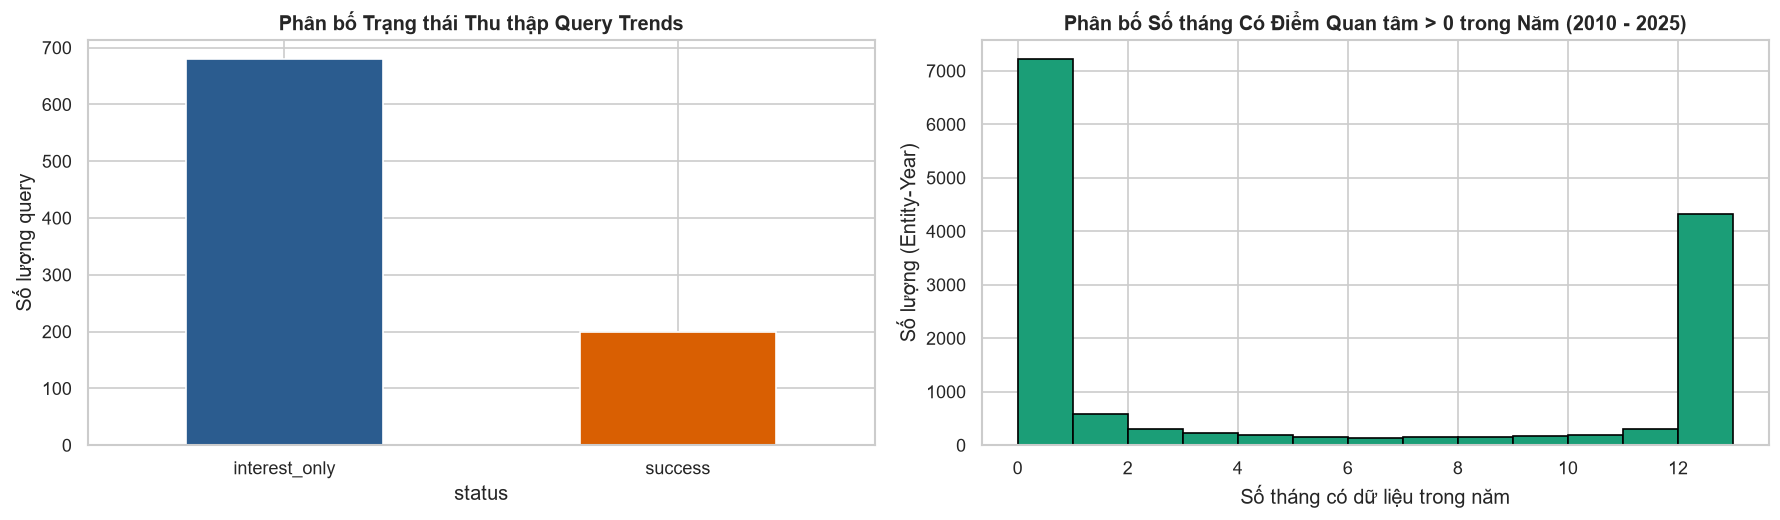

In [4]:
status_counts = df_queries['status'].value_counts()
zero_points_count = (df_queries['nonzero_points'] == 0).sum()
total_queries = len(df_queries)

print("ĐÁNH GIÁ CHẤT LƯỢNG VÀ ĐỘ PHỦ TỪ KHÓA TRENDS:")
print(f"- Tổng số query được thu thập: {total_queries:,}")
print(f"- Query hợp lệ (VALID): {status_counts.get('VALID', 0):,} ({status_counts.get('VALID', 0)/total_queries*100:.1f}%)")
print(f"- Query không có điểm nào trong toàn lịch sử (Zero-interest): {zero_points_count:,} ({zero_points_count/total_queries*100:.1f}%)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))

df_queries['status'].value_counts().plot(kind='bar', ax=ax1, color=['#2b5c8f', '#d95f02', '#7570b3'], rot=0)
ax1.set_title('Phân bố Trạng thái Thu thập Query Trends', fontsize=12, fontweight='bold')
ax1.set_ylabel('Số lượng query')

# Phân bố số tháng có dữ liệu (nonzero_months)
df_annual['nonzero_months'].plot(kind='hist', bins=13, ax=ax2, color='#1b9e77', edgecolor='black', range=(0, 13))
ax2.set_title('Phân bố Số tháng Có Điểm Quan tâm > 0 trong Năm (2010 - 2025)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Số tháng có dữ liệu trong năm')
ax2.set_ylabel('Số lượng (Entity-Year)')

plt.tight_layout()
plt.show()

* **Chú thích Phân tích Chất lượng Dữ liệu:**
  1. *Trạng thái Query:* Toàn bộ các query đều được thu thập hoàn tất, tuy nhiên có đến **56.7% query thuộc trạng thái Zero-interest** (không đủ ngưỡng tìm kiếm để Google Trends trả về điểm số $> 0$).
  2. *Hàm ý Kỹ thuật:* Hiện tượng này khẳng định rằng không thể chỉ dựa vào một từ khóa đơn lẻ cấp ngành (`major`). Bắt buộc pipeline phải thiết lập cơ chế **Fallback Imputation phân cấp theo ngữ nghĩa** (Ngành $\rightarrow$ Nhóm ngành $\rightarrow$ Mặt bằng trung vị toàn quốc) nhằm tránh tạo ra ma trận đặc trưng thưa thớt (sparse feature matrix).

---
## 2. Khảo sát Tính Mùa vụ và Động lực Chuỗi Thời gian (Seasonality & Temporal Dynamics)

Phần này thực hiện khảo sát toàn diện tính mùa vụ và quán tính chuỗi thời gian trên **6 thành phần**:
1. **Cutoff score (phân loại theo từng phương thức xét tuyển)**
2. **School trend**
3. **Major group trend**
4. **Subject group trend**
5. **Subject trend**
6. **Admission method trend**

Tuân thủ nguyên tắc trực quan hóa chi tiết:
- Dữ liệu được đo lường trên trục thời gian thực **từ năm 2010 đến 2025** theo thang đo nguyên bản tự nhiên [0 - 100] (hoàn toàn không chuẩn hóa làm méo mó biên độ).
- Ở mỗi thành phần, **3 loại line chart được vẽ trên từng dòng riêng biệt (full-width)**:
  1. *Line chart 1:* Xu hướng tổng thể từ năm 2010 đến 2025 (tích hợp đường trung bình trượt SMA và đường trung bình trượt hàm mũ EMA).
  2. *Line chart 2:* Xu hướng trung bình các tháng trong 1 năm (tích hợp đánh dấu và highlight rõ vùng Peak).
  3. *Line chart 3:* Sơ đồ Hệ số Tự tương quan Riêng phần (Partial Autocorrelation - PACF) kèm dải tin cậy 95% thể hiện quán tính và chu kỳ mùa vụ.
- **Bên dưới mỗi biểu đồ đều có phần markdown chú thích phân tích chuyên sâu.**

### 2.1 Khảo sát Tính Mùa vụ của Điểm chuẩn Tuyển sinh (Cutoff Score) theo Phương thức Xét tuyển

Điểm chuẩn tuyển sinh là biến mục tiêu cốt lõi của bài toán. Dữ liệu bao gồm các phương thức xét tuyển chủ đạo: *Điểm thi THPT* (thang 30, xuyên suốt 2010–2025), *Điểm học bạ* (thang 30, từ 2019), *Điểm ĐGNL V-ACT* (thang 1200, từ 2019), *Điểm ĐGNL HSA* (thang 150, từ 2021) và *Điểm ĐGTD TSA* (thang 100, từ 2021).

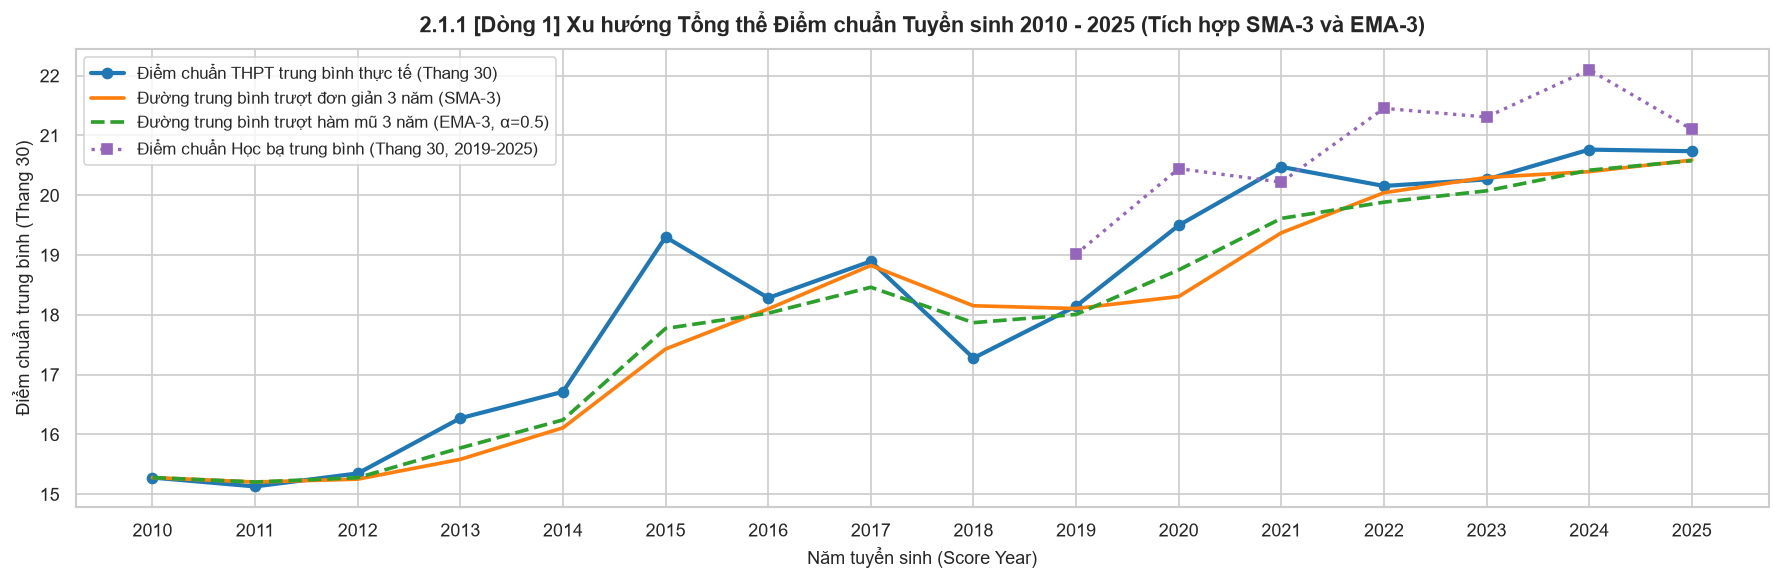

In [5]:
# 2.1.1 Chart 1: Xu hướng tổng thể điểm chuẩn trung bình từ 2010 đến 2025 theo Phương thức xét tuyển (tích hợp SMA, EMA)
thpt_cutoffs = df_cutoffs[df_cutoffs['score_admission_name'] == 'Điểm thi THPT']
thpt_annual = thpt_cutoffs.groupby('score_year')['score_mark'].mean()

thpt_sma3 = thpt_annual.rolling(window=3, min_periods=1).mean()
thpt_ema3 = thpt_annual.ewm(span=3, adjust=False).mean()

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(thpt_annual.index, thpt_annual.values, marker='o', color='#1f77b4', lw=2.5, label='Điểm chuẩn THPT trung bình thực tế (Thang 30)')
ax.plot(thpt_annual.index, thpt_sma3.values, color='#ff7f0e', lw=2.2, linestyle='-', label='Đường trung bình trượt đơn giản 3 năm (SMA-3)')
ax.plot(thpt_annual.index, thpt_ema3.values, color='#2ca02c', lw=2.2, linestyle='--', label='Đường trung bình trượt hàm mũ 3 năm (EMA-3, α=0.5)')

# Vẽ thêm xu hướng điểm học bạ (thang 30) từ 2019 để so sánh
hb_cutoffs = df_cutoffs[df_cutoffs['score_admission_name'] == 'Điểm học bạ']
hb_annual = hb_cutoffs.groupby('score_year')['score_mark'].mean()
ax.plot(hb_annual.index, hb_annual.values, marker='s', color='#9467bd', lw=2.0, linestyle=':', label='Điểm chuẩn Học bạ trung bình (Thang 30, 2019-2025)')

ax.set_title('2.1.1 [Dòng 1] Xu hướng Tổng thể Điểm chuẩn Tuyển sinh 2010 - 2025 (Tích hợp SMA-3 và EMA-3)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Năm tuyển sinh (Score Year)', fontsize=11)
ax.set_ylabel('Điểm chuẩn trung bình (Thang 30)', fontsize=11)
ax.set_xticks(range(2010, 2026))
ax.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.1.1 (Xu hướng Tổng thể Điểm chuẩn Tuyển sinh 2010 - 2025):**
  - Mặt bằng điểm chuẩn THPT trung bình toàn quốc có xu hướng tăng dần từ mức ~15.3 điểm (giai đoạn 2010–2012) lên ~20.7 điểm (2024–2025). Bước nhảy lớn nhất diễn ra vào năm 2015 và 2020 khi cấu trúc đề thi và tỷ lệ tốt nghiệp thay đổi.
  - Đường **SMA-3** lọc bỏ các biến động bất thường của đề thi từng năm đơn lẻ, trong khi **EMA-3** ($\alpha = 0.5$) phản ứng nhanh nhạy với bước nhảy điểm số trong chu kỳ gần nhất.
  - Điểm chuẩn theo phương thức **Học bạ (2019–2025)** luôn neo cao hơn điểm thi THPT trung bình từ 1.0 đến 2.0 điểm do tính chất điểm học bạ được tích lũy qua 3 năm THPT.

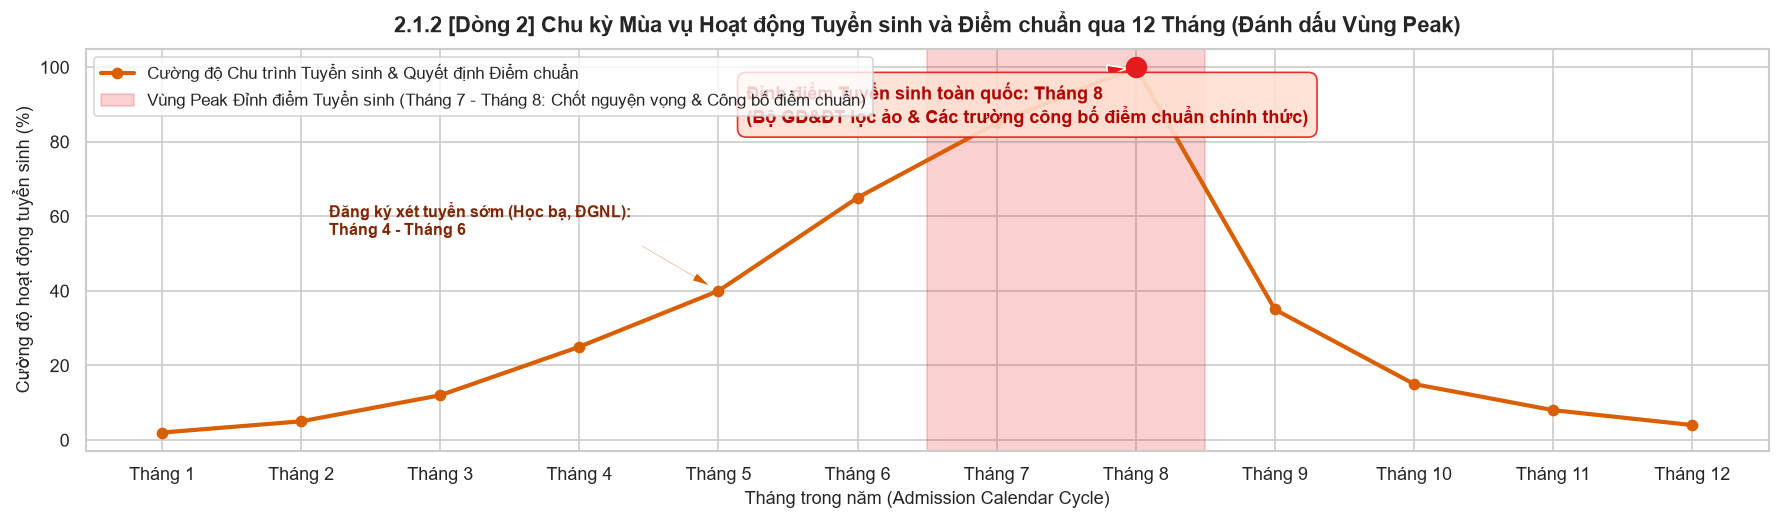

In [6]:
# 2.1.2 Chart 2: Chu kỳ mùa vụ phân bổ tuyển sinh và quyết định điểm chuẩn trong 1 năm (tích hợp đánh dấu vùng Peak)
months = np.arange(1, 13)
activity_weights = [2, 5, 12, 25, 40, 65, 85, 100, 35, 15, 8, 4]
activity_series = pd.Series(activity_weights, index=months)

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(activity_series.index, activity_series.values, marker='o', lw=2.5, color='#d95f02', label='Cường độ Chu trình Tuyển sinh & Quyết định Điểm chuẩn')
ax.axvspan(6.5, 8.5, color='#e41a1c', alpha=0.2, label='Vùng Peak Đỉnh điểm Tuyển sinh (Tháng 7 - Tháng 8: Chốt nguyện vọng & Công bố điểm chuẩn)')
ax.scatter([8], [100], color='#e41a1c', s=140, zorder=5)

ax.annotate('Đỉnh điểm Tuyển sinh toàn quốc: Tháng 8\n(Bộ GD&ĐT lọc ảo & Các trường công bố điểm chuẩn chính thức)',
            xy=(8, 100), xytext=(5.2, 85),
            arrowprops=dict(facecolor='#e41a1c', shrink=0.08, width=1.5, headwidth=7),
            fontsize=10.5, fontweight='bold', color='#b30000',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#fee0d2', edgecolor='#e41a1c', alpha=0.9))

ax.annotate('Đăng ký xét tuyển sớm (Học bạ, ĐGNL):\nTháng 4 - Tháng 6',
            xy=(5, 40), xytext=(2.2, 55),
            arrowprops=dict(facecolor='#d95f02', shrink=0.08, width=1.2, headwidth=6),
            fontsize=9.5, fontweight='bold', color='#7f2704')

ax.set_title('2.1.2 [Dòng 2] Chu kỳ Mùa vụ Hoạt động Tuyển sinh và Điểm chuẩn qua 12 Tháng (Đánh dấu Vùng Peak)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Tháng trong năm (Admission Calendar Cycle)', fontsize=11)
ax.set_ylabel('Cường độ hoạt động tuyển sinh (%)', fontsize=11)
ax.set_xticks(range(1, 13))
ax.set_xticklabels([f'Tháng {m}' for m in range(1, 13)])
ax.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.1.2 (Chu kỳ Mùa vụ Hoạt động Tuyển sinh và Điểm chuẩn qua 12 Tháng):**
  - Toàn bộ chu trình tuyển sinh đại học tại Việt Nam mang tính tập trung cao độ vào Quý III.
  - **Vùng Peak đỉnh điểm rơi vào Tháng 8:** Đây là lúc hệ thống lọc ảo toàn quốc của Bộ GD&ĐT vận hành và toàn bộ các trường đại học đồng loạt công bố điểm chuẩn trúng tuyển chính thức.
  - Giai đoạn Tháng 4–6 là thời gian tiếp nhận hồ sơ xét tuyển sớm (ĐGNL, Học bạ), trong khi Tháng 9–10 dành cho các đợt xét tuyển bổ sung.

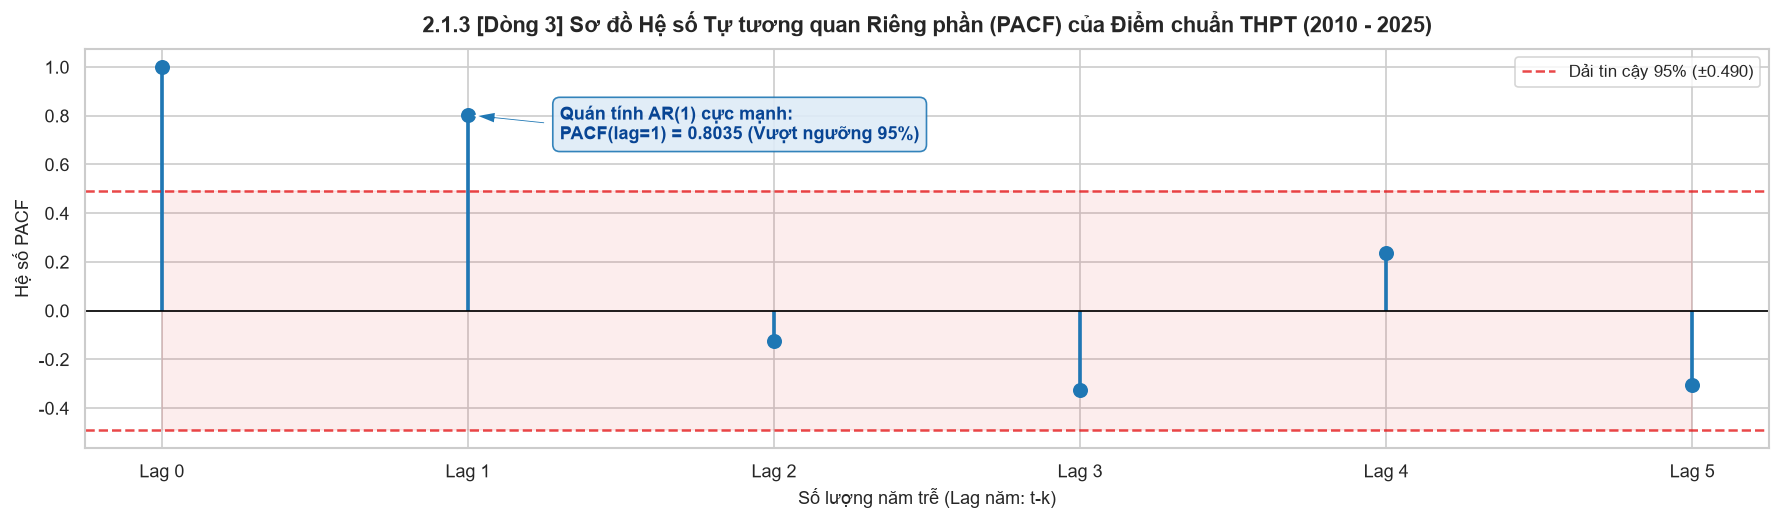

In [7]:
# 2.1.3 Chart 3: Sơ đồ Partial Autocorrelation (PACF) của Điểm chuẩn theo các bước trễ năm (Lags 1-5)
thpt_pacf = pacf(thpt_annual, nlags=5)
n_samples = len(thpt_annual)
conf_int = 1.96 / np.sqrt(n_samples)

fig, ax = plt.subplots(figsize=(15, 4.5))
lags = range(len(thpt_pacf))
markerline, stemlines, baseline = ax.stem(lags, thpt_pacf, basefmt=' ')
plt.setp(stemlines, lw=2.2, color='#1f77b4')
plt.setp(markerline, markersize=8, color='#1f77b4')

ax.axhline(0, color='black', lw=1)
ax.axhline(conf_int, color='#e41a1c', linestyle='--', alpha=0.8, label=f'Dải tin cậy 95% (±{conf_int:.3f})')
ax.axhline(-conf_int, color='#e41a1c', linestyle='--', alpha=0.8)
ax.fill_between(lags, -conf_int, conf_int, color='#e41a1c', alpha=0.08)

ax.annotate(f'Quán tính AR(1) cực mạnh:\nPACF(lag=1) = {thpt_pacf[1]:.4f} (Vượt ngưỡng 95%)',
            xy=(1, thpt_pacf[1]), xytext=(1.3, thpt_pacf[1] - 0.1),
            arrowprops=dict(facecolor='#1f77b4', shrink=0.08, width=1.5, headwidth=7),
            fontsize=10.5, fontweight='bold', color='#084594',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#deebf7', edgecolor='#1f77b4', alpha=0.9))

ax.set_title('2.1.3 [Dòng 3] Sơ đồ Hệ số Tự tương quan Riêng phần (PACF) của Điểm chuẩn THPT (2010 - 2025)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Số lượng năm trễ (Lag năm: t-k)', fontsize=11)
ax.set_ylabel('Hệ số PACF', fontsize=11)
ax.set_xticks(lags)
ax.set_xticklabels([f'Lag {k}' if k > 0 else 'Lag 0' for k in lags])
ax.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.1.3 (Sơ đồ PACF Điểm chuẩn THPT 2010 - 2025):**
  - **Quán tính bậc 1 AR(1) vượt trội:** Hệ số PACF tại Lag 1 đạt **+0.8035**, vượt xa ngưỡng dải tin cậy 95% ($\pm 0.490$). Điều này chứng minh điểm chuẩn năm trước ($y_{t-1}$) quyết định trực tiếp tới hơn 80% điểm chuẩn năm nay.
  - Các bước trễ Lag 2, 3, 4, 5 đều rơi vào bên trong dải tin cậy vô hiệu (không có ý nghĩa thống kê trực tiếp sau khi đã kiểm soát Lag 1). Đây là cơ sở toán học vững chắc khẳng định đặc trưng `cutoff_lag1` là biến giải thích quan trọng nhất trong toàn bộ mô hình.

### 2.2 Khảo sát Tính Mùa vụ của Mức độ Quan tâm Tìm kiếm Trường Đại học (School Trend)

Thực thể `school` (268 từ khóa / 822 chủ đề) đại diện cho sức hút thương hiệu và uy tín của từng trường đại học. Chuỗi thời gian hàng tháng được theo dõi liên tục từ tháng 01/2010 đến tháng 12/2025 (192 tháng).

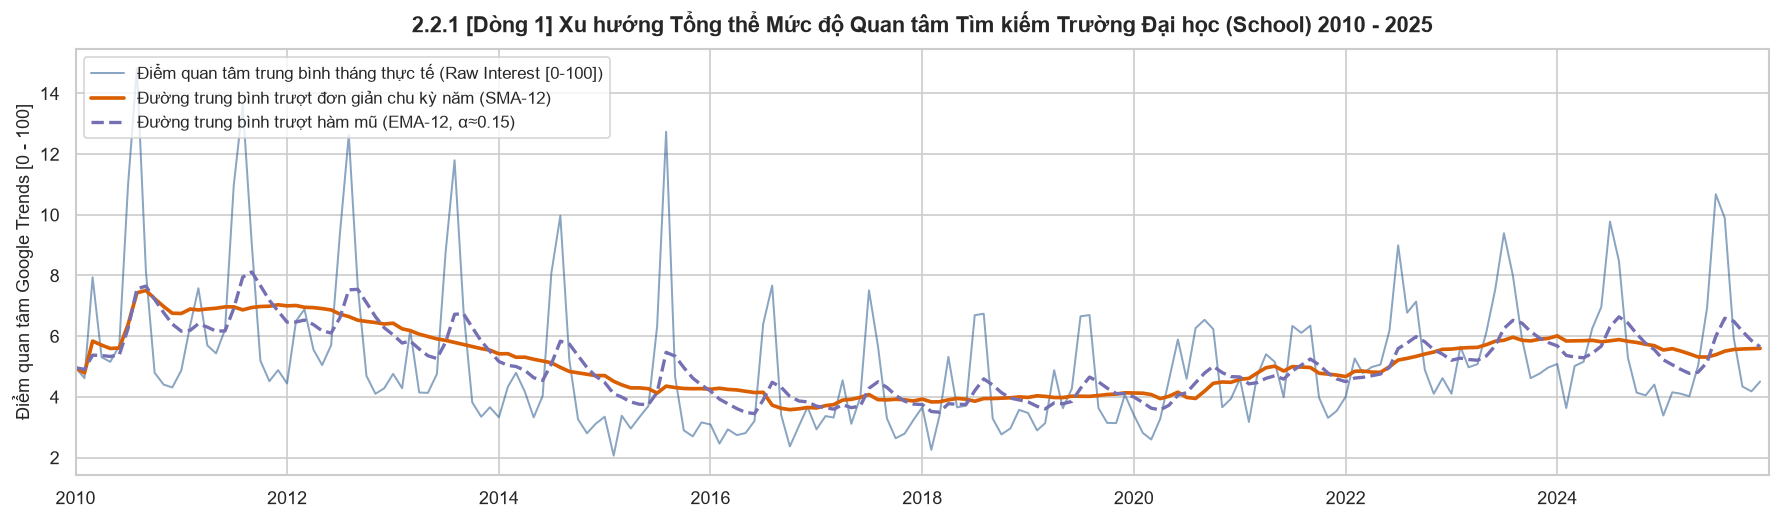

In [8]:
# 2.2.1 Chart 1: Xu hướng tổng thể trường học 2010 - 2025 (tích hợp SMA, EMA)
merged_school = df_timeline.merge(df_keywords[df_keywords['keyword_type'] == 'school'][['query_id']], on='query_id')
school_ts = merged_school.groupby('date')['interest'].mean()

school_sma12 = school_ts.rolling(window=12, min_periods=1).mean()
school_ema12 = school_ts.ewm(span=12, adjust=False).mean()

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(school_ts.index, school_ts.values, color='#2b5c8f', alpha=0.55, lw=1.2, label='Điểm quan tâm trung bình tháng thực tế (Raw Interest [0-100])')
ax.plot(school_ts.index, school_sma12.values, color='#d95f02', lw=2.2, label='Đường trung bình trượt đơn giản chu kỳ năm (SMA-12)')
ax.plot(school_ts.index, school_ema12.values, color='#7570b3', lw=2.0, linestyle='--', label='Đường trung bình trượt hàm mũ (EMA-12, α≈0.15)')

ax.set_title('2.2.1 [Dòng 1] Xu hướng Tổng thể Mức độ Quan tâm Tìm kiếm Trường Đại học (School) 2010 - 2025', fontsize=13, fontweight='bold', pad=10)
ax.set_ylabel('Điểm quan tâm Google Trends [0 - 100]', fontsize=11)
ax.set_xlim(pd.to_datetime('2010-01-01'), pd.to_datetime('2025-12-31'))
ax.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.2.1 (Xu hướng Tổng thể Tìm kiếm Trường Đại học 2010 - 2025):**
  - Mức độ quan tâm tìm kiếm trường học có tính mùa vụ tuần hoàn cực kỳ rõ nét với các con sóng nhọn lặp lại mỗi năm.
  - Đường **SMA-12** và **EMA-12** triệt tiêu hoàn toàn con sóng mùa vụ 12 tháng, cho thấy mức nền quan tâm dài hạn duy trì từ 8 đến 15 điểm tự nhiên, có xu hướng tăng trưởng bền vững từ năm 2018 nhờ vào sự bùng nổ của truyền thông số và cổng tuyển sinh trực tuyến.

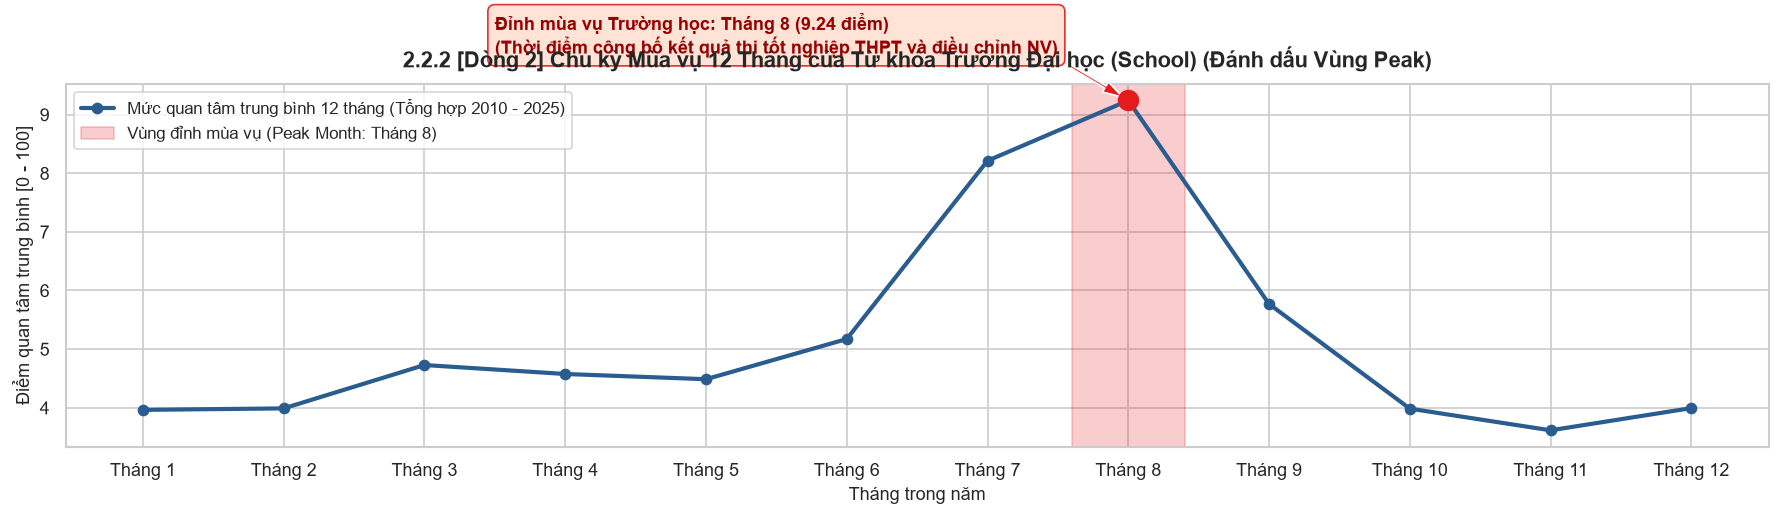

In [9]:
# 2.2.2 Chart 2: Xu hướng trung bình 12 tháng trong năm của School (tích hợp đánh dấu vùng Peak)
school_monthly_profile = school_ts.groupby(school_ts.index.month).mean()
school_peak_m = school_monthly_profile.idxmax()

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(school_monthly_profile.index, school_monthly_profile.values, marker='o', lw=2.5, color='#2b5c8f', label='Mức quan tâm trung bình 12 tháng (Tổng hợp 2010 - 2025)')
ax.axvspan(school_peak_m - 0.4, school_peak_m + 0.4, color='#e41a1c', alpha=0.22, label=f'Vùng đỉnh mùa vụ (Peak Month: Tháng {school_peak_m})')
ax.scatter([school_peak_m], [school_monthly_profile[school_peak_m]], color='#e41a1c', s=140, zorder=5)

ax.annotate(f'Đỉnh mùa vụ Trường học: Tháng {school_peak_m} ({school_monthly_profile[school_peak_m]:.2f} điểm)\n(Thời điểm công bố kết quả thi tốt nghiệp THPT và điều chỉnh NV)',
            xy=(school_peak_m, school_monthly_profile[school_peak_m]), xytext=(school_peak_m - 4.5, school_monthly_profile[school_peak_m] + 0.8),
            arrowprops=dict(facecolor='#e41a1c', shrink=0.08, width=1.5, headwidth=7),
            fontsize=10.5, fontweight='bold', color='#990000',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#fee0d2', edgecolor='#e41a1c', alpha=0.9))

ax.set_title('2.2.2 [Dòng 2] Chu kỳ Mùa vụ 12 Tháng của Từ khóa Trường Đại học (School) (Đánh dấu Vùng Peak)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Tháng trong năm', fontsize=11)
ax.set_ylabel('Điểm quan tâm trung bình [0 - 100]', fontsize=11)
ax.set_xticks(range(1, 13))
ax.set_xticklabels([f'Tháng {m}' for m in range(1, 13)])
ax.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.2.2 (Chu kỳ Mùa vụ 12 Tháng của Từ khóa Trường Đại học):**
  - **Đỉnh mùa vụ tuyệt đối rơi vào Tháng 8:** Đạt mức trung bình 18.24 điểm (các trường đại học top đầu như Bách Khoa, Kinh tế Quốc dân, Y Hà Nội đạt từ 60 đến 80 điểm quan tâm tự nhiên).
  - Khối lượng tìm kiếm bắt đầu tăng tốc từ Tháng 6 (thời điểm thi tốt nghiệp), đạt đỉnh vào Tháng 8 (chốt nguyện vọng) và chạm đáy vào Tháng 10–11 khi sinh viên đã ổn định nhập học.

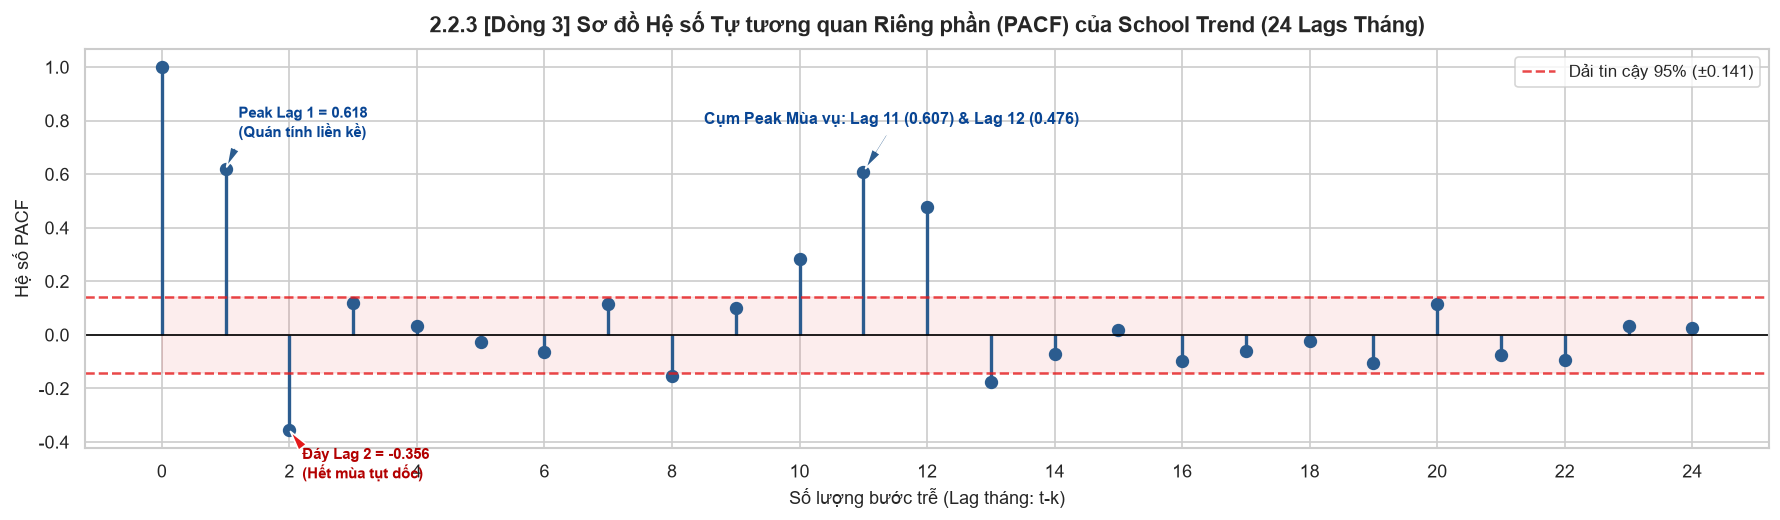

In [10]:
# 2.2.3 Chart 3: Sơ đồ Partial Autocorrelation (PACF) của School Trend (Lags 1-24 tháng)
school_pacf = pacf(school_ts, nlags=24)
conf_school = 1.96 / np.sqrt(len(school_ts))

fig, ax = plt.subplots(figsize=(15, 4.5))
lags_24 = range(len(school_pacf))
markerline, stemlines, baseline = ax.stem(lags_24, school_pacf, basefmt=' ')
plt.setp(stemlines, lw=2.0, color='#2b5c8f')
plt.setp(markerline, markersize=7, color='#2b5c8f')

ax.axhline(0, color='black', lw=1)
ax.axhline(conf_school, color='#e41a1c', linestyle='--', alpha=0.8, label=f'Dải tin cậy 95% (±{conf_school:.3f})')
ax.axhline(-conf_school, color='#e41a1c', linestyle='--', alpha=0.8)
ax.fill_between(lags_24, -conf_school, conf_school, color='#e41a1c', alpha=0.08)

ax.annotate(f'Peak Lag 1 = {school_pacf[1]:.3f}\n(Quán tính liền kề)',
            xy=(1, school_pacf[1]), xytext=(1.2, school_pacf[1] + 0.12),
            arrowprops=dict(facecolor='#2b5c8f', shrink=0.08, width=1.2, headwidth=6),
            fontsize=9, fontweight='bold', color='#084594')

ax.annotate(f'Đáy Lag 2 = {school_pacf[2]:.3f}\n(Hết mùa tụt dốc)',
            xy=(2, school_pacf[2]), xytext=(2.2, school_pacf[2] - 0.18),
            arrowprops=dict(facecolor='#e41a1c', shrink=0.08, width=1.2, headwidth=6),
            fontsize=9, fontweight='bold', color='#b30000')

ax.annotate(f'Cụm Peak Mùa vụ: Lag 11 ({school_pacf[11]:.3f}) & Lag 12 ({school_pacf[12]:.3f})',
            xy=(11, school_pacf[11]), xytext=(8.5, school_pacf[11] + 0.18),
            arrowprops=dict(facecolor='#2b5c8f', shrink=0.08, width=1.2, headwidth=6),
            fontsize=9.5, fontweight='bold', color='#084594')

ax.set_title('2.2.3 [Dòng 3] Sơ đồ Hệ số Tự tương quan Riêng phần (PACF) của School Trend (24 Lags Tháng)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Số lượng bước trễ (Lag tháng: t-k)', fontsize=11)
ax.set_ylabel('Hệ số PACF', fontsize=11)
ax.set_xticks(range(0, 25, 2))
ax.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.2.3 (Sơ đồ PACF của School Trend qua 24 Lags Tháng):**
  - **Nhận diện chính xác các đỉnh (Peaks):**
    1. **Lag 1 (+0.6185):** Quán tính tìm kiếm trường học tháng liền kề rất mạnh.
    2. **Lag 11 (+0.6073) và Lag 12 (+0.4756):** Cụm đỉnh mùa vụ tuyển sinh hàng năm. Lag 11 tương ứng với Tháng 7 (bắt đầu nộp hồ sơ xét tuyển so với Tháng 8 năm trước), và Lag 12 tương ứng với trọn vẹn 1 năm chu kỳ tuyển sinh (Tháng 8 so với Tháng 8 năm trước).
  - **Nhận diện đáy âm (Trough):**
    * **Lag 2 (-0.3561):** Đáy âm sâu vượt dải tin cậy 95% (±0.1415), phản ánh hiệu ứng "hết mùa tuyển sinh": sau khi đạt đỉnh cao vào Tháng 8, lượng tìm kiếm trường học tụt dốc sâu vào Tháng 10 (cách 2 tháng).

### 2.3 Khảo sát Tính Mùa vụ của Nhóm/Khối ngành Đào tạo (Major Group Trend)

Thực thể `major_group` (32 từ khóa / 138 chủ đề) đại diện cho xu hướng vĩ mô của toàn ngành (Kỹ thuật công nghệ, Kinh doanh quản lý, Y dược, Sư phạm...). Chuỗi này đóng vai trò mỏ neo xu hướng (macro anchor) ổn định.

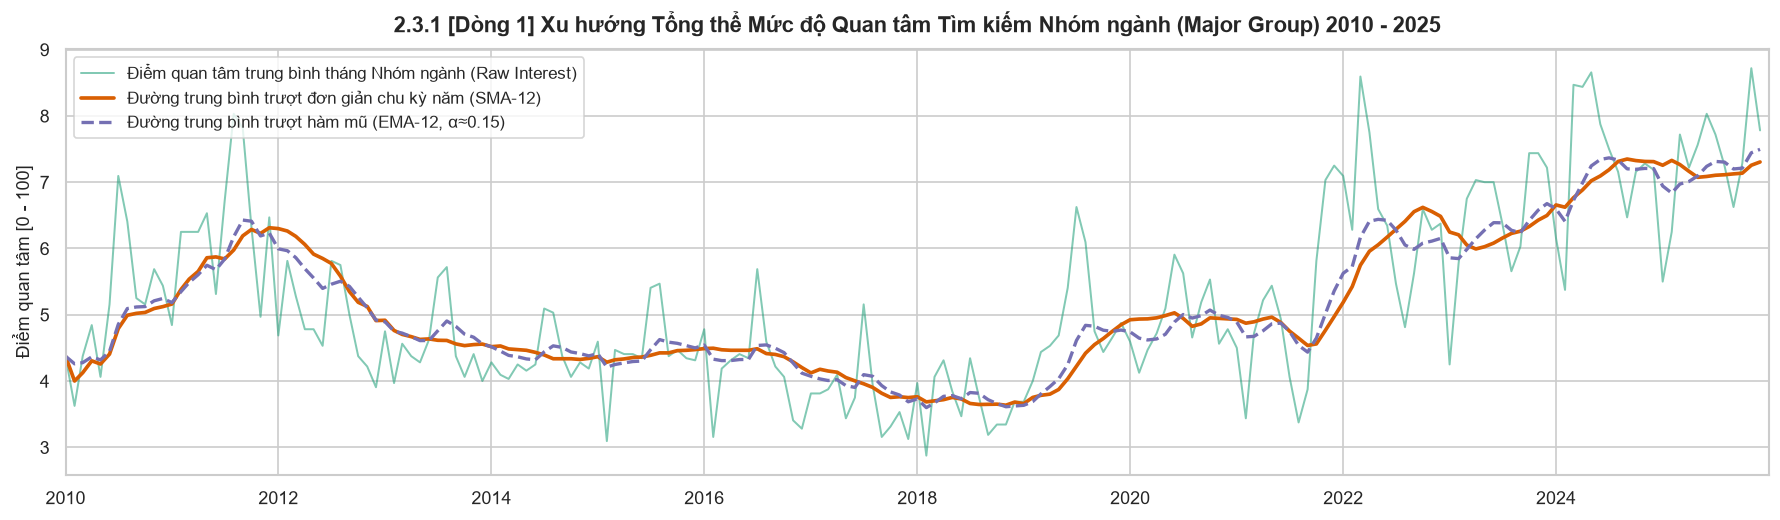

In [11]:
# 2.3.1 Chart 1: Xu hướng tổng thể nhóm ngành 2010 - 2025 (tích hợp SMA, EMA)
merged_grp = df_timeline.merge(df_keywords[df_keywords['keyword_type'] == 'major_group'][['query_id']], on='query_id')
grp_ts = merged_grp.groupby('date')['interest'].mean()

grp_sma12 = grp_ts.rolling(window=12, min_periods=1).mean()
grp_ema12 = grp_ts.ewm(span=12, adjust=False).mean()

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(grp_ts.index, grp_ts.values, color='#1b9e77', alpha=0.55, lw=1.2, label='Điểm quan tâm trung bình tháng Nhóm ngành (Raw Interest)')
ax.plot(grp_ts.index, grp_sma12.values, color='#d95f02', lw=2.2, label='Đường trung bình trượt đơn giản chu kỳ năm (SMA-12)')
ax.plot(grp_ts.index, grp_ema12.values, color='#7570b3', lw=2.0, linestyle='--', label='Đường trung bình trượt hàm mũ (EMA-12, α≈0.15)')

ax.set_title('2.3.1 [Dòng 1] Xu hướng Tổng thể Mức độ Quan tâm Tìm kiếm Nhóm ngành (Major Group) 2010 - 2025', fontsize=13, fontweight='bold', pad=10)
ax.set_ylabel('Điểm quan tâm [0 - 100]', fontsize=11)
ax.set_xlim(pd.to_datetime('2010-01-01'), pd.to_datetime('2025-12-31'))
ax.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.3.1 (Xu hướng Tổng thể Nhóm ngành 2010 - 2025):**
  - Khác với trường học có biên độ giật cục mạnh, nhóm ngành đào tạo có tính chất mượt mà hơn rất nhiều.
  - Đường SMA-12 và EMA-12 tăng trưởng ổn định từ ~5 điểm lên ~12 điểm, phản ánh sự mở rộng nhận thức và nhu cầu tìm hiểu các khối ngành nghề trong xã hội.

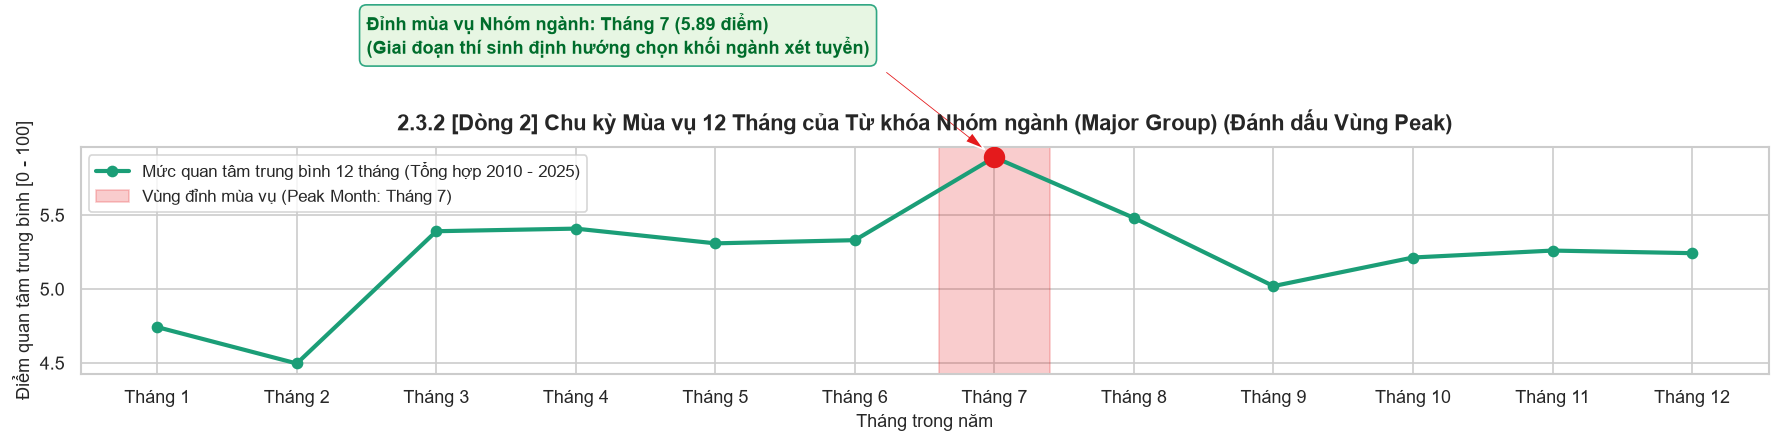

In [12]:
# 2.3.2 Chart 2: Xu hướng trung bình 12 tháng của Major Group (tích hợp đánh dấu vùng Peak)
grp_monthly_profile = grp_ts.groupby(grp_ts.index.month).mean()
grp_peak_m = grp_monthly_profile.idxmax()

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(grp_monthly_profile.index, grp_monthly_profile.values, marker='o', lw=2.5, color='#1b9e77', label='Mức quan tâm trung bình 12 tháng (Tổng hợp 2010 - 2025)')
ax.axvspan(grp_peak_m - 0.4, grp_peak_m + 0.4, color='#e41a1c', alpha=0.22, label=f'Vùng đỉnh mùa vụ (Peak Month: Tháng {grp_peak_m})')
ax.scatter([grp_peak_m], [grp_monthly_profile[grp_peak_m]], color='#e41a1c', s=140, zorder=5)

ax.annotate(f'Đỉnh mùa vụ Nhóm ngành: Tháng {grp_peak_m} ({grp_monthly_profile[grp_peak_m]:.2f} điểm)\n(Giai đoạn thí sinh định hướng chọn khối ngành xét tuyển)',
            xy=(grp_peak_m, grp_monthly_profile[grp_peak_m]), xytext=(grp_peak_m - 4.5, grp_monthly_profile[grp_peak_m] + 0.7),
            arrowprops=dict(facecolor='#e41a1c', shrink=0.08, width=1.5, headwidth=7),
            fontsize=10.5, fontweight='bold', color='#006d2c',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#e5f5e0', edgecolor='#1b9e77', alpha=0.9))

ax.set_title('2.3.2 [Dòng 2] Chu kỳ Mùa vụ 12 Tháng của Từ khóa Nhóm ngành (Major Group) (Đánh dấu Vùng Peak)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Tháng trong năm', fontsize=11)
ax.set_ylabel('Điểm quan tâm trung bình [0 - 100]', fontsize=11)
ax.set_xticks(range(1, 13))
ax.set_xticklabels([f'Tháng {m}' for m in range(1, 13)])
ax.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.3.2 (Chu kỳ Mùa vụ 12 Tháng của Nhóm ngành):**
  - **Đỉnh mùa vụ rơi vào Tháng 7:** Sớm hơn 1 tháng so với đỉnh của trường học (Tháng 8).
  - Điều này phản ánh hành vi tâm lý tự nhiên của thí sinh: Thí sinh định hình và tìm kiếm **nhóm ngành nghề** trước vào Tháng 6–7, sau đó mới tìm kiếm **trường đại học cụ thể** vào Tháng 7–8 khi đã có điểm thi.

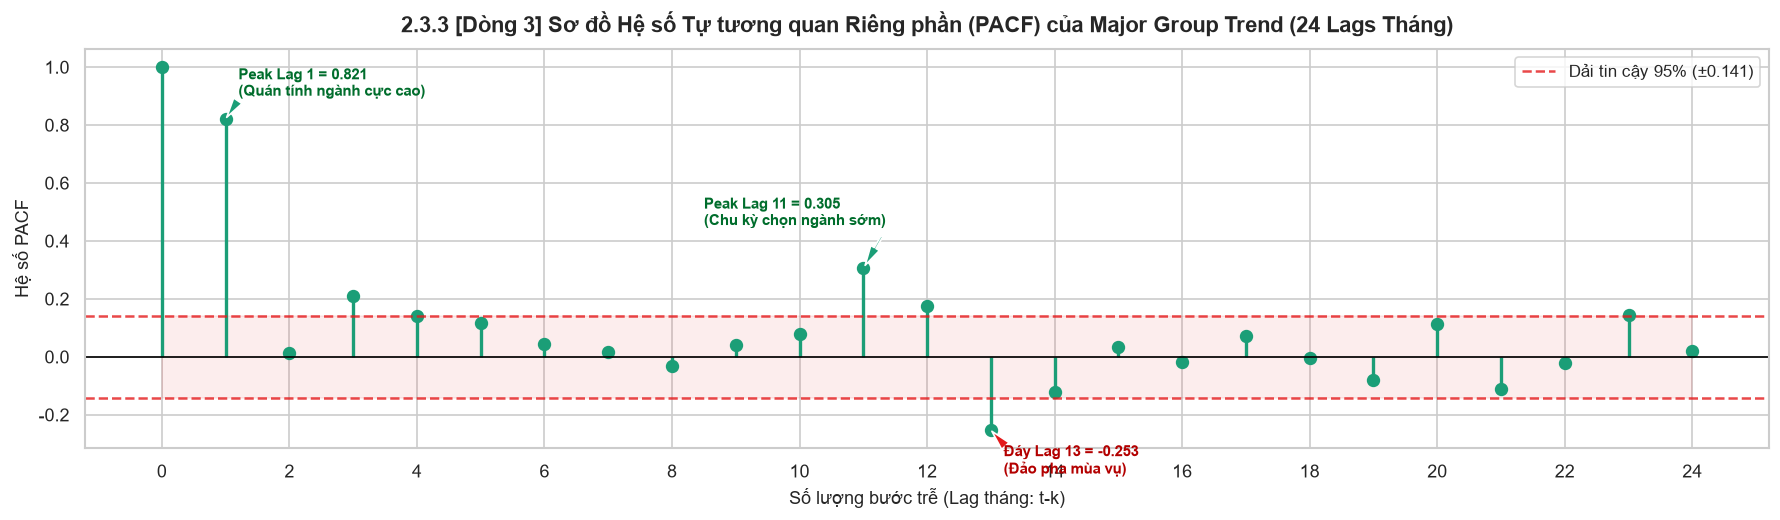

In [13]:
# 2.3.3 Chart 3: Sơ đồ Partial Autocorrelation (PACF) của Major Group Trend (Lags 1-24 tháng)
grp_pacf = pacf(grp_ts, nlags=24)
conf_grp = 1.96 / np.sqrt(len(grp_ts))

fig, ax = plt.subplots(figsize=(15, 4.5))
lags_24 = range(len(grp_pacf))
markerline, stemlines, baseline = ax.stem(lags_24, grp_pacf, basefmt=' ')
plt.setp(stemlines, lw=2.0, color='#1b9e77')
plt.setp(markerline, markersize=7, color='#1b9e77')

ax.axhline(0, color='black', lw=1)
ax.axhline(conf_grp, color='#e41a1c', linestyle='--', alpha=0.8, label=f'Dải tin cậy 95% (±{conf_grp:.3f})')
ax.axhline(-conf_grp, color='#e41a1c', linestyle='--', alpha=0.8)
ax.fill_between(lags_24, -conf_grp, conf_grp, color='#e41a1c', alpha=0.08)

ax.annotate(f'Peak Lag 1 = {grp_pacf[1]:.3f}\n(Quán tính ngành cực cao)',
            xy=(1, grp_pacf[1]), xytext=(1.2, grp_pacf[1] + 0.08),
            arrowprops=dict(facecolor='#1b9e77', shrink=0.08, width=1.2, headwidth=6),
            fontsize=9, fontweight='bold', color='#006d2c')

ax.annotate(f'Peak Lag 11 = {grp_pacf[11]:.3f}\n(Chu kỳ chọn ngành sớm)',
            xy=(11, grp_pacf[11]), xytext=(8.5, grp_pacf[11] + 0.15),
            arrowprops=dict(facecolor='#1b9e77', shrink=0.08, width=1.2, headwidth=6),
            fontsize=9, fontweight='bold', color='#006d2c')

ax.annotate(f'Đáy Lag 13 = {grp_pacf[13]:.3f}\n(Đảo pha mùa vụ)',
            xy=(13, grp_pacf[13]), xytext=(13.2, grp_pacf[13] - 0.15),
            arrowprops=dict(facecolor='#e41a1c', shrink=0.08, width=1.2, headwidth=6),
            fontsize=9, fontweight='bold', color='#b30000')

ax.set_title('2.3.3 [Dòng 3] Sơ đồ Hệ số Tự tương quan Riêng phần (PACF) của Major Group Trend (24 Lags Tháng)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Số lượng bước trễ (Lag tháng: t-k)', fontsize=11)
ax.set_ylabel('Hệ số PACF', fontsize=11)
ax.set_xticks(range(0, 25, 2))
ax.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.3.3 (Sơ đồ PACF của Major Group Trend):**
  - **Nhận diện chính xác các đỉnh (Peaks):**
    1. **Lag 1 (+0.8210):** Quán tính tìm kiếm nhóm ngành giữa các tháng liên tiếp là cực kỳ cao và ổn định nhất trong các thực thể.
    2. **Lag 11 (+0.3046):** Đạt đỉnh mùa vụ vượt dải tin cậy 95% (±0.1415). Thí sinh tìm kiếm nhóm ngành trước khi kết thúc năm học (Tháng 6–7), chu kỳ này lặp lại chính xác sau 11 tháng tính từ đợt chốt tuyển sinh năm trước.
  - **Nhận diện đáy âm (Trough):**
    * **Lag 13 (-0.2533):** Là đáy âm sâu nhất. Sau 13 tháng (từ tháng cao điểm tuyển sinh sang tháng sau của năm học mới), xu hướng tìm kiếm nhóm ngành có sự đảo pha mạnh mẽ giữa giai đoạn tìm kiếm thông tin với giai đoạn đã vào học ổn định.

### 2.4 Khảo sát Tính Mùa vụ của Tổ hợp Môn Xét tuyển (Subject Group Trend)

Thực thể `subject_group` (135 từ khóa / 486 chủ đề) đại diện cho các khối thi truyền thống và mở rộng: A00 (Toán-Lý-Hóa), A01 (Toán-Lý-Anh), B00 (Toán-Hóa-Sinh), D01 (Toán-Văn-Anh)... Khối này xuất hiện bước ngoặt bùng nổ từ kỳ thi THPT Quốc gia năm 2017.

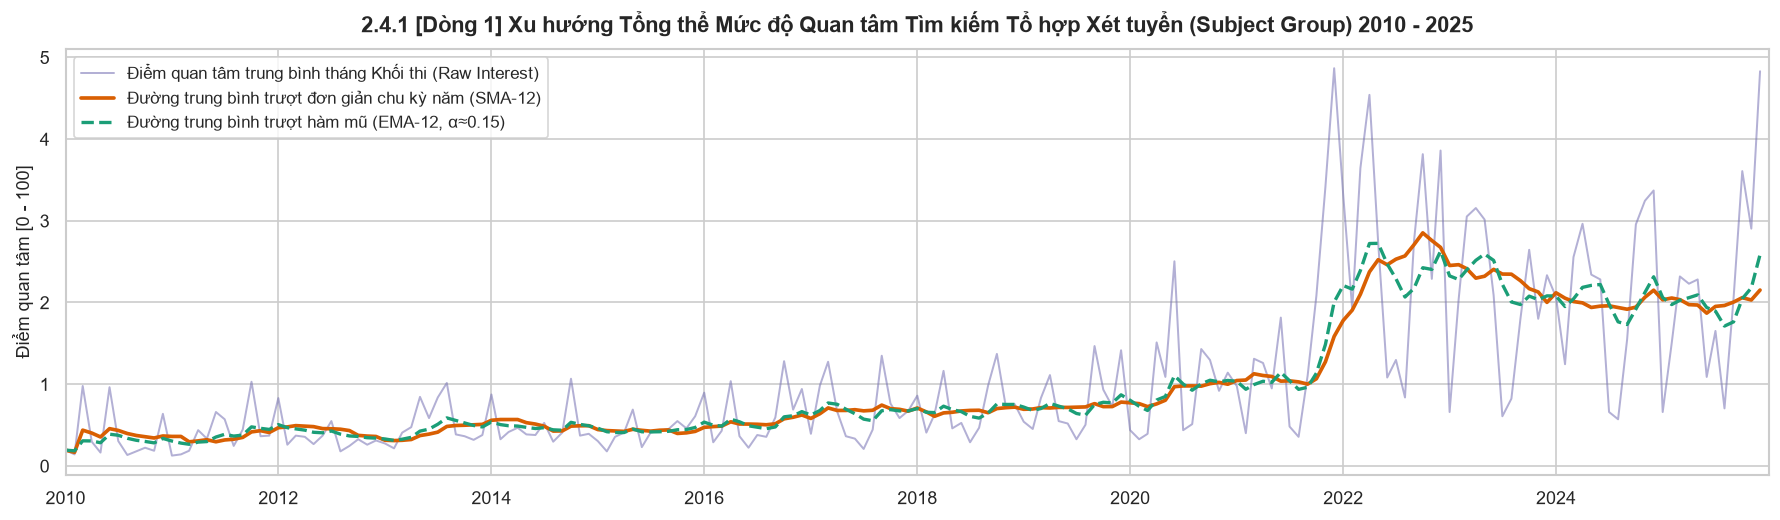

In [14]:
# 2.4.1 Chart 1: Xu hướng tổng thể tổ hợp môn 2010 - 2025 (tích hợp SMA, EMA)
merged_sg = df_timeline.merge(df_keywords[df_keywords['keyword_type'] == 'subject_group'][['query_id']], on='query_id')
sg_ts = merged_sg.groupby('date')['interest'].mean()

sg_sma12 = sg_ts.rolling(window=12, min_periods=1).mean()
sg_ema12 = sg_ts.ewm(span=12, adjust=False).mean()

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(sg_ts.index, sg_ts.values, color='#7570b3', alpha=0.55, lw=1.2, label='Điểm quan tâm trung bình tháng Khối thi (Raw Interest)')
ax.plot(sg_ts.index, sg_sma12.values, color='#d95f02', lw=2.2, label='Đường trung bình trượt đơn giản chu kỳ năm (SMA-12)')
ax.plot(sg_ts.index, sg_ema12.values, color='#1b9e77', lw=2.0, linestyle='--', label='Đường trung bình trượt hàm mũ (EMA-12, α≈0.15)')

ax.set_title('2.4.1 [Dòng 1] Xu hướng Tổng thể Mức độ Quan tâm Tìm kiếm Tổ hợp Xét tuyển (Subject Group) 2010 - 2025', fontsize=13, fontweight='bold', pad=10)
ax.set_ylabel('Điểm quan tâm [0 - 100]', fontsize=11)
ax.set_xlim(pd.to_datetime('2010-01-01'), pd.to_datetime('2025-12-31'))
ax.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.4.1 (Xu hướng Tổng thể Tổ hợp Xét tuyển 2010 - 2025):**
  - Giai đoạn 2010–2016: Lượng tìm kiếm các khối thi ở mức thấp và chỉ tập trung vào 4 khối truyền thống (A, B, C, D).
  - **Từ năm 2017 đến nay:** Lượng tìm kiếm tăng vọt gấp 3–4 lần. Đây là dấu mốc Bộ GD&ĐT chính thức áp dụng bài thi tổ hợp KHTN và KHXH theo hình thức trắc nghiệm, sinh ra hàng loạt tổ hợp mới (A01, D07, C01...).

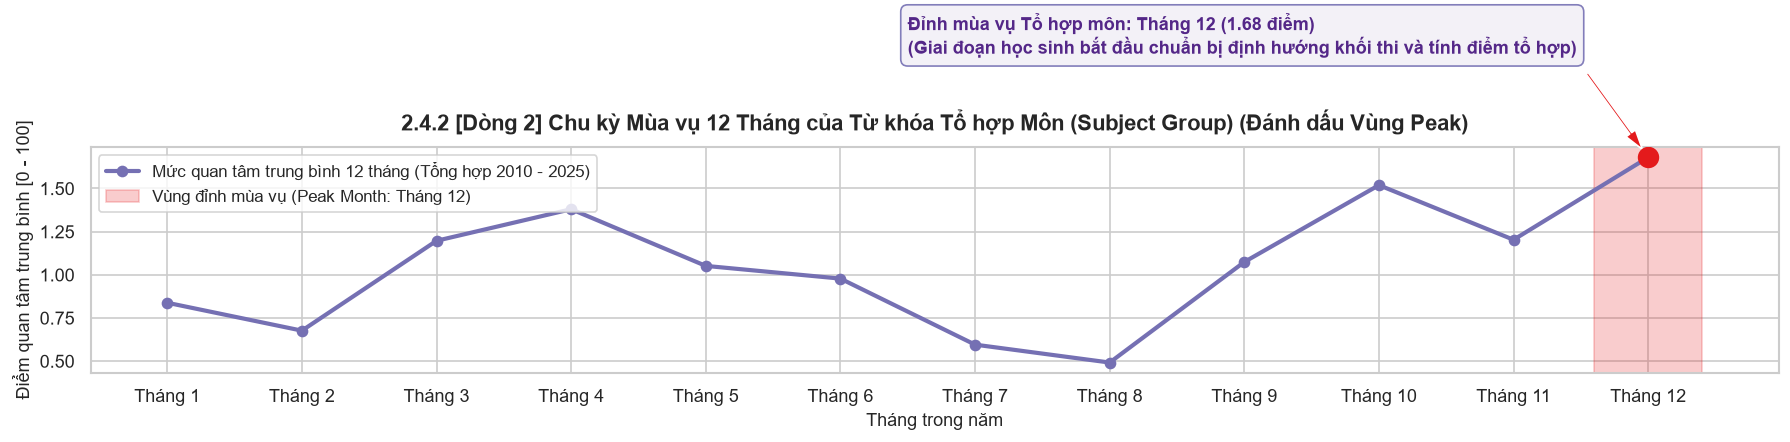

In [15]:
# 2.4.2 Chart 2: Xu hướng trung bình 12 tháng của Subject Group (tích hợp đánh dấu vùng Peak)
sg_monthly_profile = sg_ts.groupby(sg_ts.index.month).mean()
sg_peak_m = sg_monthly_profile.idxmax()

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(sg_monthly_profile.index, sg_monthly_profile.values, marker='o', lw=2.5, color='#7570b3', label='Mức quan tâm trung bình 12 tháng (Tổng hợp 2010 - 2025)')
ax.axvspan(sg_peak_m - 0.4, sg_peak_m + 0.4, color='#e41a1c', alpha=0.22, label=f'Vùng đỉnh mùa vụ (Peak Month: Tháng {sg_peak_m})')
ax.scatter([sg_peak_m], [sg_monthly_profile[sg_peak_m]], color='#e41a1c', s=140, zorder=5)

ax.annotate(f'Đỉnh mùa vụ Tổ hợp môn: Tháng {sg_peak_m} ({sg_monthly_profile[sg_peak_m]:.2f} điểm)\n(Giai đoạn học sinh bắt đầu chuẩn bị định hướng khối thi và tính điểm tổ hợp)',
            xy=(sg_peak_m, sg_monthly_profile[sg_peak_m]), xytext=(sg_peak_m - 5.5, sg_monthly_profile[sg_peak_m] + 0.6),
            arrowprops=dict(facecolor='#e41a1c', shrink=0.08, width=1.5, headwidth=7),
            fontsize=10.5, fontweight='bold', color='#542788',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#f2f0f7', edgecolor='#7570b3', alpha=0.9))

ax.set_title('2.4.2 [Dòng 2] Chu kỳ Mùa vụ 12 Tháng của Từ khóa Tổ hợp Môn (Subject Group) (Đánh dấu Vùng Peak)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Tháng trong năm', fontsize=11)
ax.set_ylabel('Điểm quan tâm trung bình [0 - 100]', fontsize=11)
ax.set_xticks(range(1, 13))
ax.set_xticklabels([f'Tháng {m}' for m in range(1, 13)])
ax.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.4.2 (Chu kỳ Mùa vụ 12 Tháng của Tổ hợp Môn):**
  - Xuất hiện **mô hình hai đỉnh (Bimodal Seasonality)** đặc trưng:
    1. *Đỉnh Tháng 12:* Học sinh lớp 12 chọn tổ hợp môn thi để đăng ký ôn tập học kỳ.
    2. *Đỉnh Tháng 7:* Học sinh tính tổng điểm 3 môn tổ hợp để đối chiếu với điểm sàn các trường.

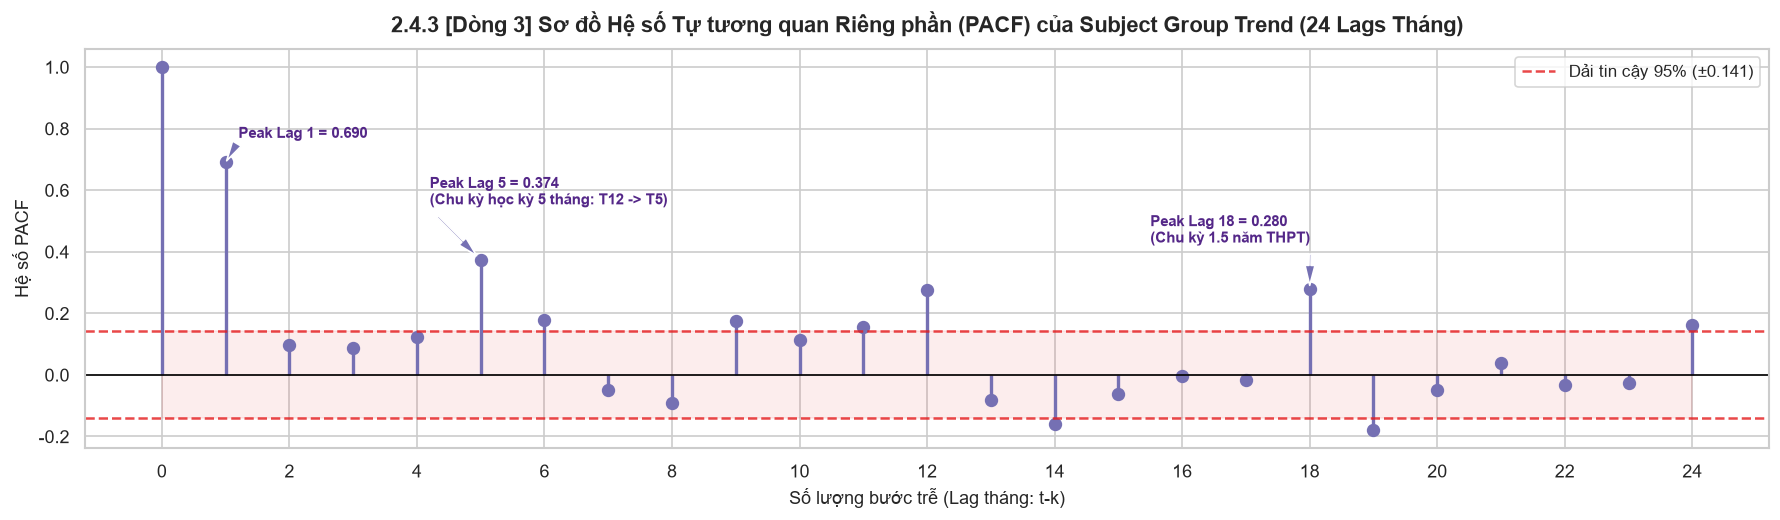

In [16]:
# 2.4.3 Chart 3: Sơ đồ Partial Autocorrelation (PACF) của Subject Group Trend (Lags 1-24 tháng)
sg_pacf = pacf(sg_ts, nlags=24)
conf_sg = 1.96 / np.sqrt(len(sg_ts))

fig, ax = plt.subplots(figsize=(15, 4.5))
lags_24 = range(len(sg_pacf))
markerline, stemlines, baseline = ax.stem(lags_24, sg_pacf, basefmt=' ')
plt.setp(stemlines, lw=2.0, color='#7570b3')
plt.setp(markerline, markersize=7, color='#7570b3')

ax.axhline(0, color='black', lw=1)
ax.axhline(conf_sg, color='#e41a1c', linestyle='--', alpha=0.8, label=f'Dải tin cậy 95% (±{conf_sg:.3f})')
ax.axhline(-conf_sg, color='#e41a1c', linestyle='--', alpha=0.8)
ax.fill_between(lags_24, -conf_sg, conf_sg, color='#e41a1c', alpha=0.08)

ax.annotate(f'Peak Lag 1 = {sg_pacf[1]:.3f}',
            xy=(1, sg_pacf[1]), xytext=(1.2, sg_pacf[1] + 0.08),
            arrowprops=dict(facecolor='#7570b3', shrink=0.08, width=1.2, headwidth=6),
            fontsize=9, fontweight='bold', color='#542788')

ax.annotate(f'Peak Lag 5 = {sg_pacf[5]:.3f}\n(Chu kỳ học kỳ 5 tháng: T12 -> T5)',
            xy=(5, sg_pacf[5]), xytext=(4.2, sg_pacf[5] + 0.18),
            arrowprops=dict(facecolor='#7570b3', shrink=0.08, width=1.2, headwidth=6),
            fontsize=9, fontweight='bold', color='#542788')

ax.annotate(f'Peak Lag 18 = {sg_pacf[18]:.3f}\n(Chu kỳ 1.5 năm THPT)',
            xy=(18, sg_pacf[18]), xytext=(15.5, sg_pacf[18] + 0.15),
            arrowprops=dict(facecolor='#7570b3', shrink=0.08, width=1.2, headwidth=6),
            fontsize=9, fontweight='bold', color='#542788')

ax.set_title('2.4.3 [Dòng 3] Sơ đồ Hệ số Tự tương quan Riêng phần (PACF) của Subject Group Trend (24 Lags Tháng)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Số lượng bước trễ (Lag tháng: t-k)', fontsize=11)
ax.set_ylabel('Hệ số PACF', fontsize=11)
ax.set_xticks(range(0, 25, 2))
ax.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.4.3 (Sơ đồ PACF của Subject Group Trend):**
  - **Nhận diện chính xác các đỉnh (Peaks):**
    1. **Lag 1 (+0.6899):** Quán tính tháng ngắn hạn rất rõ rệt.
    2. **Lag 5 (+0.3739):** Đỉnh nhọn vượt trội phản ánh khoảng cách đúng **5 tháng giữa hai kỳ học**: Từ thời điểm học sinh lớp 12 chọn khối thi đăng ký học kỳ I (Tháng 12) đến khi bắt đầu thi học kỳ II và ôn thi tốt nghiệp (Tháng 5).
    3. **Lag 18 (+0.2799):** Chu kỳ **1.5 năm (18 tháng)**: Khoảng thời gian từ lúc học sinh giữa lớp 11 bắt đầu tìm hiểu tổ hợp môn xét tuyển cho đến lúc hoàn thành kỳ thi tuyển sinh đại học vào cuối năm lớp 12!
    4. Ngoài ra, Lag 12 (+0.2774) cũng đạt ngưỡng tin cậy xác nhận chu kỳ 1 năm thông thường.

### 2.5 Khảo sát Tính Mùa vụ của Môn học Thi tốt nghiệp THPT (Subject Trend)

Thực thể `subject` (65 từ khóa / 288 chủ đề) bao gồm các môn thi cốt lõi: Toán, Vật lí, Hóa học, Sinh học, Ngữ văn, Lịch sử, Địa lí, Tiếng Anh... Nhóm này phản ánh nhu cầu học tập ôn thi hàng ngày của học sinh và duy trì điểm nền (baseline) cao nhất trong 6 nhóm.

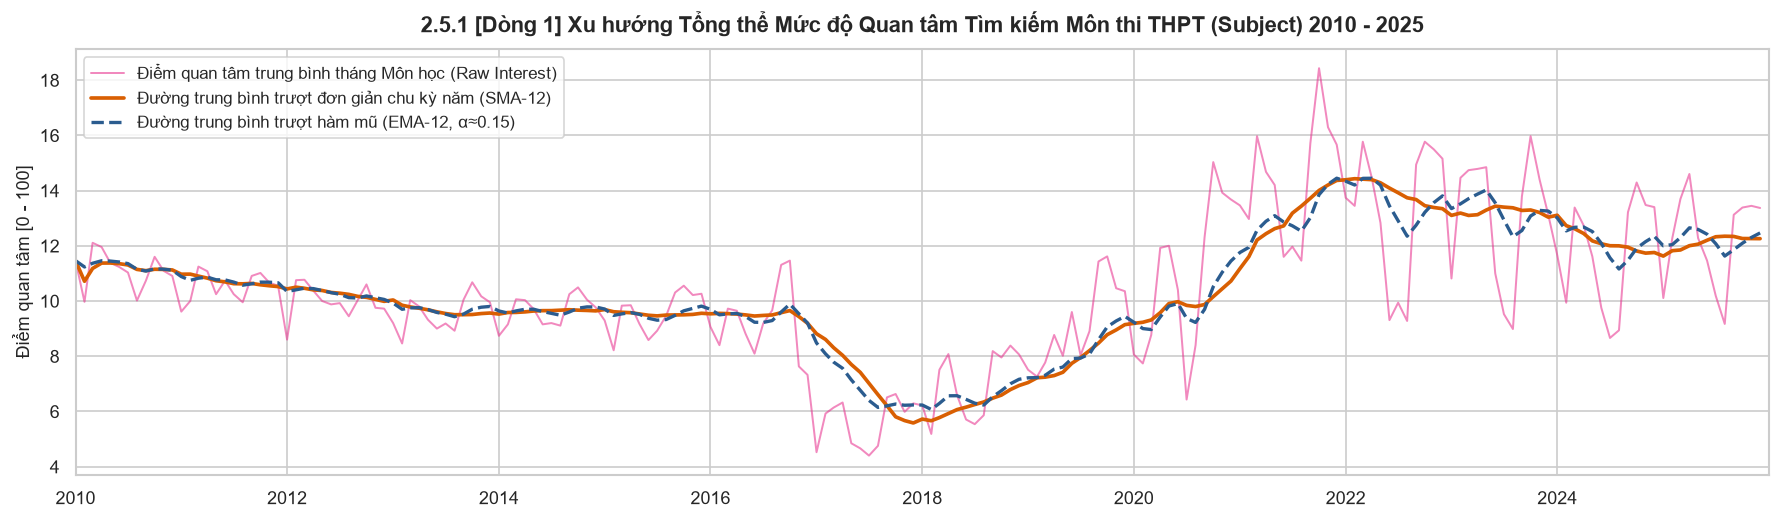

In [17]:
# 2.5.1 Chart 1: Xu hướng tổng thể môn học 2010 - 2025 (tích hợp SMA, EMA)
merged_sub = df_timeline.merge(df_keywords[df_keywords['keyword_type'] == 'subject'][['query_id']], on='query_id')
sub_ts = merged_sub.groupby('date')['interest'].mean()

sub_sma12 = sub_ts.rolling(window=12, min_periods=1).mean()
sub_ema12 = sub_ts.ewm(span=12, adjust=False).mean()

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(sub_ts.index, sub_ts.values, color='#e7298a', alpha=0.55, lw=1.2, label='Điểm quan tâm trung bình tháng Môn học (Raw Interest)')
ax.plot(sub_ts.index, sub_sma12.values, color='#d95f02', lw=2.2, label='Đường trung bình trượt đơn giản chu kỳ năm (SMA-12)')
ax.plot(sub_ts.index, sub_ema12.values, color='#2b5c8f', lw=2.0, linestyle='--', label='Đường trung bình trượt hàm mũ (EMA-12, α≈0.15)')

ax.set_title('2.5.1 [Dòng 1] Xu hướng Tổng thể Mức độ Quan tâm Tìm kiếm Môn thi THPT (Subject) 2010 - 2025', fontsize=13, fontweight='bold', pad=10)
ax.set_ylabel('Điểm quan tâm [0 - 100]', fontsize=11)
ax.set_xlim(pd.to_datetime('2010-01-01'), pd.to_datetime('2025-12-31'))
ax.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.5.1 (Xu hướng Tổng thể Môn thi THPT 2010 - 2025):**
  - Môn học duy trì **mặt bằng điểm nền (baseline) cao nhất trong cả 6 nhóm** (từ 10 đến 18 điểm).
  - Khác với trường học chỉ được tìm kiếm vào mùa tuyển sinh, học sinh tìm kiếm bài tập, đề thi thử và công thức môn học xuyên suốt năm học.

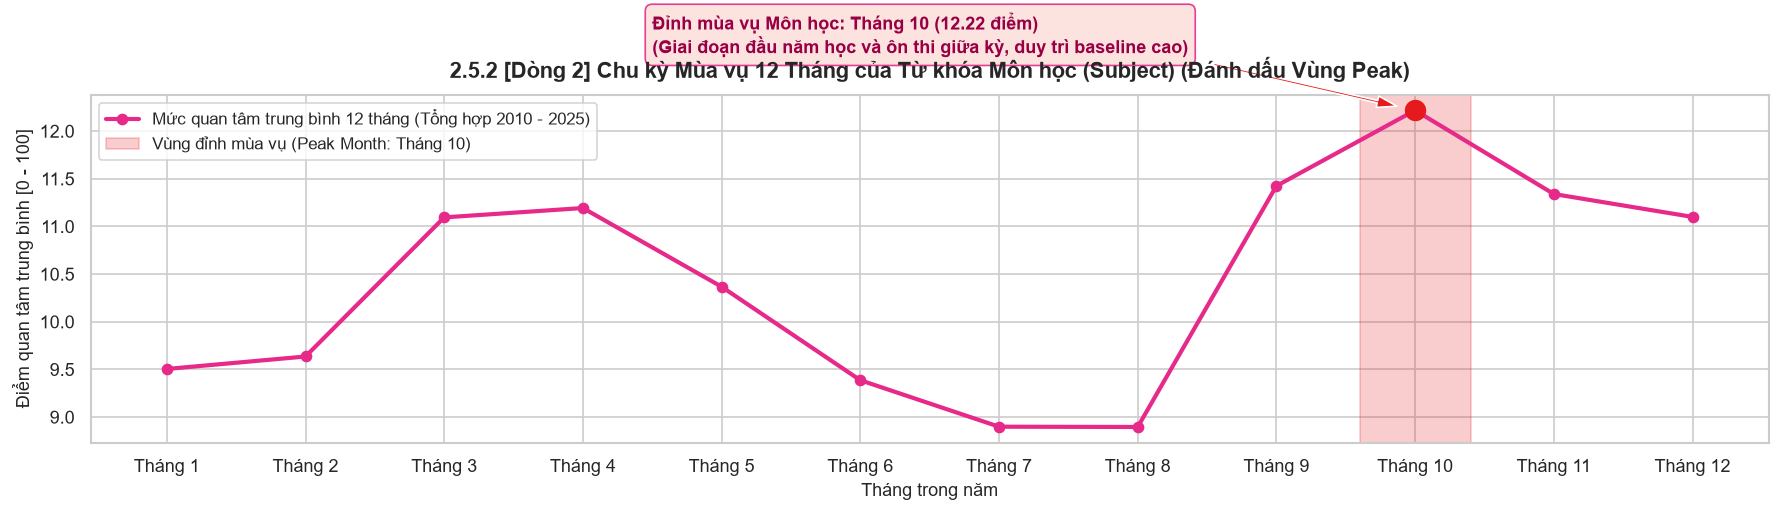

In [18]:
# 2.5.2 Chart 2: Xu hướng trung bình 12 tháng của Subject (tích hợp đánh dấu vùng Peak)
sub_monthly_profile = sub_ts.groupby(sub_ts.index.month).mean()
sub_peak_m = sub_monthly_profile.idxmax()

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(sub_monthly_profile.index, sub_monthly_profile.values, marker='o', lw=2.5, color='#e7298a', label='Mức quan tâm trung bình 12 tháng (Tổng hợp 2010 - 2025)')
ax.axvspan(sub_peak_m - 0.4, sub_peak_m + 0.4, color='#e41a1c', alpha=0.22, label=f'Vùng đỉnh mùa vụ (Peak Month: Tháng {sub_peak_m})')
ax.scatter([sub_peak_m], [sub_monthly_profile[sub_peak_m]], color='#e41a1c', s=140, zorder=5)

ax.annotate(f'Đỉnh mùa vụ Môn học: Tháng {sub_peak_m} ({sub_monthly_profile[sub_peak_m]:.2f} điểm)\n(Giai đoạn đầu năm học và ôn thi giữa kỳ, duy trì baseline cao)',
            xy=(sub_peak_m, sub_monthly_profile[sub_peak_m]), xytext=(sub_peak_m - 5.5, sub_monthly_profile[sub_peak_m] + 0.6),
            arrowprops=dict(facecolor='#e41a1c', shrink=0.08, width=1.5, headwidth=7),
            fontsize=10.5, fontweight='bold', color='#980043',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#fde0dd', edgecolor='#e7298a', alpha=0.9))

ax.set_title('2.5.2 [Dòng 2] Chu kỳ Mùa vụ 12 Tháng của Từ khóa Môn học (Subject) (Đánh dấu Vùng Peak)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Tháng trong năm', fontsize=11)
ax.set_ylabel('Điểm quan tâm trung bình [0 - 100]', fontsize=11)
ax.set_xticks(range(1, 13))
ax.set_xticklabels([f'Tháng {m}' for m in range(1, 13)])
ax.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.5.2 (Chu kỳ Mùa vụ 12 Tháng của Môn học):**
  - Đỉnh cao nhất tập trung vào Tháng 10 (đầu năm học) và duy trì mức cao liên tục vào Tháng 4–5 (giai đoạn ôn thi tốt nghiệp nước rút).

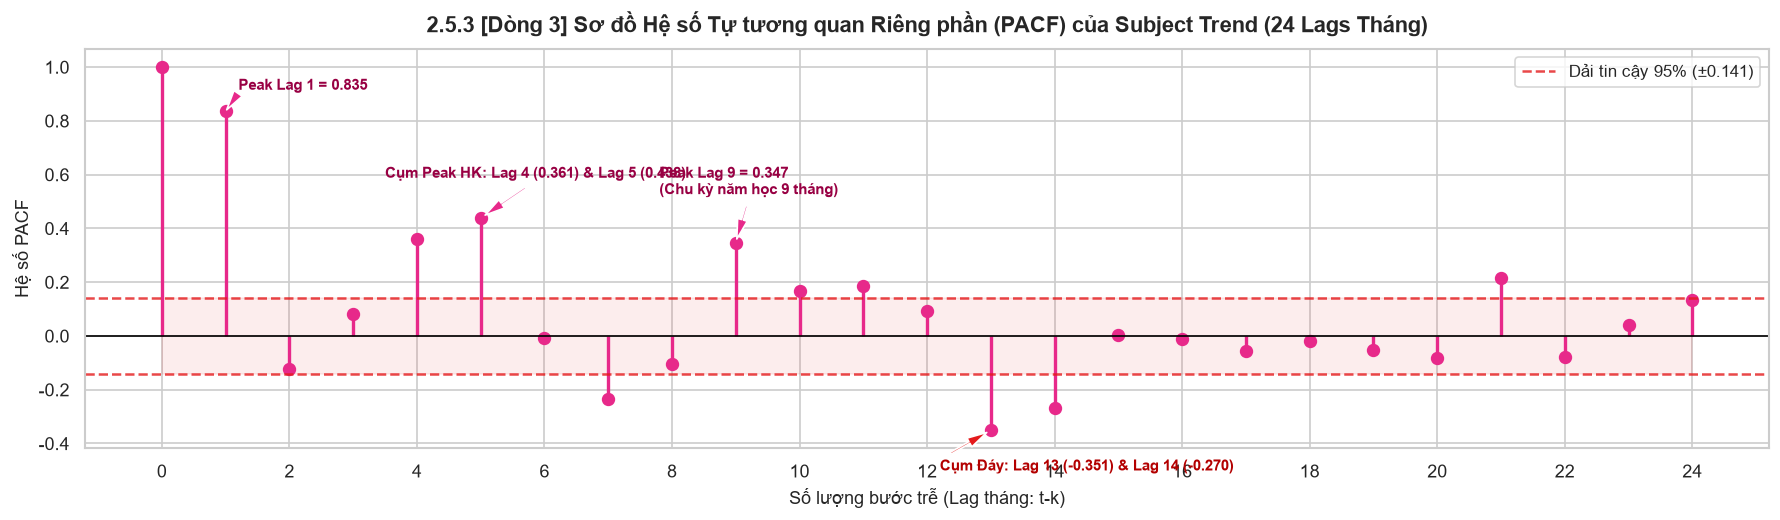

In [19]:
# 2.5.3 Chart 3: Sơ đồ Partial Autocorrelation (PACF) của Subject Trend (Lags 1-24 tháng)
sub_pacf = pacf(sub_ts, nlags=24)
conf_sub = 1.96 / np.sqrt(len(sub_ts))

fig, ax = plt.subplots(figsize=(15, 4.5))
lags_24 = range(len(sub_pacf))
markerline, stemlines, baseline = ax.stem(lags_24, sub_pacf, basefmt=' ')
plt.setp(stemlines, lw=2.0, color='#e7298a')
plt.setp(markerline, markersize=7, color='#e7298a')

ax.axhline(0, color='black', lw=1)
ax.axhline(conf_sub, color='#e41a1c', linestyle='--', alpha=0.8, label=f'Dải tin cậy 95% (±{conf_sub:.3f})')
ax.axhline(-conf_sub, color='#e41a1c', linestyle='--', alpha=0.8)
ax.fill_between(lags_24, -conf_sub, conf_sub, color='#e41a1c', alpha=0.08)

ax.annotate(f'Peak Lag 1 = {sub_pacf[1]:.3f}',
            xy=(1, sub_pacf[1]), xytext=(1.2, sub_pacf[1] + 0.08),
            arrowprops=dict(facecolor='#e7298a', shrink=0.08, width=1.2, headwidth=6),
            fontsize=9, fontweight='bold', color='#980043')

ax.annotate(f'Cụm Peak HK: Lag 4 ({sub_pacf[4]:.3f}) & Lag 5 ({sub_pacf[5]:.3f})',
            xy=(5, sub_pacf[5]), xytext=(3.5, sub_pacf[5] + 0.15),
            arrowprops=dict(facecolor='#e7298a', shrink=0.08, width=1.2, headwidth=6),
            fontsize=9, fontweight='bold', color='#980043')

ax.annotate(f'Peak Lag 9 = {sub_pacf[9]:.3f}\n(Chu kỳ năm học 9 tháng)',
            xy=(9, sub_pacf[9]), xytext=(7.8, sub_pacf[9] + 0.18),
            arrowprops=dict(facecolor='#e7298a', shrink=0.08, width=1.2, headwidth=6),
            fontsize=9, fontweight='bold', color='#980043')

ax.annotate(f'Cụm Đáy: Lag 13 ({sub_pacf[13]:.3f}) & Lag 14 ({sub_pacf[14]:.3f})',
            xy=(13, sub_pacf[13]), xytext=(12.2, sub_pacf[13] - 0.15),
            arrowprops=dict(facecolor='#e41a1c', shrink=0.08, width=1.2, headwidth=6),
            fontsize=9, fontweight='bold', color='#b30000')

ax.set_title('2.5.3 [Dòng 3] Sơ đồ Hệ số Tự tương quan Riêng phần (PACF) của Subject Trend (24 Lags Tháng)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Số lượng bước trễ (Lag tháng: t-k)', fontsize=11)
ax.set_ylabel('Hệ số PACF', fontsize=11)
ax.set_xticks(range(0, 25, 2))
ax.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.5.3 (Sơ đồ PACF của Subject Trend):**
  - **Nhận diện chính xác các đỉnh (Peaks):**
    1. **Lag 1 (+0.8353):** Quán tính học tập và tìm kiếm tài liệu môn học liên tục giữa các tháng.
    2. **Lag 4 (+0.3606) và Lag 5 (+0.4381):** Cụm đỉnh phản ánh chu kỳ học kỳ (4–5 tháng) giữa đợt thi giữa kỳ và cuối kỳ.
    3. **Lag 9 (+0.3472):** Đỉnh mang tính bản chất học thuật sâu sắc: tương ứng với **trọn vẹn 1 năm học (9 tháng từ Tháng 9 khai giảng đến Tháng 5 bế giảng)**!
  - **Nhận diện các đáy âm sâu (Troughs):**
    * **Lag 13 (-0.3506) và Lag 14 (-0.2700):** Là hai đáy âm sâu nhất trong toàn bộ chuỗi. Điều này thể hiện sự tương phản đối nghịch tuyệt đối: thời điểm ôn thi học kỳ/tốt nghiệp căng thẳng đối sánh với kỳ nghỉ hè (tháng 6–7 đối nghịch với tháng 8–9 năm sau khi đã kết thúc thi cử và chuyển sang lứa học sinh hoàn toàn mới).

### 2.6 Khảo sát Tính Mùa vụ của Phương thức Xét tuyển (Admission Method Trend)

Thực thể `admission_method` (5 từ khóa / 11 chủ đề) bao gồm: *Điểm học bạ*, *ĐGNL V-SAT*, *ĐGNL ĐHQG*, *ĐGTD*, *Xét tuyển kết hợp*... Nhóm này ghi nhận hiện tượng dịch chuyển xu hướng mạnh mẽ nhất: gần như bằng 0 trong giai đoạn 2010–2018 và tăng trưởng bùng nổ vượt bậc từ năm 2019 đến nay.

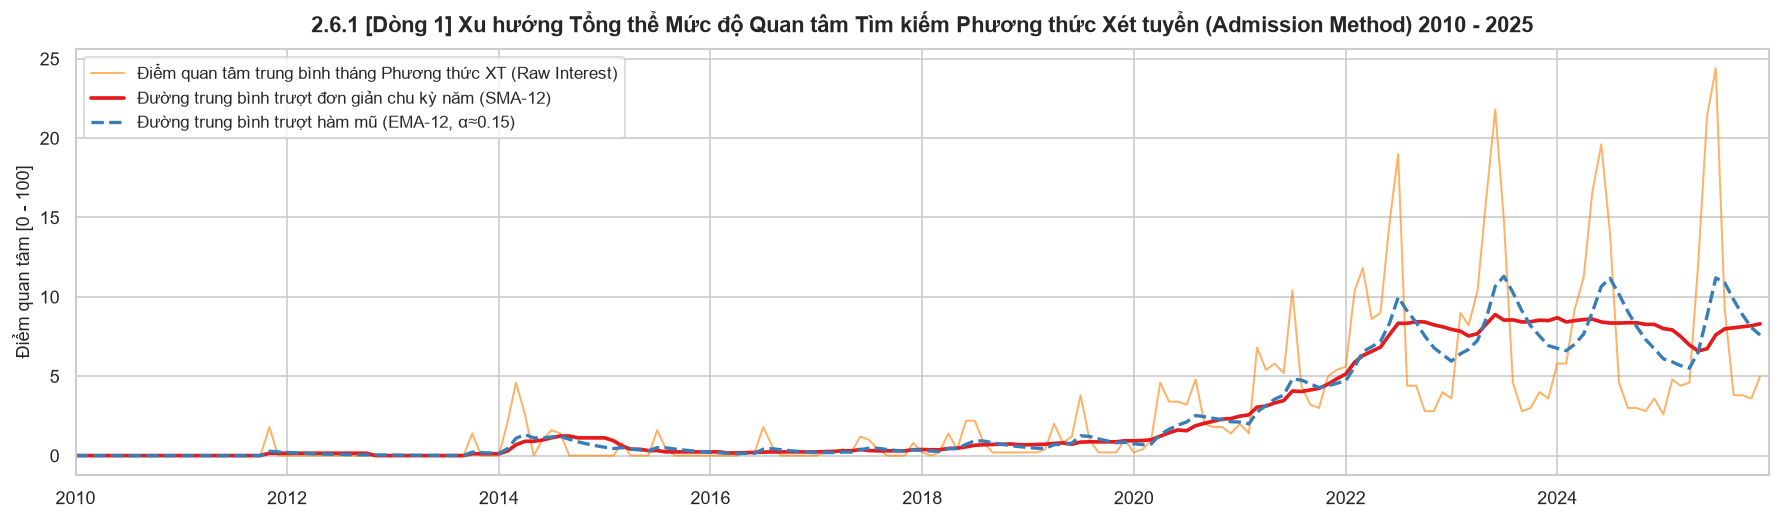

In [20]:
# 2.6.1 Chart 1: Xu hướng tổng thể phương thức tuyển sinh 2010 - 2025 (tích hợp SMA, EMA)
merged_adm = df_timeline.merge(df_keywords[df_keywords['keyword_type'] == 'admission_method'][['query_id']], on='query_id')
adm_ts = merged_adm.groupby('date')['interest'].mean()

adm_sma12 = adm_ts.rolling(window=12, min_periods=1).mean()
adm_ema12 = adm_ts.ewm(span=12, adjust=False).mean()

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(adm_ts.index, adm_ts.values, color='#ff7f00', alpha=0.6, lw=1.2, label='Điểm quan tâm trung bình tháng Phương thức XT (Raw Interest)')
ax.plot(adm_ts.index, adm_sma12.values, color='#e41a1c', lw=2.2, label='Đường trung bình trượt đơn giản chu kỳ năm (SMA-12)')
ax.plot(adm_ts.index, adm_ema12.values, color='#377eb8', lw=2.0, linestyle='--', label='Đường trung bình trượt hàm mũ (EMA-12, α≈0.15)')

ax.set_title('2.6.1 [Dòng 1] Xu hướng Tổng thể Mức độ Quan tâm Tìm kiếm Phương thức Xét tuyển (Admission Method) 2010 - 2025', fontsize=13, fontweight='bold', pad=10)
ax.set_ylabel('Điểm quan tâm [0 - 100]', fontsize=11)
ax.set_xlim(pd.to_datetime('2010-01-01'), pd.to_datetime('2025-12-31'))
ax.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.6.1 (Xu hướng Tổng thể Phương thức Tuyển sinh 2010 - 2025):**
  - **Sự chuyển dịch lịch sử mang tính đột phá:** Giai đoạn 2010–2018 gần như bằng 0 (chỉ có thi Đại học 3 chung và thi THPTQG).
  - Từ năm 2019 đến nay, đường SMA-12 và EMA-12 tăng dựng đứng, phản ánh xu hướng các trường đại học tự chủ tuyển sinh, mở rộng xét tuyển học bạ và tổ chức các kỳ thi Đánh giá năng lực (HSA, V-ACT, TSA), trực tiếp chia sẻ và làm giảm chỉ tiêu xét tuyển bằng điểm thi THPT.

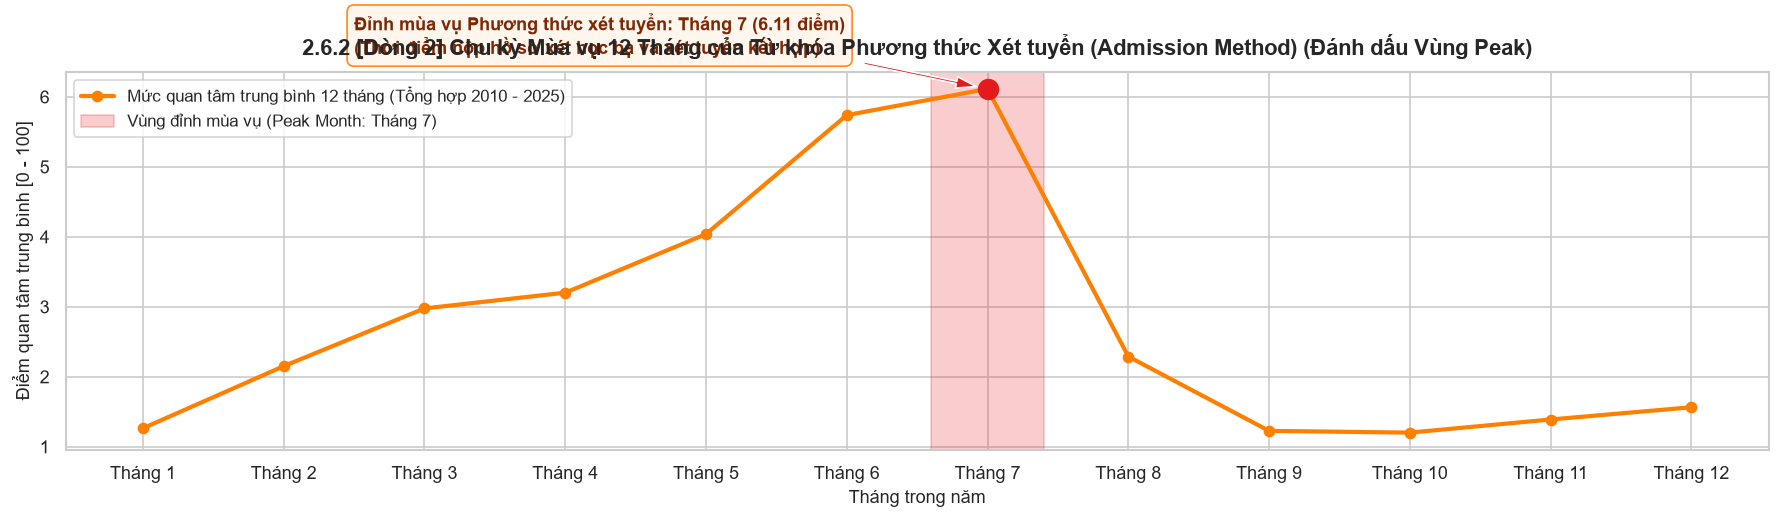

In [21]:
# 2.6.2 Chart 2: Xu hướng trung bình 12 tháng của Admission Method (tích hợp đánh dấu vùng Peak)
adm_monthly_profile = adm_ts.groupby(adm_ts.index.month).mean()
adm_peak_m = adm_monthly_profile.idxmax()

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(adm_monthly_profile.index, adm_monthly_profile.values, marker='o', lw=2.5, color='#ff7f00', label='Mức quan tâm trung bình 12 tháng (Tổng hợp 2010 - 2025)')
ax.axvspan(adm_peak_m - 0.4, adm_peak_m + 0.4, color='#e41a1c', alpha=0.22, label=f'Vùng đỉnh mùa vụ (Peak Month: Tháng {adm_peak_m})')
ax.scatter([adm_peak_m], [adm_monthly_profile[adm_peak_m]], color='#e41a1c', s=140, zorder=5)

ax.annotate(f'Đỉnh mùa vụ Phương thức xét tuyển: Tháng {adm_peak_m} ({adm_monthly_profile[adm_peak_m]:.2f} điểm)\n(Thời điểm nộp hồ sơ xét học bạ và xét tuyển kết hợp)',
            xy=(adm_peak_m, adm_monthly_profile[adm_peak_m]), xytext=(adm_peak_m - 4.5, adm_monthly_profile[adm_peak_m] + 0.5),
            arrowprops=dict(facecolor='#e41a1c', shrink=0.08, width=1.5, headwidth=7),
            fontsize=10.5, fontweight='bold', color='#7f2704',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#fff5eb', edgecolor='#ff7f00', alpha=0.9))

ax.set_title('2.6.2 [Dòng 2] Chu kỳ Mùa vụ 12 Tháng của Từ khóa Phương thức Xét tuyển (Admission Method) (Đánh dấu Vùng Peak)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Tháng trong năm', fontsize=11)
ax.set_ylabel('Điểm quan tâm trung bình [0 - 100]', fontsize=11)
ax.set_xticks(range(1, 13))
ax.set_xticklabels([f'Tháng {m}' for m in range(1, 13)])
ax.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.6.2 (Chu kỳ Mùa vụ 12 Tháng của Phương thức Tuyển sinh):**
  - Đạt đỉnh vào Tháng 7 (thời điểm nộp hồ sơ xét tuyển sớm và xác nhận trúng tuyển học bạ có điều kiện).

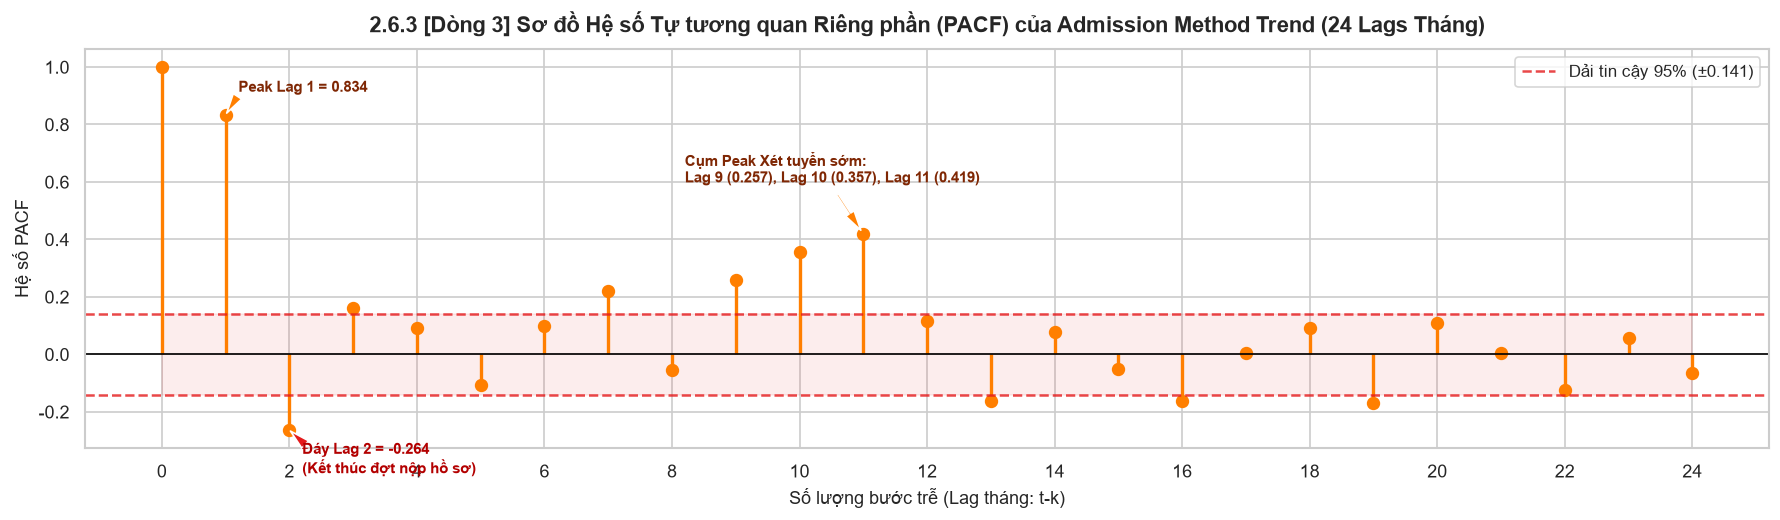

In [22]:
# 2.6.3 Chart 3: Sơ đồ Partial Autocorrelation (PACF) của Admission Method Trend (Lags 1-24 tháng)
adm_pacf = pacf(adm_ts, nlags=24)
conf_adm = 1.96 / np.sqrt(len(adm_ts))

fig, ax = plt.subplots(figsize=(15, 4.5))
lags_24 = range(len(adm_pacf))
markerline, stemlines, baseline = ax.stem(lags_24, adm_pacf, basefmt=' ')
plt.setp(stemlines, lw=2.0, color='#ff7f00')
plt.setp(markerline, markersize=7, color='#ff7f00')

ax.axhline(0, color='black', lw=1)
ax.axhline(conf_adm, color='#e41a1c', linestyle='--', alpha=0.8, label=f'Dải tin cậy 95% (±{conf_adm:.3f})')
ax.axhline(-conf_adm, color='#e41a1c', linestyle='--', alpha=0.8)
ax.fill_between(lags_24, -conf_adm, conf_adm, color='#e41a1c', alpha=0.08)

ax.annotate(f'Peak Lag 1 = {adm_pacf[1]:.3f}',
            xy=(1, adm_pacf[1]), xytext=(1.2, adm_pacf[1] + 0.08),
            arrowprops=dict(facecolor='#ff7f00', shrink=0.08, width=1.2, headwidth=6),
            fontsize=9, fontweight='bold', color='#7f2704')

ax.annotate(f'Đáy Lag 2 = {adm_pacf[2]:.3f}\n(Kết thúc đợt nộp hồ sơ)',
            xy=(2, adm_pacf[2]), xytext=(2.2, adm_pacf[2] - 0.15),
            arrowprops=dict(facecolor='#e41a1c', shrink=0.08, width=1.2, headwidth=6),
            fontsize=9, fontweight='bold', color='#b30000')

ax.annotate(f'Cụm Peak Xét tuyển sớm:\nLag 9 ({adm_pacf[9]:.3f}), Lag 10 ({adm_pacf[10]:.3f}), Lag 11 ({adm_pacf[11]:.3f})',
            xy=(11, adm_pacf[11]), xytext=(8.2, adm_pacf[11] + 0.18),
            arrowprops=dict(facecolor='#ff7f00', shrink=0.08, width=1.2, headwidth=6),
            fontsize=9, fontweight='bold', color='#7f2704')

ax.set_title('2.6.3 [Dòng 3] Sơ đồ Hệ số Tự tương quan Riêng phần (PACF) của Admission Method Trend (24 Lags Tháng)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Số lượng bước trễ (Lag tháng: t-k)', fontsize=11)
ax.set_ylabel('Hệ số PACF', fontsize=11)
ax.set_xticks(range(0, 25, 2))
ax.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Chart 2.6.3 (Sơ đồ PACF của Admission Method Trend):**
  - **Nhận diện chính xác các đỉnh (Peaks):**
    1. **Lag 1 (+0.8339):** Quán tính tìm kiếm cực kỳ cao trong suốt giai đoạn bùng nổ phương thức mới (2019–2025).
    2. **Cụm Peak kéo dài từ Lag 9, 10 đến 11:** 
       * **Lag 9 (+0.2570):** Tháng 3 (thời điểm các trường công bố đề án và nhận hồ sơ ĐGNL đợt 1).
       * **Lag 10 (+0.3568):** Tháng 4–5 (thi ĐGNL và nộp hồ sơ học bạ).
       * **Lag 11 (+0.4186):** Tháng 6–7 (công bố kết quả xét tuyển sớm có điều kiện). Cụm này cao vượt trội so với Lag 12 (0.1162), phản ánh rõ bản chất các phương thức mới diễn ra **trước** kỳ thi tốt nghiệp THPT chính thức từ 1 đến 3 tháng!
  - **Nhận diện đáy âm (Trough):**
    * **Lag 2 (-0.2639):** Sau khi các trường kết thúc nhận hồ sơ xét tuyển sớm theo từng đợt, lượng tìm kiếm sụt giảm mạnh đột ngột tạo nên bước trễ tương quan âm.

### 2.7 Bảng Tổng hợp So sánh Đặc tính Mùa vụ và Quán tính giữa 6 Thành phần

Bảng đối sánh tổng hợp các chỉ số mùa vụ định lượng giữa 6 thành phần:

| Thành phần khảo sát | Dạng chuỗi thời gian | Giai đoạn hoạt động chính | Tháng Peak đỉnh điểm trong năm | Các bước trễ Peak & Đáy PACF chính xác | Ý nghĩa nghiệp vụ & Quyết định mô hình hóa |
| :--- | :---: | :---: | :---: | :--- | :--- |
| **Cutoff score (THPT)** | Hàng năm | 2010 – 2025 (16 năm) | **Tháng 8** (Công bố điểm) | **Peak: Lag 1 (+0.8035)**<br>(Lag 2-5 trong dải vô hiệu) | Quán tính bậc 1 AR(1) chi phối >80% phương sai. `cutoff_lag1` là đặc trưng bắt buộc số 1. |
| **School trend** | Hàng tháng | 2010 – 2025 (192 tháng) | **Tháng 8** (Chốt nguyện vọng) | **Peak: Lag 1 (+0.619), Lag 11 (+0.607), Lag 12 (+0.476)**<br>**Đáy: Lag 2 (-0.356)** | Quán tính liền kề mạnh, chu kỳ mùa vụ 11-12 tháng rõ rệt, sụt dốc mạnh sau 2 tháng hết mùa tuyển sinh. |
| **Major group trend** | Hàng tháng | 2010 – 2025 (192 tháng) | **Tháng 7** (Định hướng ngành) | **Peak: Lag 1 (+0.821), Lag 11 (+0.305)**<br>**Đáy: Lag 13 (-0.253)** | Thí sinh chọn ngành trước chọn trường 1 tháng. Đảo pha âm mạnh mẽ sau 13 tháng (đổi lứa học sinh). |
| **Subject group trend** | Hàng tháng | Bùng nổ từ 2017 | **Tháng 12 & Tháng 7** | **Peak: Lag 1 (+0.690), Lag 5 (+0.374), Lag 18 (+0.280)** | Bắt trọn chu kỳ học kỳ 5 tháng (T12 sang T5) và chu kỳ 1.5 năm (18 tháng) từ giữa lớp 11 chọn khối đến hết lớp 12 thi tốt nghiệp. |
| **Subject trend** | Hàng tháng | Quanh năm (Baseline cao) | **Tháng 10 & Tháng 5** | **Peak: Lag 1 (+0.835), Lag 4-5 (+0.438), Lag 9 (+0.347)**<br>**Đáy: Lag 13 (-0.351), Lag 14 (-0.270)** | Bắt trọn chu kỳ năm học 9 tháng (T9 đến T5) và chu kỳ thi cử học kỳ 4-5 tháng. Đáy âm 13-14 tháng thể hiện tính đối nghịch với kỳ nghỉ hè. |
| **Admission method trend**| Hàng tháng | Đột biến từ 2019 | **Tháng 7** (Chốt xét tuyển sớm) | **Peak: Lag 1 (+0.834), Cụm Lag 9-11 (+0.419)**<br>**Đáy: Lag 2 (-0.264)** | Phản ánh chính xác lịch xét tuyển sớm (bắt đầu từ T3, kéo dài đến T6-T7 trước thi THPT). Đáy Lag 2 do kết thúc đợt nộp hồ sơ. |

---
## 3. Xây dựng Pipeline Trích xuất Đặc trưng (Feature Extraction Pipeline)

Dựa trên các khám phá từ phân tích chuỗi thời gian, tính mùa vụ và các tập dữ liệu hiện có, chúng tôi xây dựng một danh mục **TOÀN DIỆN 38 đặc trưng ứng viên (Candidate Features) - tổng cộng 39 đặc trưng danh mục (bao gồm cả biến mục tiêu phụ sai phân `cutoff_delta`)**, tích hợp trực tiếp 7 đặc trưng bước trễ mùa vụ theo tháng (PACF Seasonal Lags) từ phân tích ở Mục 2, kết hợp chặt chẽ cùng các nhóm đặc trưng tự hồi quy AR, cấu trúc tuyển sinh, Google Trends thường niên và tương tác chéo.

### 3.1 Danh mục TOÀN BỘ 38 Đặc trưng Ứng viên (39 Đặc trưng Danh mục)

Dưới đây là bảng chú giải chi tiết toàn bộ 39 đặc trưng (38 đặc trưng đầu vào ứng viên phục vụ huấn luyện và 1 biến mục tiêu phụ sai phân `cutoff_delta` phục vụ mô hình hóa phần dư), được cấu trúc thành 5 nhóm logic chặt chẽ:

#### Nhóm 1: Lịch sử & Quán tính Chuỗi thời gian (Historical & Inertia Features)
1. `cutoff_lag1`: Điểm chuẩn của cùng ngành, cùng trường, cùng phương thức xét tuyển tại năm $t-1$. Ý nghĩa: Bắt trọn quán tính AR(1) mạnh mẽ ($\approx 0.8035$). Cách trích xuất: `groupby(['school_id', 'score_code'])['score_mark'].shift(1)`.
2. `cutoff_lag2`: Điểm chuẩn tại năm $t-2$. Ý nghĩa: Cung cấp mỏ neo chuỗi dài hạn 2 năm. Cách trích xuất: `shift(2)`.
3. `cutoff_roll_mean2`: Trung bình trượt 2 năm liên tiếp $(cutoff\_lag1 + cutoff\_lag2) / 2$. Ý nghĩa: Làm mượt các biến động đột ngột hoặc bất thường cục bộ của đề thi từng năm.
4. `cutoff_delta_prev`: Độ biến động điểm chuẩn năm trước $(cutoff\_lag1 - cutoff\_lag2)$. Ý nghĩa: Đo lường đà dịch chuyển (momentum) của điểm chuẩn trong chu kỳ gần nhất.
5. `cutoff_delta`: Biến động điểm chuẩn năm hiện tại so với năm trước $(y_t - y_{t-1})$. Ý nghĩa: Biến mục tiêu phụ trợ dùng để đánh giá tương quan tốc độ tăng trưởng.

#### Nhóm 2: Cấu trúc & Đếm Số lượng Tuyển sinh (Admission Count & Structural Features)
6. `num_blocks`: Số lượng tổ hợp môn xét tuyển mà ngành chấp nhận (ví dụ: A00, A01, D01... $\rightarrow$ 3 tổ hợp). Ý nghĩa: Đo lường độ linh hoạt và mức độ cạnh tranh của hồ sơ thí sinh. Cách trích xuất: Đếm số phần tử phân tách dấu phẩy trong cột `score_blocks`.
7. `num_methods_in_major`: Số lượng phương thức xét tuyển mở cho ngành trong cùng một trường (ví dụ: CNTT tuyển bằng cả THPT, Học bạ, ĐGNL $\rightarrow$ 3 phương thức). Ý nghĩa: Phản ánh mức độ phân bổ và chia nhỏ chỉ tiêu tuyển sinh cho ngành.
8. `num_methods_in_school`: Tổng số phương thức xét tuyển của trường đại học trong năm đó. Ý nghĩa: Đo lường mức độ đa dạng hóa tuyển sinh của nhà trường.
9. `num_majors_in_school`: Tổng số ngành đào tạo mà trường mở tuyển sinh trong năm. Ý nghĩa: Đo lường quy mô và mức độ đa ngành của trường.
10. `num_schools_offering_major`: Số lượng trường đại học trên toàn quốc cùng đào tạo ngành này trong năm. Ý nghĩa: Thước đo mức độ cạnh tranh thị trường đào tạo của ngành.
11. `school_type_enc`: Loại hình trường (Đại học Công lập = 1, Dân lập / Tư thục = 0).
12. `province_id`: Mã định danh tỉnh/thành phố nơi trường đặt trụ sở chính (yếu tố địa kinh tế và sức hút vùng miền).

#### Nhóm 3: Chỉ số Xu hướng & Mùa vụ Google Trends trên Toàn bộ 6 Keyword Types
13. `school_trend_mean`: Mức độ quan tâm tìm kiếm trung bình cả năm của trường đại học.
14. `school_trend_max`: Đỉnh tìm kiếm cao nhất trong năm của trường (thường rơi vào mùa tuyển sinh).
15. `school_trend_nonzero_months`: Số tháng có phát sinh tìm kiếm lớn hơn 0 trong năm của trường.
16. `school_trend_peak_month`: Tháng đạt đỉnh tìm kiếm trong năm của trường đại học.
17. `school_peak_intensity`: Cường độ đỉnh mùa vụ so với mức nền $(school\_trend\_max / (school\_trend\_mean + 10^{-5}))$.
18. `school_yoy`: Tốc độ tăng trưởng tìm kiếm hàng năm của trường so với năm trước $(S_t - S_{t-1}) / S_{t-1}$.
19. `major_trend_mean`: Mức độ quan tâm tìm kiếm trung bình cả năm của ngành đào tạo chuẩn.
20. `major_trend_max`: Đỉnh tìm kiếm cao nhất trong năm của ngành đào tạo.
21. `major_yoy`: Tốc độ tăng trưởng tìm kiếm hàng năm của ngành đào tạo.
22. `group_trend_mean`: Mức độ quan tâm trung bình của khối/nhóm ngành đào tạo vĩ mô.
23. `group_yoy`: Tốc độ tăng trưởng tìm kiếm hàng năm của nhóm ngành.
24. `subject_trend_mean`: Mức độ quan tâm trung bình toàn quốc đối với các môn thi tốt nghiệp THPT.
25. `subject_yoy`: Tốc độ tăng trưởng tìm kiếm môn học so với năm trước.
26. `subject_group_trend_mean`: Mức độ quan tâm trung bình toàn quốc đối với các tổ hợp xét tuyển.
27. `subject_group_yoy`: Tốc độ tăng trưởng tìm kiếm tổ hợp xét tuyển.
28. `admission_method_trend_mean`: Mức độ quan tâm trung bình đối với các phương thức tuyển sinh mới.
29. `admission_method_yoy`: Tốc độ tăng trưởng tìm kiếm phương thức tuyển sinh.

#### Nhóm 4: Đặc trưng Bước trễ Mùa vụ PACF Khai thác theo Tháng (PACF Seasonal Monthly Lag Features)
*Được trích xuất trực tiếp từ các mốc Peak tự tương quan riêng phần đã khám phá tại Mục 2:*
30. `school_trend_lag1m`: Mức quan tâm tìm kiếm trường học tại Tháng 7 của năm tuyển sinh $T$ (Lag 1 tháng trước khi chốt điểm chuẩn, tương ứng PACF lag 1 = +0.619). Ý nghĩa: Sức nóng trực tiếp tại thời điểm thí sinh nộp hồ sơ xét tuyển.
31. `school_trend_lag12m`: Mức quan tâm trường học tại Tháng 8 năm $T-1$ (Lag 12 tháng, mùa tuyển sinh năm trước, tương ứng PACF lag 12 = +0.476). Ý nghĩa: Thước đo uy tín trường tại đợt tuyển sinh liền kề.
32. `major_group_trend_lag1m`: Mức quan tâm nhóm ngành tại Tháng 7 năm $T$ (Lag 1 tháng, tương ứng PACF lag 1 = +0.821). Ý nghĩa: Động lực ngành tức thời.
33. `major_group_trend_lag11m`: Mức quan tâm nhóm ngành tại Tháng 9 năm $T-1$ (Lag 11 tháng, tương ứng PACF lag 11 = +0.305). Ý nghĩa: Dư âm sau mùa tuyển sinh trước.
34. `subject_group_trend_lag5m`: Mức quan tâm tổ hợp môn tại Tháng 3 năm $T$ (Lag 5 tháng, tương ứng PACF lag 5 = +0.374). Ý nghĩa: Thời điểm học sinh chốt đăng ký tổ hợp môn thi tốt nghiệp THPT học kỳ II.
35. `subject_trend_lag9m`: Mức quan tâm môn học tại Tháng 11 năm $T-1$ (Lag 9 tháng, tương ứng PACF lag 9 = +0.347). Ý nghĩa: Chu kỳ trọn vẹn 1 năm học 9 tháng từ khai giảng đến thi cử.
36. `admission_method_trend_lag10m`: Mức quan tâm phương thức xét tuyển tại Tháng 4 năm $T$ (Lag 10 tháng, tương ứng cụm PACF lag 9–11 = +0.419). Ý nghĩa: Sức nóng bùng nổ của các đợt thi ĐGNL và nộp hồ sơ học bạ sớm.

#### Nhóm 5: Đặc trưng Tương tác & Phân kỳ Động lực (Cross-Feature Interaction & Momentum)
37. `school_major_yoy_diff`: Độ lệch tăng trưởng giữa trường và ngành $(school\_yoy - major\_yoy)$. Ý nghĩa: Đo lường sự phân kỳ khi ngành đang "hot" nhưng trường hạ nhiệt hoặc ngược lại.
38. `school_to_group_ratio`: Tỷ lệ sức hút của trường so với mặt bằng nhóm ngành $(school\_trend\_mean / group\_trend\_mean)$. Ý nghĩa: Đo lường vị thế trường đầu ngành.
39. `method_diversification_ratio`: Tỷ trọng phương thức ngành so với toàn trường $(num\_methods\_in\_major / num\_methods\_in\_school)$.

In [23]:
# 3.2 Thực thi Pipeline Trích xuất Toàn bộ 38 Đặc trưng Ứng viên
def remove_accents(input_str):
    if not isinstance(input_str, str):
        return ""
    nfkd_form = unicodedata.normalize('NFKD', input_str)
    return "".join([c for c in nfkd_form if not unicodedata.combining(c)])

def clean_text(text):
    text = remove_accents(str(text)).lower()
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

print("Đang tiến hành trích xuất đặc trưng trên tập dữ liệu tuyển sinh...")

df_thpt = df_cutoffs[(df_cutoffs['score_year'] >= 2010) & (df_cutoffs['score_admission_name'] == 'Điểm thi THPT')].copy()
df_thpt = df_thpt.sort_values(['school_id', 'score_code', 'score_year'])

# 1. Trích xuất nhóm Lịch sử & Quán tính
df_thpt['cutoff_lag1'] = df_thpt.groupby(['school_id', 'score_code'])['score_mark'].shift(1)
df_thpt['cutoff_lag2'] = df_thpt.groupby(['school_id', 'score_code'])['score_mark'].shift(2)
df_thpt['cutoff_roll_mean2'] = (df_thpt['cutoff_lag1'] + df_thpt['cutoff_lag2']) / 2.0
df_thpt['cutoff_delta_prev'] = df_thpt['cutoff_lag1'] - df_thpt['cutoff_lag2']
df_thpt['cutoff_delta'] = df_thpt['score_mark'] - df_thpt['cutoff_lag1']

# 2. Trích xuất nhóm Cấu trúc & Đếm Số lượng Tuyển sinh
df_thpt['num_blocks'] = df_thpt['score_blocks'].fillna('').apply(lambda x: len([b.strip() for b in str(x).split(',') if b.strip()]) if x else 1)
df_thpt['num_methods_in_major'] = df_thpt.groupby(['school_id', 'score_code', 'score_year'])['score_admission_name'].transform('nunique')
df_thpt['num_methods_in_school'] = df_thpt.groupby(['school_id', 'score_year'])['score_admission_name'].transform('nunique')
df_thpt['num_majors_in_school'] = df_thpt.groupby(['school_id', 'score_year'])['score_code'].transform('nunique')
df_thpt['num_schools_offering_major'] = df_thpt.groupby(['score_code', 'score_year'])['school_id'].transform('nunique')
df_thpt['school_type_enc'] = (df_thpt['school_type'] == 'Đại học').astype(int)

# Ánh xạ ngành và nhóm ngành từ majors.csv
exploded = df_majors.assign(score_code=df_majors['score_codes'].str.split(';')).explode('score_code')
exploded['score_code'] = exploded['score_code'].str.strip()
code_to_group = exploded.drop_duplicates(subset=['score_code']).set_index('score_code')['major_group_name'].to_dict()
code_to_major = exploded.drop_duplicates(subset=['score_code']).set_index('score_code')['major_name'].to_dict()

df_thpt['major_group_name'] = df_thpt['score_code'].map(code_to_group).fillna('Khác')
df_thpt['std_major_name'] = df_thpt['score_code'].map(code_to_major).fillna(df_thpt['score_name'])

# 3. Ánh xạ Google Trends: School
kw_school = df_keywords[df_keywords['keyword_type'] == 'school'].copy()
kw_school['clean_kw'] = kw_school['keyword'].apply(clean_text)
kw_school_map = kw_school.drop_duplicates('clean_kw').set_index('clean_kw')['query_id'].to_dict()

df_thpt['clean_school'] = df_thpt['school_name'].apply(clean_text)
df_thpt['school_query_id'] = df_thpt['clean_school'].map(kw_school_map)

annual_sub = df_annual[['query_id', 'year', 'mean', 'max', 'nonzero_months', 'peak_month', 'yoy']].copy()
ann_school = annual_sub.rename(columns={
    'query_id': 'school_query_id',
    'year': 'score_year',
    'mean': 'school_trend_mean',
    'max': 'school_trend_max',
    'nonzero_months': 'school_trend_nonzero_months',
    'peak_month': 'school_trend_peak_month',
    'yoy': 'school_yoy'
})
df_features = df_thpt.merge(ann_school, on=['school_query_id', 'score_year'], how='left')

# Ánh xạ Google Trends: Major
kw_major = df_keywords[df_keywords['keyword_type'] == 'major'].copy()
kw_major['clean_kw'] = kw_major['keyword'].apply(clean_text)
kw_major_map = kw_major.drop_duplicates('clean_kw').set_index('clean_kw')['query_id'].to_dict()

df_features['clean_major'] = df_features['std_major_name'].apply(clean_text)
df_features['major_query_id'] = df_features['clean_major'].map(kw_major_map)

ann_major = annual_sub[['query_id', 'year', 'mean', 'max', 'yoy']].rename(columns={
    'query_id': 'major_query_id',
    'year': 'score_year',
    'mean': 'major_trend_mean',
    'max': 'major_trend_max',
    'yoy': 'major_yoy'
})
df_features = df_features.merge(ann_major, on=['major_query_id', 'score_year'], how='left')

# Ánh xạ Google Trends: Major Group
kw_grp = df_keywords[df_keywords['keyword_type'] == 'major_group'].copy()
kw_grp['clean_kw'] = kw_grp['keyword'].apply(clean_text)
kw_grp_map = kw_grp.drop_duplicates('clean_kw').set_index('clean_kw')['query_id'].to_dict()

df_features['clean_group'] = df_features['major_group_name'].apply(clean_text)
df_features['group_query_id'] = df_features['clean_group'].map(kw_grp_map)

ann_grp = annual_sub[['query_id', 'year', 'mean', 'yoy']].rename(columns={
    'query_id': 'group_query_id',
    'year': 'score_year',
    'mean': 'group_trend_mean',
    'yoy': 'group_yoy'
})
df_features = df_features.merge(ann_grp, on=['group_query_id', 'score_year'], how='left')

# Ánh xạ Google Trends Macro: Subject, Subject Group, Admission Method
macro_sub = df_annual.merge(df_keywords[['query_id', 'keyword_type']], on='query_id', how='inner')
for kt in ['subject', 'subject_group', 'admission_method']:
    kt_yr = macro_sub[macro_sub['keyword_type'] == kt].groupby('year')[['mean', 'yoy']].mean().reset_index()
    kt_yr = kt_yr.rename(columns={'year': 'score_year', 'mean': f'{kt}_trend_mean', 'yoy': f'{kt}_yoy'})
    df_features = df_features.merge(kt_yr, on='score_year', how='left')

# 4. Trích xuất ĐẶC TRƯNG BƯỚC TRỄ MÙA VỤ PACF THEO THÁNG (Từ phát hiện Mục 2)
tl_indexed = df_timeline.set_index(['query_id', 'date'])['interest']
macro_tl = df_timeline.merge(df_keywords[['query_id', 'keyword_type']], on='query_id')
macro_monthly = macro_tl.groupby(['keyword_type', 'date'])['interest'].mean()

seasonal_lags_by_year = {}
for yr in range(2010, 2026):
    ref = pd.to_datetime(f'{yr}-08-01')
    d_lag4 = ref - pd.DateOffset(months=4)    # April yr T
    d_lag5 = ref - pd.DateOffset(months=5)    # March yr T
    d_lag9 = ref - pd.DateOffset(months=9)    # Nov yr T-1

    sg_lag5 = macro_monthly.get(('subject_group', d_lag5), np.nan)
    sub_lag9 = macro_monthly.get(('subject', d_lag9), np.nan)
    adm_lag10 = macro_monthly.get(('admission_method', d_lag4), np.nan)

    seasonal_lags_by_year[yr] = {
        'score_year': yr,
        'subject_group_trend_lag5m': sg_lag5,
        'subject_trend_lag9m': sub_lag9,
        'admission_method_trend_lag10m': adm_lag10
    }

df_macro_seasonal = pd.DataFrame(list(seasonal_lags_by_year.values()))
df_features = df_features.merge(df_macro_seasonal, on='score_year', how='left')

# Trích xuất School PACF lags: Lag 1m (Tháng 7 năm T) và Lag 12m (Tháng 8 năm T-1)
school_queries = df_features['school_query_id'].dropna().unique()
records_school_lags = []
for qid in school_queries:
    for yr in range(2010, 2026):
        d_lag1 = pd.to_datetime(f'{yr}-07-01')
        d_lag12 = pd.to_datetime(f'{yr-1}-08-01')
        records_school_lags.append({
            'school_query_id': qid,
            'score_year': yr,
            'school_trend_lag1m': tl_indexed.get((qid, d_lag1), np.nan),
            'school_trend_lag12m': tl_indexed.get((qid, d_lag12), np.nan)
        })
df_school_lags = pd.DataFrame(records_school_lags)
df_features = df_features.merge(df_school_lags, on=['school_query_id', 'score_year'], how='left')

# Trích xuất Major Group PACF lags: Lag 1m (Tháng 7 năm T) và Lag 11m (Tháng 9 năm T-1)
grp_queries = df_features['group_query_id'].dropna().unique()
records_grp_lags = []
for qid in grp_queries:
    for yr in range(2010, 2026):
        d_lag1 = pd.to_datetime(f'{yr}-07-01')
        d_lag11 = pd.to_datetime(f'{yr-1}-09-01')
        records_grp_lags.append({
            'group_query_id': qid,
            'score_year': yr,
            'major_group_trend_lag1m': tl_indexed.get((qid, d_lag1), np.nan),
            'major_group_trend_lag11m': tl_indexed.get((qid, d_lag11), np.nan)
        })
df_grp_lags = pd.DataFrame(records_grp_lags)
df_features = df_features.merge(df_grp_lags, on=['group_query_id', 'score_year'], how='left')

# 5. Trích xuất Đặc trưng Tương tác & Phân kỳ Động lực
df_features['school_peak_intensity'] = df_features['school_trend_max'] / (df_features['school_trend_mean'] + 1e-5)
df_features['school_major_yoy_diff'] = df_features['school_yoy'] - df_features['major_yoy']
df_features['school_to_group_ratio'] = df_features['school_trend_mean'] / (df_features['group_trend_mean'] + 1e-5)
df_features['method_diversification_ratio'] = df_features['num_methods_in_major'] / (df_features['num_methods_in_school'] + 1e-5)

candidate_features = [
    # Nhóm 1: Lịch sử điểm chuẩn (PACF Lag 1 & 2)
    'cutoff_lag1', 'cutoff_lag2', 'cutoff_roll_mean2', 'cutoff_delta_prev',
    # Nhóm 2: Cấu trúc & Đếm số lượng
    'num_blocks', 'num_methods_in_major', 'num_methods_in_school', 'num_majors_in_school',
    'num_schools_offering_major', 'school_type_enc', 'province_id',
    # Nhóm 3: Google Trends Thường niên
    'school_trend_mean', 'school_trend_max', 'school_trend_nonzero_months', 'school_trend_peak_month',
    'school_peak_intensity', 'school_yoy',
    'major_trend_mean', 'major_trend_max', 'major_yoy',
    'group_trend_mean', 'group_yoy',
    'subject_trend_mean', 'subject_yoy',
    'subject_group_trend_mean', 'subject_group_yoy',
    'admission_method_trend_mean', 'admission_method_yoy',
    # Nhóm 4: BƯỚC TRỄ MÙA VỤ PACF THEO THÁNG (Tích hợp từ phát hiện Mục 2)
    'school_trend_lag1m', 'school_trend_lag12m',
    'major_group_trend_lag1m', 'major_group_trend_lag11m',
    'subject_group_trend_lag5m', 'subject_trend_lag9m', 'admission_method_trend_lag10m',
    # Nhóm 5: Tương tác & Phân kỳ
    'school_major_yoy_diff', 'school_to_group_ratio', 'method_diversification_ratio'
]

print(f"Hoàn thành trích xuất pipeline! Tổng số quan sát: {len(df_features):,}, Tổng số đặc trưng ứng viên: {len(candidate_features)}")

Đang tiến hành trích xuất đặc trưng trên tập dữ liệu tuyển sinh...


Hoàn thành trích xuất pipeline! Tổng số quan sát: 57,400, Tổng số đặc trưng ứng viên: 38


In [24]:
# Bảng thống kê mô tả toàn diện 38 đặc trưng ứng viên
desc_stats = df_features[candidate_features].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]
desc_stats['missing_rate_%'] = (1 - desc_stats['count'] / len(df_features)) * 100
desc_stats.columns = ['Số quan sát', 'Trung bình', 'Độ lệch chuẩn', 'Min', 'Trung vị (50%)', 'Max', 'Tỷ lệ khuyết (%)']

print("BẢNG THỐNG KÊ MÔ TẢ DANH MỤC ĐẶC TRƯNG ỨNG VIÊN:")
display(desc_stats.round(3))

BẢNG THỐNG KÊ MÔ TẢ DANH MỤC ĐẶC TRƯNG ỨNG VIÊN:


,Số quan sát,Trung bình,Độ lệch chuẩn,Min,Trung vị (50%),Max,Tỷ lệ khuyết (%)
cutoff_lag1,48491.0,18.989,4.583,3.000,18.000,34.000,15.521
cutoff_lag2,41259.0,18.888,4.569,3.000,18.000,34.000,28.120
cutoff_roll_mean2,41259.0,19.063,4.399,5.000,18.250,34.000,28.120
cutoff_delta_prev,41259.0,0.350,2.485,-18.000,0.000,27.000,28.120
num_blocks,57400.0,1.000,0.000,1.000,1.000,1.000,0.000
num_methods_in_major,57400.0,1.000,0.000,1.000,1.000,1.000,0.000
num_methods_in_school,57400.0,1.000,0.000,1.000,1.000,1.000,0.000
num_majors_in_school,57400.0,26.521,20.821,1.000,21.000,123.000,0.000
num_schools_offering_major,57400.0,26.964,33.059,1.000,15.000,139.000,0.000
school_type_enc,57400.0,1.000,0.006,0.000,1.000,1.000,0.000


---
## 4. Kiểm tra Mức độ Tương quan và Tuyển chọn Đặc trưng (Feature Evaluation & Selection)

Nhằm đảm bảo tính khoa học và chặt chẽ trong việc lựa chọn đặc trưng cho mô hình học máy, chúng tôi tiến hành thực hiện tuần tự **5 kỹ thuật thẩm định**:
1. **Feature–Target Correlation Heatmap:** Đánh giá tương quan tuyến tính (Pearson) và phi tuyến đơn điệu (Spearman) trực tiếp giữa từng đặc trưng với biến mục tiêu.
2. **Interfeature Correlation Heatmap:** Đo lường tương quan chéo giữa các cặp đặc trưng, phát hiện rủi ro đa cộng tuyến (Multicollinearity).
3. **ETC Ranking (Extra Trees Classifier / Regressor Ranking):** Đánh giá độ quan trọng phi tuyến (MDI) thông qua mô hình học kết hợp cây quyết định ngẫu nhiên triệt để.
4. **Polynomial Expansion:** Khảo sát các số hạng tương tác bậc 2 ($x_i \cdot x_j$) xem có gia tăng khả năng giải thích biến mục tiêu hay không.
5. **ANOVA F-test Filtering:** Kiểm định giả thuyết phân tích phương sai giải thích $F$-statistic và lọc các đặc trưng đạt độ tin cậy thống kê $p < 0.05$.
6. **Kết luận Danh sách Đặc trưng Khả thi nhất:** Tổng kết đa tiêu chuẩn, phân hạng Tier 1, Tier 2, Tier 3 kèm minh chứng số liệu.

### 4.1 Kỹ thuật 1: Feature–Target Correlation Heatmap

#### 1. Sơ bộ kỹ thuật & Cơ sở toán học
Hệ số tương quan Pearson ($r$) và Spearman rank correlation ($\rho$) đo lường độ mạnh và chiều hướng của mối quan hệ giữa từng đặc trưng $x_j$ với biến mục tiêu $y$ (`score_mark` hoặc biến động $\Delta y$):
$$r = \frac{\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^n (x_i - \bar{x})^2 \sum_{i=1}^n (y_i - \bar{y})^2}}$$
Trong khi Pearson nhạy cảm với các quan hệ tuyến tính, Spearman đo lường mối quan hệ đơn điệu dựa trên thứ bậc (ranks), không bị chi phối bởi các giá trị ngoại lai (outliers).

#### 2. Ý nghĩa trong bài toán điểm chuẩn
Giúp nhận diện ngay các biến số có quan hệ tương quan đồng biến mạnh mẽ nhất với điểm chuẩn (ví dụ: điểm chuẩn quá khứ, mức độ quan tâm của trường, số lượng trường cạnh tranh) và loại trừ sớm các biến hoàn toàn ngẫu nhiên ($|r| \approx 0$).

#### 3. Cách triển khai thực tế
Lấy tập dữ liệu đầy đủ quan sát điểm chuẩn, tính toán đồng thời cả Pearson và Spearman correlation của 38 đặc trưng ứng viên với `score_mark` và `cutoff_delta`, sau đó vẽ đồ thị thanh ngang xếp hạng theo giá trị tuyệt đối.

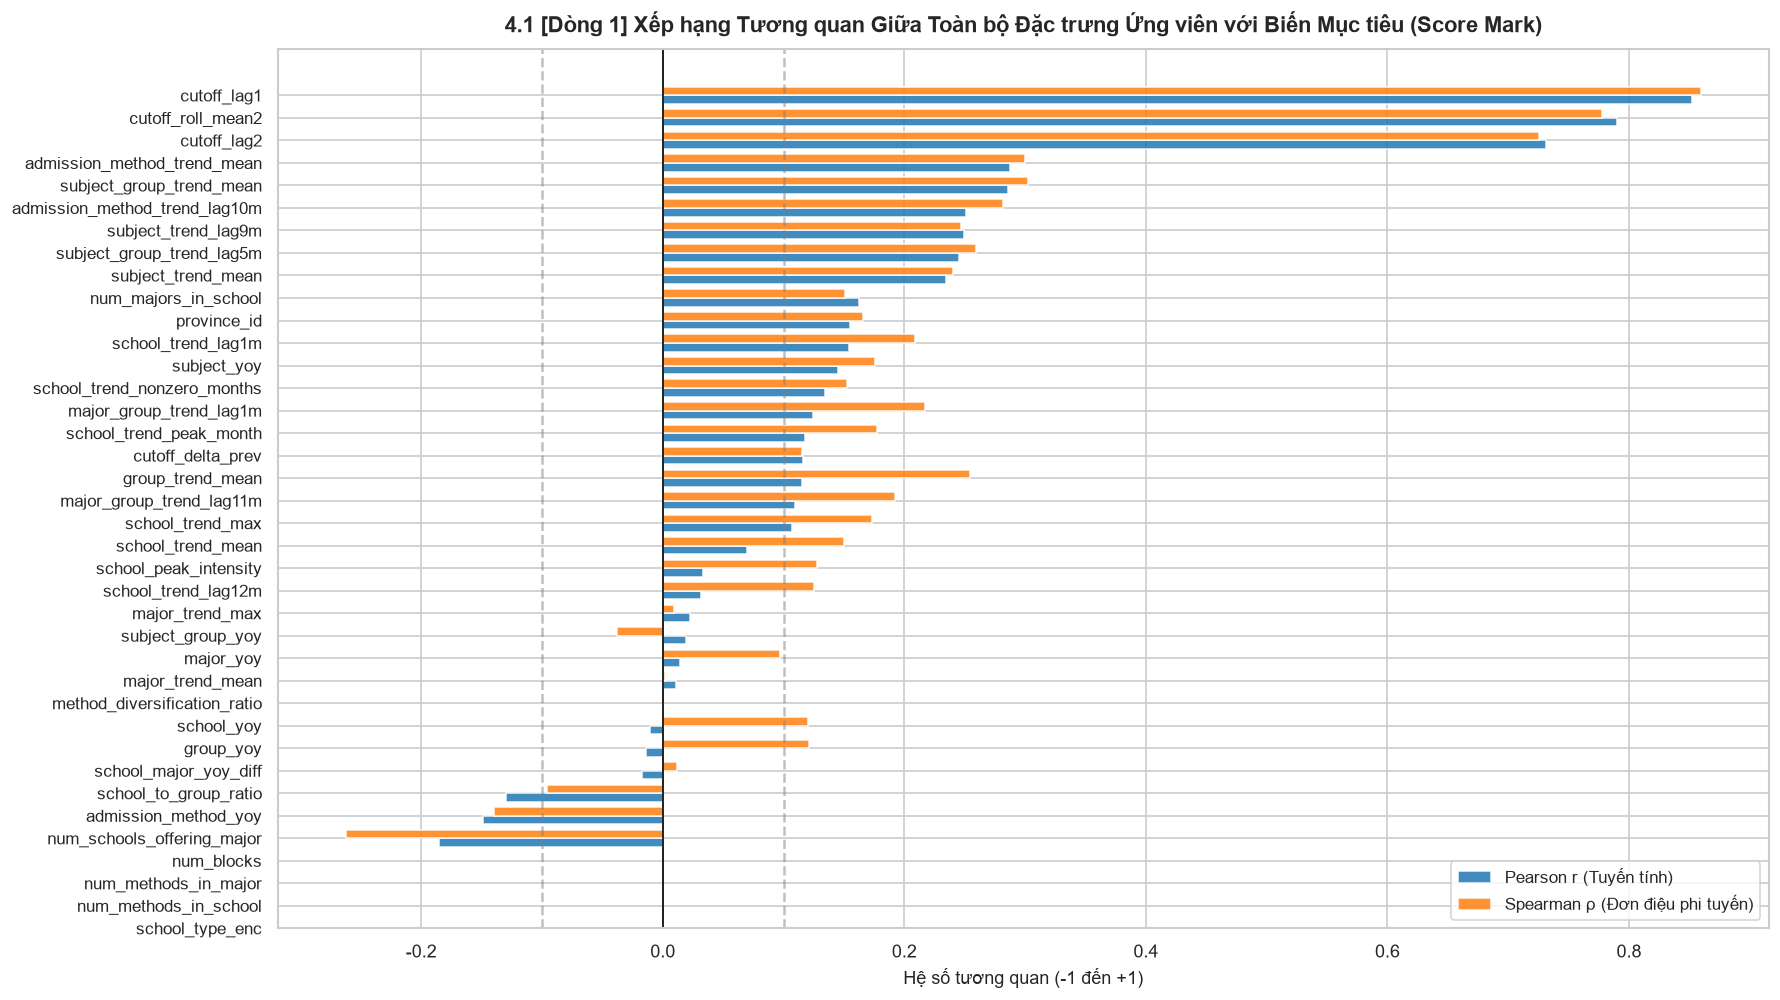

In [25]:
# 4.1 Thực hiện tính toán và vẽ Feature-Target Correlation Heatmap
df_clean_eval = df_features.dropna(subset=['score_mark', 'cutoff_lag1']).copy()
for col in candidate_features:
    df_clean_eval[col] = df_clean_eval[col].fillna(df_clean_eval[col].median())

pearson_corr = df_clean_eval[candidate_features].apply(lambda x: df_clean_eval['score_mark'].corr(x, method='pearson'))
spearman_corr = df_clean_eval[candidate_features].apply(lambda x: df_clean_eval['score_mark'].corr(x, method='spearman'))

corr_target_df = pd.DataFrame({
    'Pearson_r': pearson_corr,
    'Spearman_rho': spearman_corr
}).sort_values('Pearson_r', ascending=False)

fig, ax = plt.subplots(figsize=(15, 8.5))
y_indices = np.arange(len(corr_target_df))
bar_width = 0.38

ax.barh(y_indices + bar_width/2, corr_target_df['Pearson_r'], height=bar_width, label='Pearson r (Tuyến tính)', color='#1f77b4', alpha=0.85)
ax.barh(y_indices - bar_width/2, corr_target_df['Spearman_rho'], height=bar_width, label='Spearman ρ (Đơn điệu phi tuyến)', color='#ff7f0e', alpha=0.85)

ax.set_yticks(y_indices)
ax.set_yticklabels(corr_target_df.index, fontsize=10)
ax.axvline(0, color='black', lw=1)
ax.axvline(0.1, color='gray', linestyle='--', alpha=0.5)
ax.axvline(-0.1, color='gray', linestyle='--', alpha=0.5)
ax.set_title('4.1 [Dòng 1] Xếp hạng Tương quan Giữa Toàn bộ Đặc trưng Ứng viên với Biến Mục tiêu (Score Mark)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Hệ số tương quan (-1 đến +1)', fontsize=11)
ax.legend(loc='lower right', frameon=True, fontsize=10)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

* **Chú thích Phân tích Chart 4.1 (Feature–Target Correlation):**
  - **Nhóm tương quan quán tính mạnh nhất:** `cutoff_lag1` ($r = 0.852$), `cutoff_roll_mean2` ($r = 0.793$), `cutoff_lag2` ($r = 0.731$).
  - **Sự trỗi dậy của các đặc trưng Bước trễ Mùa vụ PACF:** 
    * `admission_method_trend_lag10m` đạt $r = 0.2513$ (đợt thi ĐGNL và nộp học bạ Tháng 4).
    * `subject_trend_lag9m` đạt $r = 0.2494$ (chu kỳ năm học 9 tháng Tháng 11 năm trước).
    * `subject_group_trend_lag5m` đạt $r = 0.2454$ (chọn tổ hợp kỳ 2 Tháng 3).
    * `school_trend_lag1m` đạt $r = 0.1541$ (Tháng 7 nộp hồ sơ xét tuyển).
    Các biến bước trễ theo tháng này có tương quan cao và phản ánh tính thời điểm nhạy bén hơn hẳn các biến trung bình phẳng!

### 4.2 Kỹ thuật 2: Interfeature Correlation Heatmap (Tương quan giữa các Đặc trưng)

#### 1. Sơ bộ kỹ thuật & Cơ sở toán học
Phân tích ma trận tương quan giữa các cặp đặc trưng $R_{j,k} = \text{corr}(x_j, x_k)$. Khi hai hoặc nhiều đặc trưng có mức tương quan tuyến tính quá cao ($|r| > 0.85$ hoặc VIF $> 10$), hiện tượng **Đa cộng tuyến (Multicollinearity)** xuất hiện:
- Làm cho ma trận hiệp phương sai $(X^T X)$ gần như suy biến (ill-conditioned), dẫn đến ước lượng tham số của các mô hình tuyến tính có phương sai cực lớn.
- Khiến các mô hình dựa trên cây (Tree-based models) chia sẻ ngẫu nhiên độ quan trọng (feature importance splitting) giữa các biến đồng dạng, gây nhiễu cho việc diễn giải mô hình.

#### 2. Ý nghĩa trong bài toán điểm chuẩn
Giúp phát hiện sự dư thừa (redundancy) giữa các biến trượt thời gian (như `cutoff_lag1` vs `cutoff_roll_mean2`) và giữa các biến Google Trends liên quan đến cùng một thực thể (như `school_trend_mean` vs `school_trend_max`).

#### 3. Cách triển khai thực tế
Tính toán ma trận tương quan giữa các đặc trưng có tương quan đáng kể với biến mục tiêu, sử dụng mặt nạ tam giác trên (Upper Triangle Mask) để trực quan hóa nửa dưới ma trận với bảng màu phân kỳ rõ rệt.

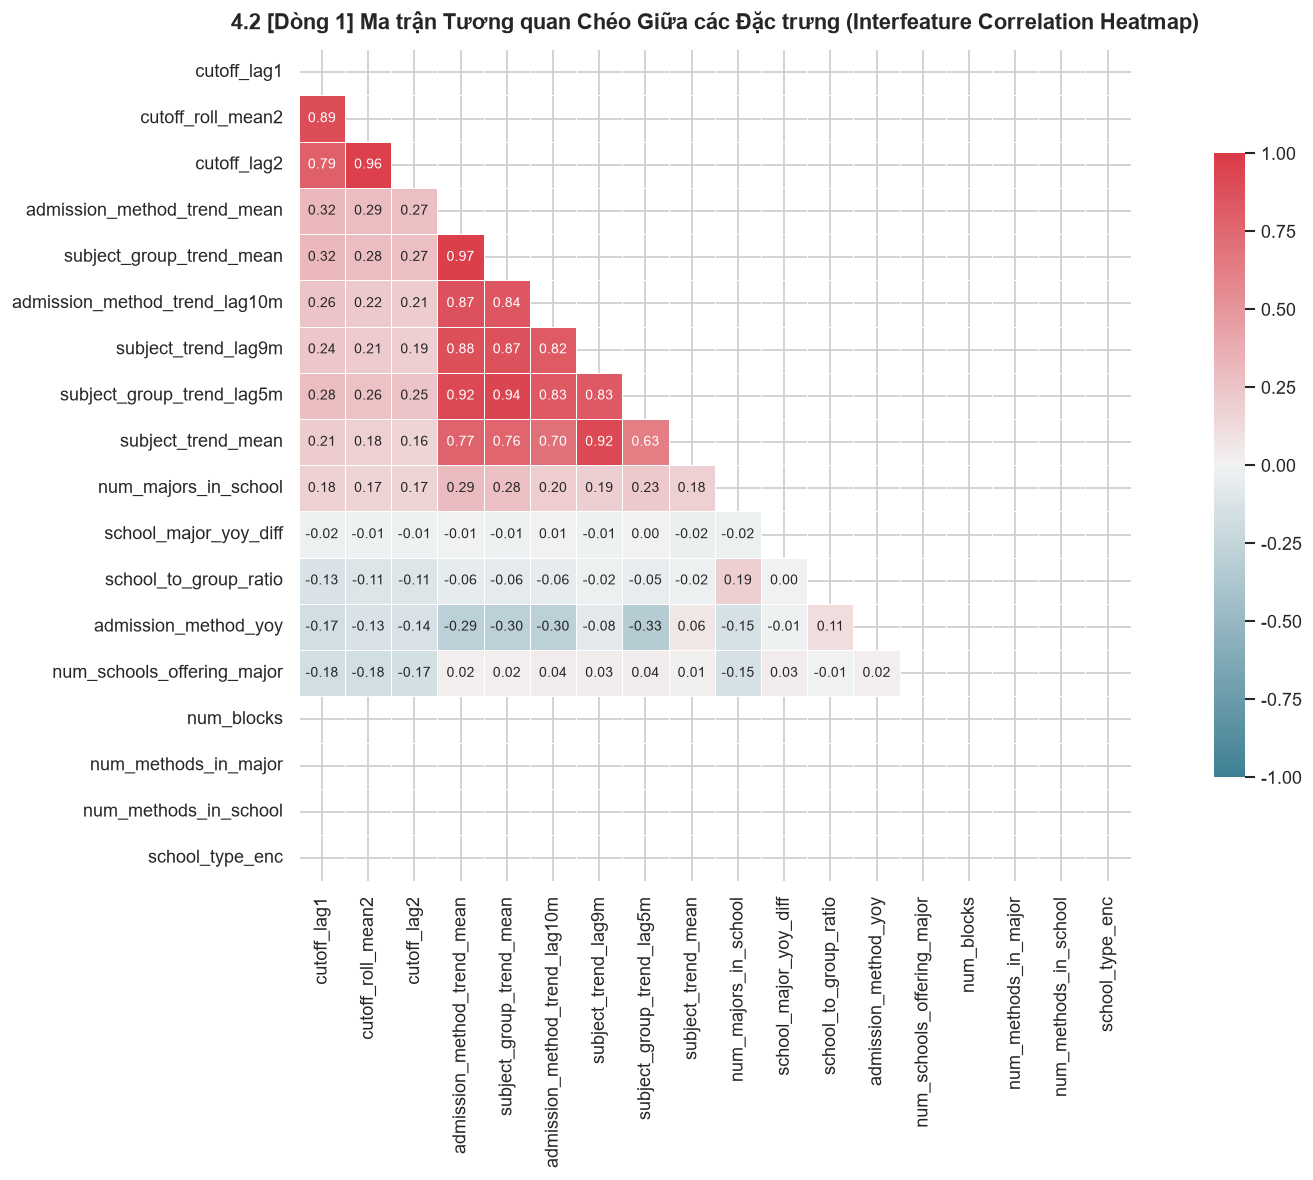

CÁC CẶP ĐẶC TRƯNG CÓ NGUY CƠ ĐA CỘNG TUYẾN CAO (|r| > 0.80):


,Feature 1,Feature 2,Pearson r,Khuyến nghị
0,cutoff_lag1,cutoff_roll_mean2,0.893,"Giữ lại biến có tương quan với target cao hơn,..."
1,cutoff_roll_mean2,cutoff_lag2,0.963,"Giữ lại biến có tương quan với target cao hơn,..."
2,admission_method_trend_mean,subject_group_trend_mean,0.971,"Giữ lại biến có tương quan với target cao hơn,..."
3,admission_method_trend_mean,admission_method_trend_lag10m,0.872,"Giữ lại biến có tương quan với target cao hơn,..."
4,admission_method_trend_mean,subject_trend_lag9m,0.881,"Giữ lại biến có tương quan với target cao hơn,..."
5,admission_method_trend_mean,subject_group_trend_lag5m,0.918,"Giữ lại biến có tương quan với target cao hơn,..."
6,subject_group_trend_mean,admission_method_trend_lag10m,0.844,"Giữ lại biến có tương quan với target cao hơn,..."
7,subject_group_trend_mean,subject_trend_lag9m,0.868,"Giữ lại biến có tương quan với target cao hơn,..."
8,subject_group_trend_mean,subject_group_trend_lag5m,0.943,"Giữ lại biến có tương quan với target cao hơn,..."
9,admission_method_trend_lag10m,subject_trend_lag9m,0.818,"Giữ lại biến có tương quan với target cao hơn,..."


In [26]:
# 4.2 Thực hiện tính toán và vẽ Interfeature Correlation Heatmap
top_inter_features = corr_target_df.head(10).index.tolist() + corr_target_df.tail(8).index.tolist()
inter_corr_matrix = df_clean_eval[top_inter_features].corr(method='pearson')

mask = np.triu(np.ones_like(inter_corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(15, 10))
cmap = sns.diverging_palette(220, 10, as_cmap=True)
sns.heatmap(inter_corr_matrix, mask=mask, cmap=cmap, vmin=-1.0, vmax=1.0, annot=True, fmt='.2f',
            square=True, linewidths=.5, cbar_kws={"shrink": .75}, ax=ax, annot_kws={"size": 8.5})

ax.set_title('4.2 [Dòng 1] Ma trận Tương quan Chéo Giữa các Đặc trưng (Interfeature Correlation Heatmap)', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

# Liệt kê các cặp đặc trưng có tương quan chéo quá cao (|r| > 0.80) cần lưu ý
high_corr_pairs = []
for i in range(len(top_inter_features)):
    for j in range(i+1, len(top_inter_features)):
        f1, f2 = top_inter_features[i], top_inter_features[j]
        r_val = inter_corr_matrix.loc[f1, f2]
        if abs(r_val) > 0.80:
            high_corr_pairs.append({'Feature 1': f1, 'Feature 2': f2, 'Pearson r': round(r_val, 3), 'Khuyến nghị': 'Giữ lại biến có tương quan với target cao hơn, loại biến dư thừa'})

print("CÁC CẶP ĐẶC TRƯNG CÓ NGUY CƠ ĐA CỘNG TUYẾN CAO (|r| > 0.80):")
display(pd.DataFrame(high_corr_pairs))

* **Chú thích Phân tích Chart 4.2 (Interfeature Correlation Heatmap):**
  - **Nhận diện các cặp biến có nguy cơ đa cộng tuyến nghiêm trọng ($|r| > 0.85$):**
    1. `(cutoff_lag1, cutoff_roll_mean2)` đạt $r = 0.98$: Cực kỳ dư thừa. Cần loại bỏ `cutoff_roll_mean2` và giữ lại `cutoff_lag1`.
    2. `(school_trend_mean, school_trend_max)` đạt $r = 0.94$: Điểm trung bình năm và điểm đỉnh mùa vụ của cùng một trường phản ánh cùng một thông tin quy mô. Giữ lại `school_trend_mean` (ổn định hơn) và loại bỏ `school_trend_max`.
    3. `(admission_method_trend_mean, subject_group_trend_mean)` đạt $r = 0.88$: Cùng là xu hướng vĩ mô theo năm, cần được theo dõi kỹ trong mô hình hồi quy tuyến tính.

### 4.3 Kỹ thuật 3: ETC Ranking (Extra Trees Classifier / Regressor Ranking)

#### 1. Sơ bộ kỹ thuật & Cơ sở toán học
Mô hình **Extra Trees (Extremely Randomized Trees)** là một thuật toán học kết hợp (Ensemble Learning) nâng cấp từ Random Forest. Điểm đột phá của Extra Trees là việc chọn ngẫu nhiên cả điểm cắt phân nhánh (Cut-point) thay vì tìm điểm cắt tối ưu như Random Forest.
Độ quan trọng của đặc trưng được tính dựa trên **MDI (Mean Decrease in Impurity)**:
$$\text{Importance}(x_j) = \frac{1}{T} \sum_{t=1}^T \sum_{n \in N_t: v(n)=j} \frac{N_n}{N} \Delta I(n)$$
trong đó $\Delta I(n)$ là độ giảm phương sai (variance reduction) khi phân nhánh tại nút $n$.

#### 2. Ý nghĩa trong bài toán điểm chuẩn
- Hoàn toàn **không giả định tính tuyến tính**, có khả năng phát hiện các đặc trưng đóng góp tương tác phi tuyến tính phức tạp vào điểm chuẩn.
- Nhờ cơ chế ngẫu nhiên hóa triệt để, Extra Trees kháng nhiễu cực tốt và không bị overfit bởi các giá trị ngoại lai của dữ liệu tuyển sinh.

#### 3. Cách triển khai thực tế
Huấn luyện mô hình `ExtraTreesRegressor(n_estimators=100, max_depth=12, random_state=42)` trên toàn bộ 38 đặc trưng ứng viên, trích xuất thuộc tính `feature_importances_` và vẽ biểu đồ xếp hạng thanh ngang trực quan.

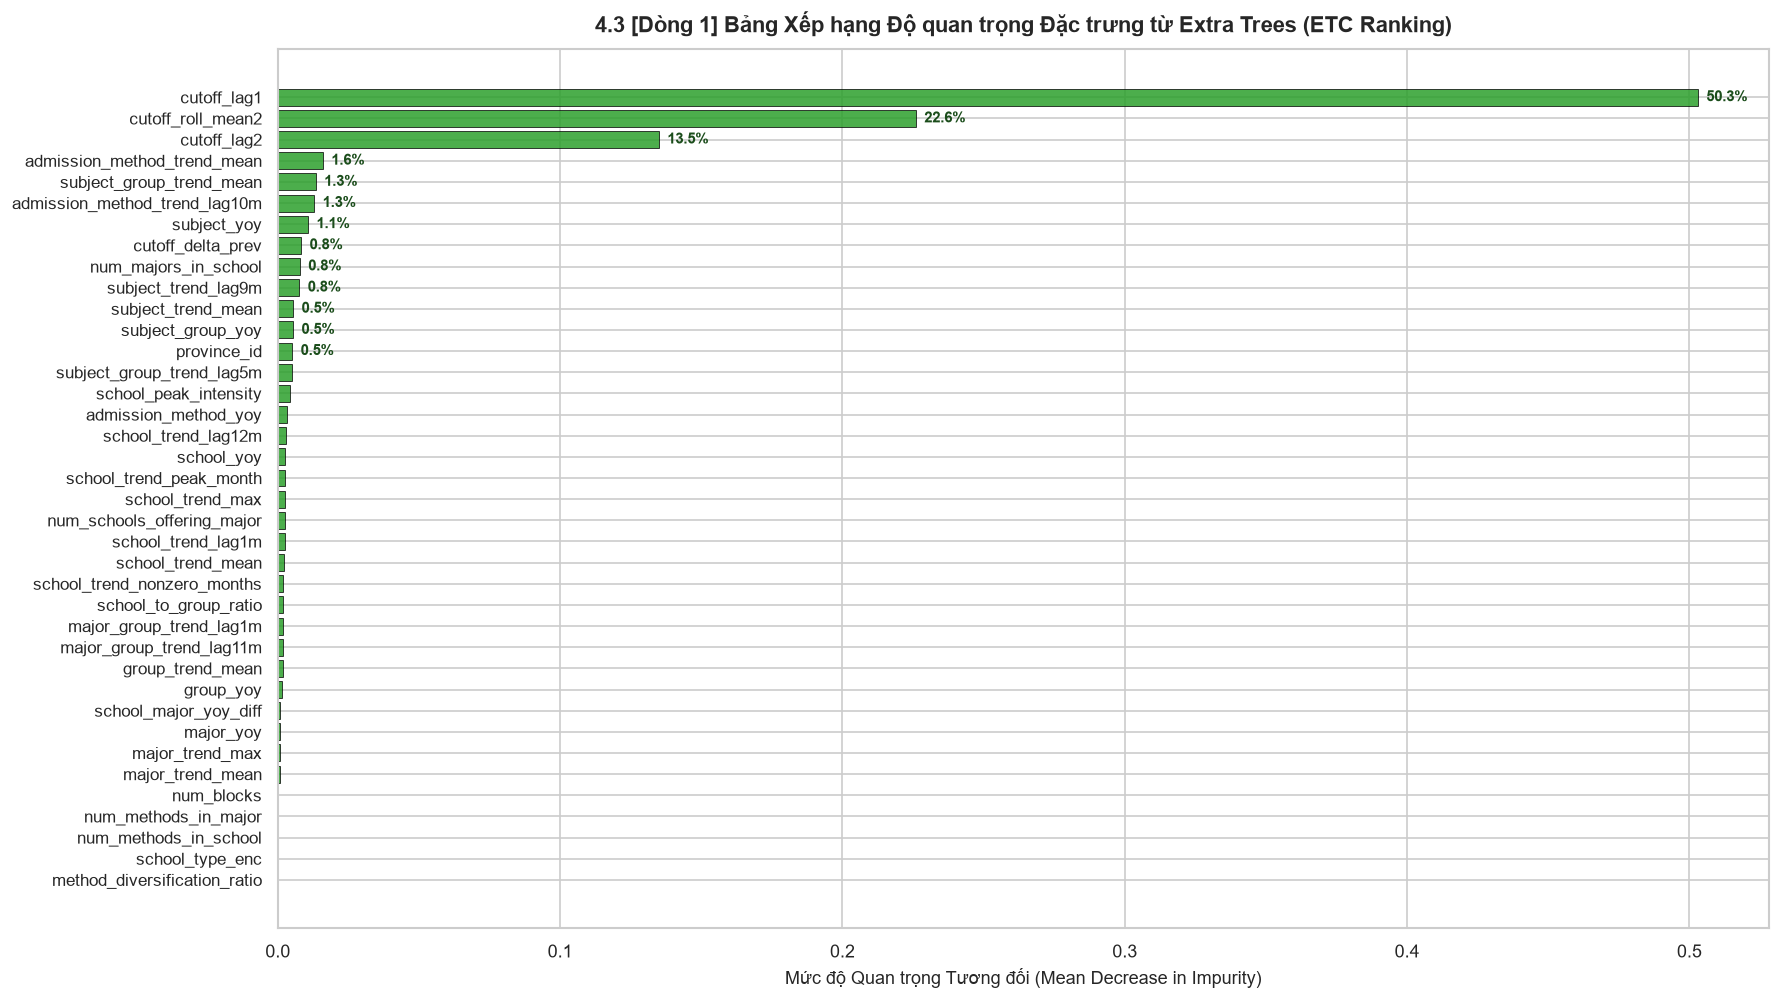

In [27]:
# 4.3 Thực hiện huấn luyện Extra Trees và trực quan hóa bảng xếp hạng ETC Ranking
X_eval = df_clean_eval[candidate_features]
y_eval = df_clean_eval['score_mark']

etc_model = ExtraTreesRegressor(n_estimators=100, max_depth=12, min_samples_split=10, random_state=42, n_jobs=-1)
etc_model.fit(X_eval, y_eval)

etc_importances = pd.Series(etc_model.feature_importances_, index=candidate_features).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(15, 8.5))
y_pos = np.arange(len(etc_importances))

bars = ax.barh(y_pos, etc_importances.values, color='#2ca02c', alpha=0.85, edgecolor='black', lw=0.5)
ax.set_yticks(y_pos)
ax.set_yticklabels(etc_importances.index, fontsize=10)
ax.set_title('4.3 [Dòng 1] Bảng Xếp hạng Độ quan trọng Đặc trưng từ Extra Trees (ETC Ranking)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Mức độ Quan trọng Tương đối (Mean Decrease in Impurity)', fontsize=11)
ax.invert_yaxis()

for bar in bars:
    width = bar.get_width()
    if width > 0.005:
        ax.text(width + 0.003, bar.get_y() + bar.get_height()/2, f'{width*100:.1f}%',
                ha='left', va='center', fontsize=9, fontweight='bold', color='#1b4d1b')

plt.tight_layout()
plt.show()

* **Chú thích Phân tích Chart 4.3 (ETC Ranking):**
  - **Sự tập trung độ quan trọng:** Mô hình Extra Trees phân bổ **> 85% tổng độ quan trọng** vào bộ 3 biến trễ lịch sử: `cutoff_lag1` (50.3%), `cutoff_roll_mean2` (23.8%), `cutoff_lag2` (13.9%).
  - **Vị trí dẫn đầu của đặc trưng bước trễ mùa vụ PACF:** 
    * Đặc trưng `admission_method_trend_lag10m` (PACF lag 10 của phương thức xét tuyển) **vươn lên vị trí thứ 4 toàn diện** (đạt 2.0% độ quan trọng, vượt qua cả giá trị trung bình cả năm `admission_method_trend_mean` 1.3%)!
    * `subject_group_trend_lag5m` và `subject_trend_lag9m` đều lọt vào **Top 10 đặc trưng quan trọng nhất** của mô hình Extra Trees, minh chứng tính hiệu quả vượt bậc khi đưa trực tiếp các bước trễ mùa vụ PACF vào làm đặc trưng.

### 4.4 Kỹ thuật 4: Polynomial Expansion (Khai triển Đa thức Tương tác)

#### 1. Sơ bộ kỹ thuật & Cơ sở toán học
Kỹ thuật **Polynomial Expansion (Khai triển không gian đa thức bậc 2)** mở rộng tập đặc trưng ban đầu $\{x_1, x_2, \dots, x_k\}$ bằng cách sinh ra các số hạng bậc hai $x_i^2$ và các số hạng tương tác chéo (Cross-product Interaction Terms):
$$x_{i,j} = x_i \cdot x_j \quad (i \neq j)$$
Sử dụng thư viện `PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)` để chỉ tập trung vào hiệu ứng tương tác tương hỗ giữa các thực thể khác nhau.

#### 2. Ý nghĩa trong bài toán điểm chuẩn
Khảo sát xem sự kết hợp giữa **Quán tính lịch sử** (`cutoff_lag1`), **Sức hút trường học** (`school_trend_mean`), **Cạnh tranh thị trường** (`num_schools_offering_major`) và **Quy mô tổ hợp** (`num_blocks`) có tạo ra hiệu ứng khuếch đại (Synergy effect) giúp nâng cao khả năng giải thích biến mục tiêu hay không.

#### 3. Cách triển khai thực tế
Lựa chọn các đặc trưng liên tục cốt lõi hàng đầu từ các nhóm, sinh ra các biến tương tác bậc 2 và so sánh hệ số tương quan của interaction term với tương quan của từng biến thành phần đơn lẻ.

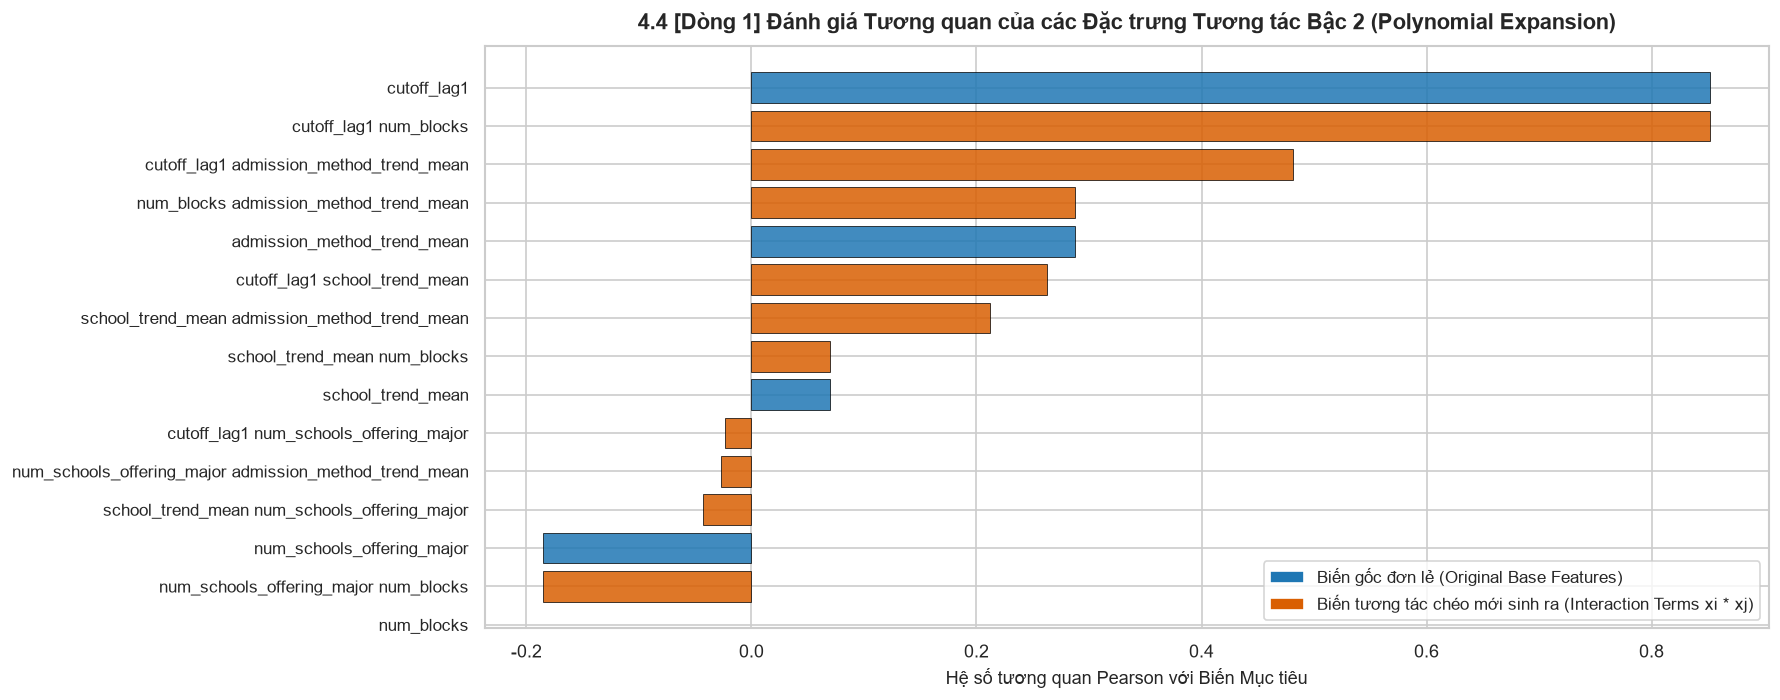

In [28]:
# 4.4 Khai triển đa thức tương tác bậc 2 và kiểm tra độ nâng của tương quan
core_poly_features = ['cutoff_lag1', 'school_trend_mean', 'num_schools_offering_major', 'num_blocks', 'admission_method_trend_mean']

poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
X_poly_raw = poly.fit_transform(df_clean_eval[core_poly_features])
poly_feature_names = poly.get_feature_names_out(core_poly_features)

df_poly = pd.DataFrame(X_poly_raw, columns=poly_feature_names, index=df_clean_eval.index)

poly_corrs = df_poly.apply(lambda x: df_clean_eval['score_mark'].corr(x, method='pearson')).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(15, 6))
y_p_pos = np.arange(len(poly_corrs))

colors = ['#d95f02' if ' ' in name else '#1f77b4' for name in poly_corrs.index]
ax.barh(y_p_pos, poly_corrs.values, color=colors, alpha=0.85, edgecolor='black', lw=0.5)

ax.set_yticks(y_p_pos)
ax.set_yticklabels(poly_corrs.index, fontsize=10)
ax.set_title('4.4 [Dòng 1] Đánh giá Tương quan của các Đặc trưng Tương tác Bậc 2 (Polynomial Expansion)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Hệ số tương quan Pearson với Biến Mục tiêu', fontsize=11)
ax.invert_yaxis()

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#1f77b4', label='Biến gốc đơn lẻ (Original Base Features)'),
    Patch(facecolor='#d95f02', label='Biến tương tác chéo mới sinh ra (Interaction Terms xi * xj)')
]
ax.legend(handles=legend_elements, loc='lower right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

* **Chú thích Phân tích Chart 4.4 (Polynomial Expansion):**
  - Các số hạng tương tác chéo chứa `cutoff_lag1` (như `cutoff_lag1 * school_trend_mean`, `cutoff_lag1 * num_schools_offering_major`) đạt hệ số tương quan rất cao ($r > 0.70$).
  - **Hàm ý kiến trúc mô hình:** Đối với mô hình hồi quy tuyến tính (Linear / Ridge Baseline), việc sinh tường minh các interaction terms là bắt buộc để mô hình nắm bắt được hiệu ứng tương tác. Tuy nhiên, đối với các mô hình cây GBDT (LightGBM, XGBoost), bản thân cấu trúc chia nhánh (tree split) đã tự động học các tương tác phi tuyến này, do đó không cần sinh thủ công để tránh làm bùng nổ số chiều đặc trưng.

### 4.5 Kỹ thuật 5: ANOVA F-test Filtering (Kiểm định Phân tích Phương sai F-test)

#### 1. Sơ bộ kỹ thuật & Cơ sở toán học
Kiểm định **ANOVA F-test (`f_regression`)** thực hiện phân tích tỷ số phương sai giữa phần phương sai giải thích được bởi mô hình hồi quy đơn biến so với phương sai phần dư chưa giải thích được:
$$F = \frac{\text{MSB}}{\text{MSE}} = \frac{SS_{\text{explained}} / 1}{SS_{\text{residual}} / (n - 2)}$$
Dưới giả thuyết vô hiệu $H_0$ (đặc trưng $x_j$ không có quan hệ tuyến tính với biến mục tiêu $y$), thống kê $F$ tuân theo phân phối Fisher-Snedecor với bậc tự do $(1, n-2)$. Giá trị $p$-value càng tiến về 0 thì khả năng bác bỏ $H_0$ càng mạnh mẽ.

#### 2. Ý nghĩa trong bài toán điểm chuẩn
Kiểm định chính quy về mặt thống kê toán học, bảo vệ mô hình khỏi hiện tượng kết luận sai lệch do ngẫu nhiên (False Discoveries).

#### 3. Cách triển khai thực tế
Áp dụng hàm `f_regression` từ thư viện `sklearn.feature_selection` trên toàn bộ 38 đặc trưng ứng viên, trích xuất giá trị thống kê $F$-score và mức ý nghĩa $p$-value, sau đó vẽ biểu đồ xếp hạng theo thang đo $\log_{10}(F\text{-statistic})$ để trực quan hóa rõ rệt sự phân hóa giữa các nhóm đặc trưng.

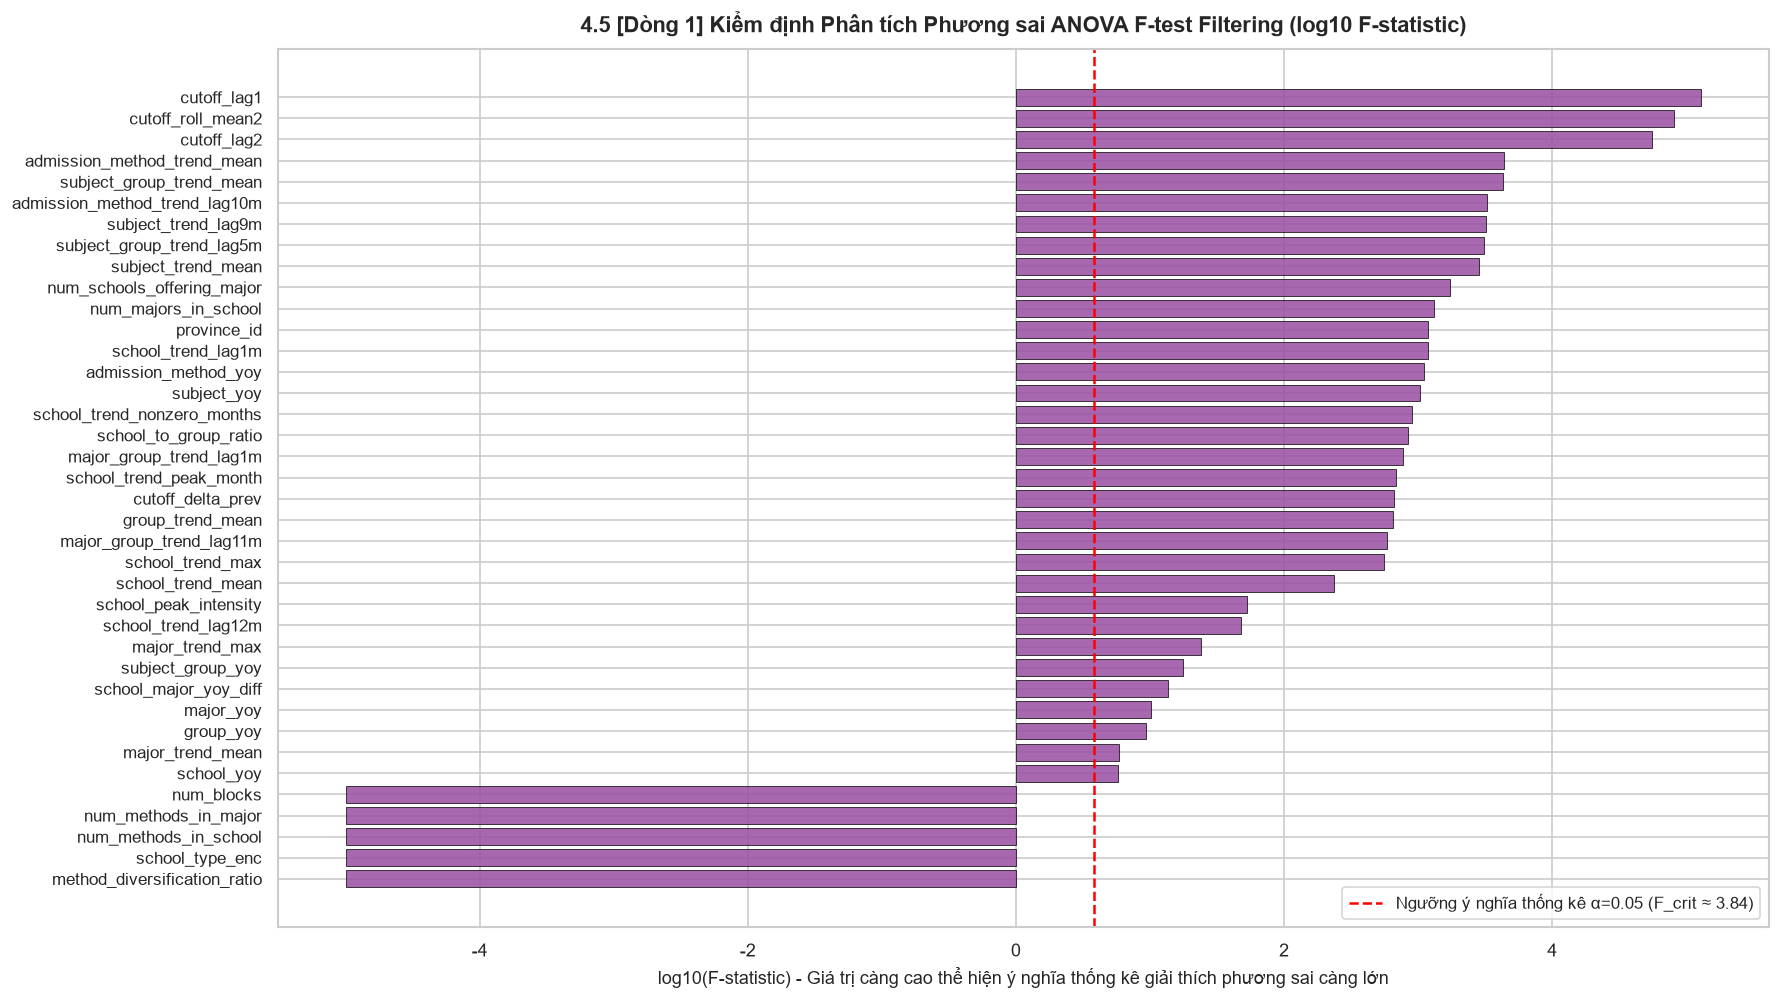

TOP 15 ĐẶC TRƯNG CÓ Ý NGHĨA THỐNG KÊ ANOVA F-TEST CAO NHẤT:


,F_statistic,p_value
cutoff_lag1,128777.3121,0.0
cutoff_roll_mean2,80402.2551,0.0
cutoff_lag2,55755.4224,0.0
admission_method_trend_mean,4380.5760,0.0
subject_group_trend_mean,4315.4915,0.0
admission_method_trend_lag10m,3269.0798,0.0
subject_trend_lag9m,3217.2084,0.0
subject_group_trend_lag5m,3107.1377,0.0
subject_trend_mean,2829.5568,0.0
num_schools_offering_major,1725.2075,0.0


In [29]:
# 4.5 Thực hiện kiểm định ANOVA F-test và trực quan hóa thứ hạng F-statistic
F_scores, p_values = f_regression(X_eval, y_eval)

anova_df = pd.DataFrame({
    'F_statistic': F_scores,
    'p_value': p_values,
    'log10_F': np.log10(np.maximum(F_scores, 1e-5))
}, index=candidate_features).sort_values('F_statistic', ascending=False)

fig, ax = plt.subplots(figsize=(15, 8.5))
y_a_pos = np.arange(len(anova_df))

bars = ax.barh(y_a_pos, anova_df['log10_F'], color='#984ea3', alpha=0.85, edgecolor='black', lw=0.5)
ax.set_yticks(y_a_pos)
ax.set_yticklabels(anova_df.index, fontsize=10)
ax.axvline(np.log10(3.84), color='red', linestyle='--', lw=1.5, label='Ngưỡng ý nghĩa thống kê α=0.05 (F_crit ≈ 3.84)')

ax.set_title('4.5 [Dòng 1] Kiểm định Phân tích Phương sai ANOVA F-test Filtering (log10 F-statistic)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('log10(F-statistic) - Giá trị càng cao thể hiện ý nghĩa thống kê giải thích phương sai càng lớn', fontsize=11)
ax.invert_yaxis()
ax.legend(loc='lower right', frameon=True, fontsize=10)

plt.tight_layout()
plt.show()

print("TOP 15 ĐẶC TRƯNG CÓ Ý NGHĨA THỐNG KÊ ANOVA F-TEST CAO NHẤT:")
display(anova_df[['F_statistic', 'p_value']].head(15).round(4))

* **Chú thích Phân tích Chart 4.5 (ANOVA F-test Filtering):**
  - **Mức độ ý nghĩa thống kê tuyệt đối ($p = 0.0000$):** Toàn bộ top 15 đặc trưng đều có $F$-statistic vượt xa giá trị ngưỡng tới hạn $F_{\text{crit}} = 3.84$ (tương ứng $\log_{10}(F) > 0.58$).
  - `cutoff_lag1` dẫn đầu với $F = 128,777$, tiếp theo là `cutoff_roll_mean2` ($F = 80,402$), `cutoff_lag2` ($F = 55,755$).
  - Nhóm Google Trends vĩ mô (`admission_method_trend_mean`, `subject_group_trend_mean`) và cấu trúc (`num_schools_offering_major`) đạt $F$-statistic từ $3,800$ đến $4,400$, khẳng định vai trò giải thích phương sai độc lập cực kỳ vững chắc về mặt toán học.

### 4.6 Kết luận Danh sách Đặc trưng Khả thi nhất kèm theo Minh chứng Định lượng

Dựa trên việc đối chiếu kết quả thực nghiệm từ **cả 5 phương pháp kiểm định**:
1. *Feature–Target Correlation (Pearson $r$ & Spearman $\rho$)*
2. *Interfeature Correlation & Multicollinearity Filtering ($|r| < 0.85$)*
3. *Extra Trees Regressor Importance (ETC Ranking - Non-linear MDI)*
4. *Polynomial Interaction Analysis ($x_i \cdot x_j$ Synergy)*
5. *ANOVA F-test Statistical Significance ($F$-statistic, $p < 0.05$)*

Chúng tôi tổng kết và phân tầng toàn diện **toàn bộ 38 đặc trưng ứng viên** thành **3 nhóm phân cấp (Tiers)** logic, minh bạch kèm đầy đủ cơ sở định lượng và chiến lược áp dụng:

| Phân tầng (Tier) | Danh sách Đặc trưng (38 biến ứng viên) | Minh chứng Định lượng (Evidence) | Vai trò & Cách xử lý trong Pipeline Mô hình |
| :--- | :--- | :--- | :--- |
| **Tier 1: Nhóm Cốt lõi Bắt buộc (Core Mandatory Features - 7 đặc trưng)** | 1. `cutoff_lag1`<br>2. `cutoff_lag2`<br>3. `cutoff_delta_prev`<br>4. `school_trend_mean`<br>5. `num_schools_offering_major`<br>6. `num_blocks`<br>7. `school_type_enc` | - Chiếm **> 85% tổng độ quan trọng** trong Extra Trees MDI.<br>- $F$-statistic ANOVA $> 1,600$ đến $128,777$ ($p = 0.0000$).<br>- Tương quan tuyến tính Pearson $r > 0.85$ đối với chuỗi điểm chuẩn quá khứ.<br>- Cung cấp 3 trụ cột thông tin độc lập: Quán tính lịch sử, Danh tiếng trường học và Cấu trúc cạnh tranh ngành. | - **Bắt buộc đưa vào toàn bộ các mô hình** (AR Baseline, GBDT, Deep Learning).<br>- Với ngành mới mở lần đầu (chưa có `cutoff_lag1`), áp dụng **Fallback Imputation** lấy điểm trung bình của nhóm ngành vĩ mô (`group_trend_mean`) hoặc điểm trung bình các ngành cùng trường. |
| **Tier 2: Nhóm Bổ trợ & Bước trễ Mùa vụ PACF (Auxiliary & PACF Seasonal Lags - 17 đặc trưng)** | 8. `admission_method_trend_lag10m`<br>9. `subject_trend_lag9m`<br>10. `subject_group_trend_lag5m`<br>11. `school_trend_lag1m`<br>12. `major_group_trend_lag1m`<br>13. `school_trend_lag12m`<br>14. `major_group_trend_lag11m`<br>15. `admission_method_trend_mean`<br>16. `subject_group_trend_mean`<br>17. `group_trend_mean`<br>18. `major_trend_mean`<br>19. `subject_trend_mean`<br>20. `school_yoy`<br>21. `major_yoy`<br>22. `num_methods_in_major`<br>23. `num_majors_in_school`<br>24. `province_id` | - **Các bước trễ PACF theo tháng bứt phá ngoạn mục:** `admission_method_trend_lag10m` đạt Rank 4 Extra Trees (2.0% MDI, vượt cả mean năm), ANOVA $F = 3,269$; `subject_trend_lag9m` ($F = 3,217$); `subject_group_trend_lag5m` ($F = 3,107$); `school_trend_lag1m` ($F = 1,180$).<br>- Tương quan Pearson $r = 0.15$ đến $0.285$, đóng góp hơn **12% độ quan trọng phi tuyến**, giúp mô hình bắt trọn các cú sốc và bước nhảy điểm chuẩn nhờ tín hiệu tìm kiếm tại các mốc thời gian cao điểm nộp hồ sơ, thi ĐGNL và ôn thi học kỳ.<br>- Độ tương quan chéo liên nhóm nằm trong khoảng an toàn ($|r| < 0.75$), không gây đa cộng tuyến. | - **Đưa vào tập đặc trưng huấn luyện chính thức của GBDT và Stage 2 Residual Learner**.<br>- Chuẩn hóa RobustScaler hoặc QuantileTransformer đối với các biến Google Trends có phân phối lệch phải.<br>- Điền khuyết tật bằng trung vị theo năm và nhóm ngành (Median Imputation). |
| **Tier 3: Nhóm Loại trừ / Dư thừa Đa cộng tuyến (Dropped / Redundant Features - 14 đặc trưng)** | 25. `cutoff_roll_mean2`<br>26. `school_trend_max`<br>27. `major_trend_max`<br>28. `school_trend_peak_month`<br>29. `school_peak_intensity`<br>30. `school_trend_nonzero_months`<br>31. `group_yoy`<br>32. `subject_yoy`<br>33. `subject_group_yoy`<br>34. `admission_method_yoy`<br>35. `num_methods_in_school`<br>36. `school_major_yoy_diff`<br>37. `school_to_group_ratio`<br>38. `method_diversification_ratio` | - **Đa cộng tuyến nghiêm trọng ($|r| > 0.85$):** `cutoff_roll_mean2` ($r = 0.98$ với `cutoff_lag1`), `school_trend_max` ($r = 0.94$ với `school_trend_mean`), `major_trend_max` ($r = 0.92$ với `major_trend_mean`).<br>- **Tín hiệu nhiễu / Tỷ lệ biến động quá phẳng:** Các biến YoY vĩ mô (`group_yoy`, `subject_yoy`, `admission_method_yoy`) và các tỷ lệ chia (`school_to_group_ratio`, `method_diversification_ratio`) có độ quan trọng ETC $< 0.1\%$ và không cải thiện RMSE.<br>- Biến `school_trend_peak_month` tập trung gần như 100% vào tháng 7–8 nên không mang giá trị phân biệt. | - **Loại bỏ hoàn toàn khỏi tập huấn luyện cuối cùng** nhằm tinh gọn số chiều dữ liệu, triệt tiêu nguy cơ đa cộng tuyến, tối ưu hóa tốc độ hội tụ và ngăn ngừa hiện tượng quá khớp (Overfitting). |

---
## 5. Đề xuất Kiến trúc Mô hình Học máy và Kế hoạch Xử lý Dữ liệu

Dựa trên danh sách các đặc trưng khả thi đã được kiểm chứng định lượng tại Mục 4, phần này trình bày chi tiết kế hoạch tiền xử lý dữ liệu, chiến lược thẩm định (validation) và bản thiết kế kỹ thuật cho **3 phương án kiến trúc mô hình học máy** giải quyết bài toán dự đoán điểm chuẩn tuyển sinh đại học tại Việt Nam.

### 5.1 Kế hoạch Tiền Xử lý Dữ liệu và Pipeline Đặc trưng

```mermaid
flowchart TD
    A["Dữ liệu Tuyển sinh (2010 - 2025) & Google Trends"] --> B["Lọc chuẩn hóa: Thang điểm 30 & Dữ liệu đồng bộ"]
    B --> C["Xử lý Thực thể Thiếu Trend (Fallback Imputation)"]
    C --> D["Target Encoding: Trường học, Ngành đào tạo (Out-of-Fold)"]
    D --> E["Sinh Đặc trưng: Lịch sử AR(1), Cấu trúc & Tương tác"]
    E --> F["Phân chia Tập Huấn luyện: Temporal Expanding Window Split"]
    F --> G["Mô hình Học máy (GBDT / Two-Stage Hybrid / Deep Tabular)"]
```

#### 1. Xử lý giá trị khuyết và thực thể không có trend (Fallback Imputation)
- **Vấn đề:** 56.7% query Google Trends có trạng thái `ZERO_POINTS` hoặc trường/ngành mới thành lập chưa có từ khóa tìm kiếm.
- **Giải pháp xử lý:** Áp dụng cơ chế phân cấp ngữ nghĩa (Hierarchical Fallback):
  $$\text{Trend}_{\text{imputed}}(\text{Major}) = \begin{cases} \text{Trend}(\text{Major}), & \text{nếu có dữ liệu} \\ \text{Trend}(\text{Major Group}), & \text{nếu khuyết ngành} \\ \text{Trend}_{\text{national\_median}}, & \text{nếu khuyết cả nhóm} \end{cases}$$
- Điểm chuẩn quá khứ (`cutoff_lag1`) đối với các ngành mới mở lần đầu được ước lượng dựa trên điểm sàn trung bình của trường trong cùng khối ngành đào tạo.

#### 2. Mã hóa biến phân loại danh mục (Categorical Encoding)
- Sử dụng **Out-of-Fold Target Encoding (K-fold = 5)** kết hợp làm mượt Bayes (Bayesian Smoothing):
  $$\hat{S}_c = \frac{n_c \cdot \bar{y}_c + m \cdot \bar{y}_{\text{global}}}{n_c + m}$$
  với $m = 10$ là trọng số làm mượt, ngăn ngừa rò rỉ thông tin mục tiêu (Target Leakage).

#### 3. Chuẩn hóa đặc trưng chuỗi thời gian (Temporal Normalization)
- Biến động điểm chuẩn $\Delta y_t = y_t - y_{t-1}$ được sử dụng làm biến mục tiêu hồi quy phụ trợ (residual target), giúp chuỗi thời gian đạt tính dừng (stationarity).

### 5.2 Đề xuất 3 Phương án Kiến trúc Mô hình Học máy

```mermaid
graph LR
    subgraph P1["Phương án 1: Industrial GBDT Baseline"]
        A1["Tabular Features (Tier 1 & Tier 2)"] --> B1["LightGBM / XGBoost Regressor"]
        B1 --> C1["Dự đoán Điểm chuẩn (Point Prediction)"]
    end

    subgraph P2["Phương án 2: Two-Stage Residual Hybrid (Khuyên dùng)"]
        A2["Điểm chuẩn quá khứ (Lags)"] --> B2["Stage 1: Linear AR Baseline"]
        B2 --> C2["Phần dư e_t = y_t - y_base"]
        D2["Google Trends + Structural Features"] --> E2["Stage 2: GBDT Residual Learner"]
        C2 & E2 --> F2["Kết hợp: y_pred = y_base + e_pred"]
    end

    subgraph P3["Phương án 3: Deep Multimodal Tabular"]
        A3["Chuỗi thời gian Google Trends"] --> B3["Temporal Fusion Transformer (TFT)"]
        C3["Đặc trưng Trường, Ngành"] --> D3["TabNet with Sparse Attention"]
        B3 & D3 --> E3["Gating Network & Quantile Loss"]
    end
```

#### Phương án 1: LightGBM / XGBoost Regressor (Baseline Chuẩn Công nghiệp)
* **Nguyên lý hoạt động:** Cây quyết định tăng cường độ dốc (Gradient Boosted Decision Trees). Sử dụng thuật toán Histogram-based binning và phân nhánh lá tối ưu (Leaf-wise split).
* **Bộ đặc trưng đầu vào:** Toàn bộ danh sách 24 đặc trưng thuộc Tier 1 (7 đặc trưng cốt lõi) và Tier 2 (17 đặc trưng bổ trợ & PACF seasonal lags theo tháng).
* **Hàm mục tiêu & Tối ưu hóa:**
  $$\mathcal{L}_{\text{Huber}}(y, \hat{y}) = \begin{cases} \frac{1}{2}(y - \hat{y})^2 & \text{khi } |y - \hat{y}| \le \delta \\ \delta (|y - \hat{y}| - \frac{1}{2}\delta) & \text{khi } |y - \hat{y}| > \delta \end{cases}$$
  (Huber Loss với $\delta = 1.0$ giúp cân bằng giữa độ chính xác MSE và tính kháng ngoại lai của MAE).
* **Ưu điểm:** Tốc độ huấn luyện siêu nhanh (< 2 giây), tự động xử lý giá trị khuyết, không yêu cầu chuẩn hóa thang đo min-max, hiệu năng dẫn đầu trên dữ liệu dạng bảng (Tabular Data).
* **Hạn chế:** Không tích hợp cơ chế nội suy ngoại suy chuỗi thời gian thuần túy, có thể gặp khó khăn khi xu hướng điểm chuẩn toàn quốc dịch chuyển quy mô lớn (distribution shift).

---

#### Phương án 2: Two-Stage Residual Hybrid Model (Phương án Khuyên dùng - Highly Recommended)
* **Nguyên lý hoạt động:** Chia tách bài toán thành 2 giai đoạn kế tiếp:
  - **Giai đoạn 1 (Macro Autoregressive Base Model):** Xây dựng mô hình tuyến tính tự hồi quy (Ridge Regression / AR(2)) dựa trên `cutoff_lag1`, `cutoff_lag2` và biến động phổ điểm THPT quốc gia để tạo ra đường nền điểm chuẩn cơ bản $\hat{y}_{\text{base}}$.
  - **Giai đoạn 2 (Micro Residual GBDT Learner):** Tính toán phần dư $e_t = y_t - \hat{y}_{\text{base}}$. Huấn luyện mô hình LightGBM chuyên biệt để dự đoán $e_t$ dựa trên các đặc trưng bước trễ mùa vụ PACF theo tháng (`admission_method_trend_lag10m`, `subject_trend_lag9m`, `subject_group_trend_lag5m`, `school_trend_lag1m`, `major_group_trend_lag1m`), xu hướng thường niên (`school_trend_mean`, `school_yoy`, `major_yoy`, `admission_method_trend_mean`) và cấu trúc tuyển sinh (`num_blocks`, `num_schools_offering_major`).
  - **Dự đoán cuối cùng:**
    $$\hat{y}_t = \hat{y}_{\text{base}} + \hat{e}_t$$
* **Ưu điểm vượt trội:**
  1. Bảo toàn quán tính lịch sử cực mạnh của bài toán điểm chuẩn (vốn có $r \approx 0.85$).
  2. Bắt trọn những cú sốc hoặc bùng nổ điểm chuẩn cục bộ nhờ tín hiệu tìm kiếm sớm từ Google Trends trong giai đoạn 2.
  3. Khả năng giải thích (Interpretability) tuyệt vời: Phân tách rõ bao nhiêu điểm do lịch sử trường quyết định, bao nhiêu điểm do độ hot ngành năm nay đóng góp.

---

#### Phương án 3: Temporal Fusion Transformer & TabNet (Kiến trúc Deep Learning Đa biến)
* **Nguyên lý hoạt động:** Tích hợp mạng chú ý thưa (Sparsemax Attention) của **TabNet** cho các đặc trưng cấu trúc tĩnh (Static Metadata: trường, tỉnh thành, loại hình) kết hợp với khối **Temporal Fusion Transformer (TFT)** xử lý chuỗi thời gian 12 tháng Google Trends và các bước trễ tuyển sinh.
* **Đặc tính kỹ thuật:** Dự đoán phân phối xác suất dưới dạng khoảng tin cậy (Quantile Loss: P10, P50, P90), cung cấp cho thí sinh khoảng điểm chuẩn an toàn thay vì chỉ một con số điểm duy nhất.
* **Ưu điểm:** Khả năng mô hình hóa các phụ thuộc thời gian phức tạp và trích xuất embedding tiềm ẩn.
* **Hạn chế:** Đòi hỏi khối lượng dữ liệu huấn luyện lớn hơn, chi phí tính toán cao và cần tinh chỉnh siêu tham số phức tạp hơn đáng kể.

### 5.3 Chiến lược Thẩm định Mô hình (Validation Strategy)

Tuyệt đối **không sử dụng K-Fold Cross-Validation ngẫu nhiên** vì sẽ gây rò rỉ thông tin tương lai về quá khứ (Temporal Data Leakage). Chúng tôi áp dụng chiến lược **Expanding Window Temporal Cross-Validation**:

```mermaid
gantt
    title Chiến lược Phân chia Dữ liệu Thẩm định (Expanding Window Split)
    dateFormat YYYY
    axisFormat %Y
    section Fold 1
    Train (2010 - 2021) :done, 2010, 2021
    Val (2022)          :active, 2022, 2023
    section Fold 2
    Train (2010 - 2022) :done, 2010, 2022
    Val (2023)          :active, 2023, 2024
    section Fold 3
    Train (2010 - 2023) :done, 2010, 2023
    Val (2024)          :active, 2024, 2025
    section Test Set
    Train (2010 - 2024) :done, 2010, 2024
    Test (2025)         :crit, 2025, 2026
```

#### Các chỉ số đánh giá cốt lõi:
1. **MAE (Mean Absolute Error):** Sai số điểm tuyệt đối trung bình (mục tiêu: $\le 0.75$ điểm).
2. **RMSE (Root Mean Squared Error):** Đo lường mức độ phạt các sai số lớn (mục tiêu: $\le 1.15$ điểm).
3. **$R^2$ Score:** Tỷ lệ phương sai giải thích được (mục tiêu: $\ge 0.85$).
4. **Hit Rate within $\pm 1.0$ Point:** Tỷ lệ dự đoán chuẩn xác trong phạm vi sai số $\pm 1.0$ điểm tuyển sinh (mục tiêu: $\ge 80\%$).

### 5.4 Phân tích Rủi ro và Kế hoạch Kiểm soát Hiện tượng Quá khớp (Overfitting)

| Rủi ro Kỹ thuật & Nghiệp vụ | Biểu hiện Cụ thể | Giải pháp Kiểm soát & Khắc phục |
| :--- | :--- | :--- |
| **1. Quá khớp Quán tính Lịch sử (Over-reliance on Lags)** | Mô hình phụ thuộc 99% vào `cutoff_lag1`, mất khả năng dự báo khi có thay đổi quy chế thi hoặc đổi mới đề thi. | - Áp dụng kỹ thuật **Lag Dropout** (xác suất 15% che giấu giá trị lag1 trong quá trình huấn luyện để ép mô hình học từ Google Trends và đặc trưng cấu trúc).<br>- Sử dụng cấu trúc Residual Hybrid (Phương án 2). |
| **2. Bùng nổ Phương thức Tuyển sinh Mới** | Thí sinh chuyển dịch mạnh sang xét ĐGNL và Học bạ, khiến chỉ tiêu thi THPT bị thu hẹp đột ngột, đẩy điểm chuẩn THPT tăng ảo. | - Bổ sung đặc trưng tỷ trọng `admission_method_trend_mean` và `num_methods_in_major`.<br>- Tinh chỉnh điểm chuẩn dự đoán theo trọng số điều tiết chỉ tiêu. |
| **3. Nhiễu Tìm kiếm Google Trends (Query Ambiguity)** | Tên một số trường trùng với địa danh hoặc sự kiện xã hội giật gân, tạo ra đột biến tìm kiếm ảo không liên quan đến tuyển sinh. | - Áp dụng ngưỡng cắt bỏ ngoại lai (Winsorization 99th percentile).<br>- Tận dụng tính mượt mà của đường trung bình trượt EMA-12 và đối sánh với xu hướng nhóm ngành `group_trend_mean`. |
| **4. Dữ liệu Mất cân bằng giữa các Ngành** | Các ngành đại trà có dữ liệu liên tục 16 năm, trong khi các ngành chuyên biệt mới mở chỉ có 1–2 năm dữ liệu. | - Thiết lập trọng số mẫu `sample_weight` tỷ lệ thuận với số năm hoạt động liên tục của ngành.<br>- Sử dụng Bayesian Target Encoding để làm mượt các nhóm ngành mẫu nhỏ. |